In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor  # for regression
import os
import matplotlib.pyplot as plt

from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_squared_error
import matplotlib.dates as mdates

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox


from scipy import stats

from scipy.stats import ks_2samp

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

import thesis_map as tm

import copy

### DATASETT

In [2]:
df = pd.read_csv("offshore_windspeeds_NVE_areas.csv")

funksjon for fjerning av datoen 29 februar

In [3]:
def remove_leap_day(df):

    df = df.copy()

    #df["datetime"] = pd.to_datetime(df["datetime"])

    df = df.loc[
        ~(
            (df["datetime"].dt.month == 2) &
            (df["datetime"].dt.day == 29)
        )
    ].reset_index(drop=True)

    return df



### loc 1

In [4]:
df_loc_1 = pd.read_csv("data_locID_1.csv")

print(df_loc_1)
print(df_loc_1.info())


            value  year      time         name        lon        lat  row  \
0       25.526188  1996  227904.0  Nordavind A  32.037722  71.120519  202   
1       25.729977  1996  227905.0  Nordavind A  32.037722  71.120519  202   
2       23.679323  1996  227906.0  Nordavind A  32.037722  71.120519  202   
3       25.401682  1996  227907.0  Nordavind A  32.037722  71.120519  202   
4       23.246597  1996  227908.0  Nordavind A  32.037722  71.120519  202   
...           ...   ...       ...          ...        ...        ...  ...   
210379  12.300586  2019  438283.0  Nordavind A  32.037722  71.120519  202   
210380  12.464885  2019  438284.0  Nordavind A  32.037722  71.120519  202   
210381  12.118348  2019  438285.0  Nordavind A  32.037722  71.120519  202   
210382  11.221621  2019  438286.0  Nordavind A  32.037722  71.120519  202   
210383  11.524043  2019  438287.0  Nordavind A  32.037722  71.120519  202   

         col  locID  
0       1072      1  
1       1072      1  
2       1

In [5]:
start_datetime = pd.Timestamp('1996-01-01 00:00:00')
start_time_value = df_loc_1['time'].min()
df_loc_1['datetime'] = start_datetime + pd.to_timedelta(df_loc_1['time'] - start_time_value, unit='h')



# Lager kolonner for dato, måned og dag 
df_loc_1["date"] = df_loc_1["datetime"].dt.date
df_loc_1["month"] = df_loc_1["datetime"].dt.month
df_loc_1["day"] = df_loc_1["datetime"].dt.day

# Fjern 29. februar (skuddårsdagen)
df_loc_1= remove_leap_day(df_loc_1)


lager gjennsomsnitt av alle kalenderdagene mellom år 1996 til 2019

In [6]:
df_loc_1["date"] = df_loc_1["datetime"].dt.date

#  Beregn daglige middelverdier
daily_mean = df_loc_1.groupby("date", as_index=False)["value"].mean()

# Legg til måned og dag for hver dato
daily_mean["month"] = pd.to_datetime(daily_mean["date"]).dt.month
daily_mean["day"] = pd.to_datetime(daily_mean["date"]).dt.day

#Gruppér etter kalenderdag (samme dag/måned i alle år)
dayofyear_mean = daily_mean.groupby(["month", "day"], as_index=False)["value"].mean()

# Lag en fiktiv dato (samme år for alle dager, f.eks. 2000 som ikke er skuddår)
dayofyear_mean["date_plot"] = pd.to_datetime(
    "2000-" + dayofyear_mean["month"].astype(str) + "-" + dayofyear_mean["day"].astype(str),
    errors="coerce"
)

# 9. Sorter etter dato
dayofyear_mean = dayofyear_mean.sort_values("date_plot")

dayofyear_mean

,month,day,value,date_plot
0,1,1,12.000814,2000-01-01
1,1,2,10.960847,2000-01-02
2,1,3,10.786345,2000-01-03
3,1,4,8.894463,2000-01-04
4,1,5,9.562755,2000-01-05
...,...,...,...,...
360,12,27,10.715034,2000-12-27
361,12,28,10.486721,2000-12-28
362,12,29,10.718514,2000-12-29
363,12,30,11.989831,2000-12-30


lager 3 timers datasett

In [7]:
df_loc_1_3h = df_loc_1.sort_values("datetime").set_index("datetime")


#  Beregn 3-timers gjennomsnitt
#  Vi grupperer på locID
agg_funcs = {
    "value": "mean",       
    "year": "first",
    "time": "first",
    "name": "first",          
    "lat": "first",
    "lon": "first",
    "row": "first",
    "col": "first",
    "locID": "first"
}

#Resample per 3 timer
df_3h = df_loc_1_3h.resample("3h").agg(agg_funcs).reset_index()
df_3h = df_3h.dropna(subset=["value"])
df_3h.isna().sum()
df_3h

,datetime,value,year,time,name,lat,lon,row,col,locID
0,1996-01-01 00:00:00,24.978496,1996.0,227904.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
1,1996-01-01 03:00:00,24.197471,1996.0,227907.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
2,1996-01-01 06:00:00,24.593582,1996.0,227910.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
3,1996-01-01 09:00:00,28.994197,1996.0,227913.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
4,1996-01-01 12:00:00,31.685537,1996.0,227916.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
...,...,...,...,...,...,...,...,...,...,...
70123,2019-12-31 09:00:00,7.034111,2019.0,438273.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
70124,2019-12-31 12:00:00,4.900157,2019.0,438276.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
70125,2019-12-31 15:00:00,10.109447,2019.0,438279.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
70126,2019-12-31 18:00:00,12.140149,2019.0,438282.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0


lager daglig datasett

In [8]:
df_loc_1_daily = df_loc_1.sort_values("datetime").set_index("datetime")


df_daily = df_loc_1_daily.resample("D").agg(agg_funcs).reset_index()
df_daily = df_daily.dropna(subset=["value"])
df_daily.isna().sum()
df_daily

,datetime,value,year,time,name,lat,lon,row,col,locID
0,1996-01-01,27.466171,1996.0,227904.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
1,1996-01-02,22.795527,1996.0,227928.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
2,1996-01-03,9.255732,1996.0,227952.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
3,1996-01-04,13.591242,1996.0,227976.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
4,1996-01-05,12.153363,1996.0,228000.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
...,...,...,...,...,...,...,...,...,...,...
8761,2019-12-27,6.869742,2019.0,438168.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
8762,2019-12-28,13.411871,2019.0,438192.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
8763,2019-12-29,16.787167,2019.0,438216.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
8764,2019-12-30,13.900942,2019.0,438240.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0


lager 6 timers datasett

In [9]:
df_loc_1_6h = df_loc_1.sort_values("datetime").set_index("datetime")

df_6h = df_loc_1_6h.resample("6h").agg(agg_funcs).reset_index()
df_6h = df_6h.dropna(subset=["value"])
df_6h.isna().sum()
df_6h

,datetime,value,year,time,name,lat,lon,row,col,locID
0,1996-01-01 00:00:00,24.587983,1996.0,227904.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
1,1996-01-01 06:00:00,26.793889,1996.0,227910.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
2,1996-01-01 12:00:00,31.283525,1996.0,227916.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
3,1996-01-01 18:00:00,27.199285,1996.0,227922.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
4,1996-01-02 00:00:00,26.016525,1996.0,227928.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
...,...,...,...,...,...,...,...,...,...,...
35059,2019-12-30 18:00:00,15.844275,2019.0,438258.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
35060,2019-12-31 00:00:00,14.644348,2019.0,438264.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
35061,2019-12-31 06:00:00,9.457238,2019.0,438270.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
35062,2019-12-31 12:00:00,7.504802,2019.0,438276.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0


lager 12 timers datasett

In [10]:
df_loc_1_12h = df_loc_1.sort_values("datetime").set_index("datetime")

df_12h = df_loc_1_12h.resample("12h").agg(agg_funcs).reset_index()
df_12h = df_12h.dropna(subset=["value"])
df_12h.isna().sum()
df_12h

,datetime,value,year,time,name,lat,lon,row,col,locID
0,1996-01-01 00:00:00,25.690936,1996.0,227904.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
1,1996-01-01 12:00:00,29.241405,1996.0,227916.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
2,1996-01-02 00:00:00,25.260174,1996.0,227928.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
3,1996-01-02 12:00:00,20.330881,1996.0,227940.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
4,1996-01-03 00:00:00,9.431920,1996.0,227952.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
...,...,...,...,...,...,...,...,...,...,...
17527,2019-12-29 12:00:00,16.433215,2019.0,438228.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
17528,2019-12-30 00:00:00,12.298474,2019.0,438240.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
17529,2019-12-30 12:00:00,15.503411,2019.0,438252.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
17530,2019-12-31 00:00:00,12.050793,2019.0,438264.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0


In [11]:
#df_monthly_from_daily = df_daily.groupby(df_daily.index.to_period('M')).mean(numeric_only=True)
# convert PeriodIndex back to Timestamp at month-end if you prefer
#df_monthly_from_daily.index = df_monthly_from_daily.index.to_timestamp(how='end')

#df_monthly_from_daily



#### plots av datasett

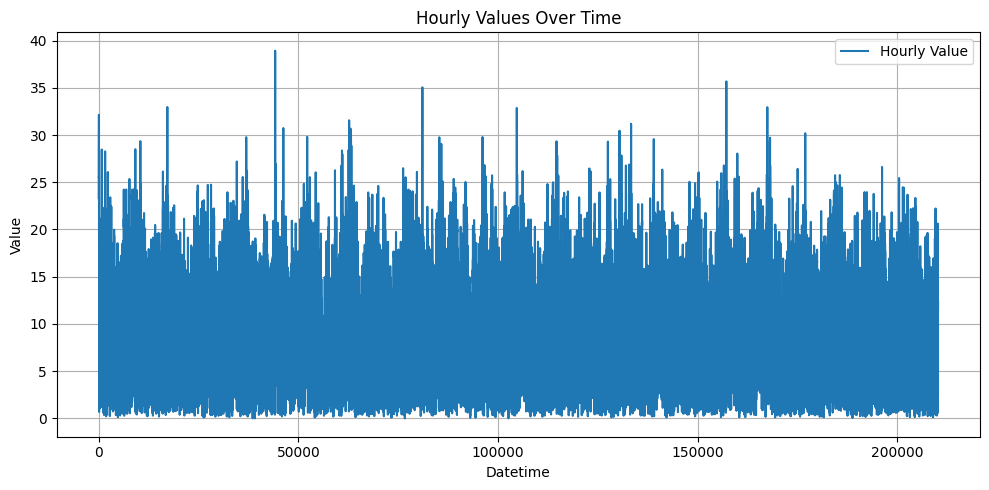

In [12]:
plt.figure(figsize=(10, 5))
plt.plot(df_loc_1.index, df_loc_1['value'], linestyle='-', label='Hourly Value')
plt.xlabel('Datetime')
plt.ylabel('Value')
plt.title('Hourly Values Over Time')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

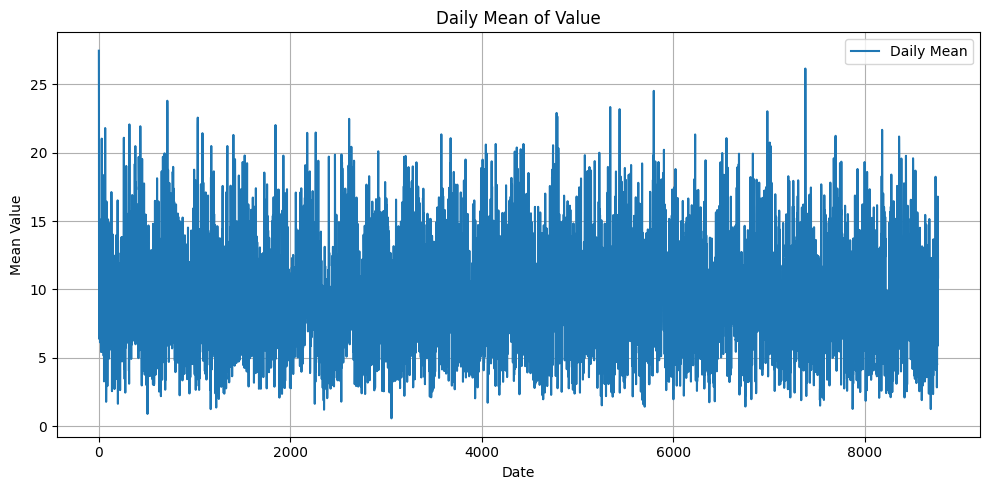

In [13]:
plt.figure(figsize=(10, 5))
plt.plot(df_daily.index, df_daily['value'], linestyle='-', label='Daily Mean')
plt.xlabel('Date')
plt.ylabel('Mean Value')
plt.title('Daily Mean of Value')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
#plt.figure(figsize=(10, 5))
#plt.plot(df_monthly_from_daily.index,df_monthly_from_daily['value'], linestyle='-', label='Monthly Mean')
#plt.xlabel('Month')
#plt.ylabel('Mean Value')
#plt.title('Monthly Mean of Value')
#plt.grid(True)
#plt.legend()
#plt.tight_layout()
#plt.show()

#### hermonisk model

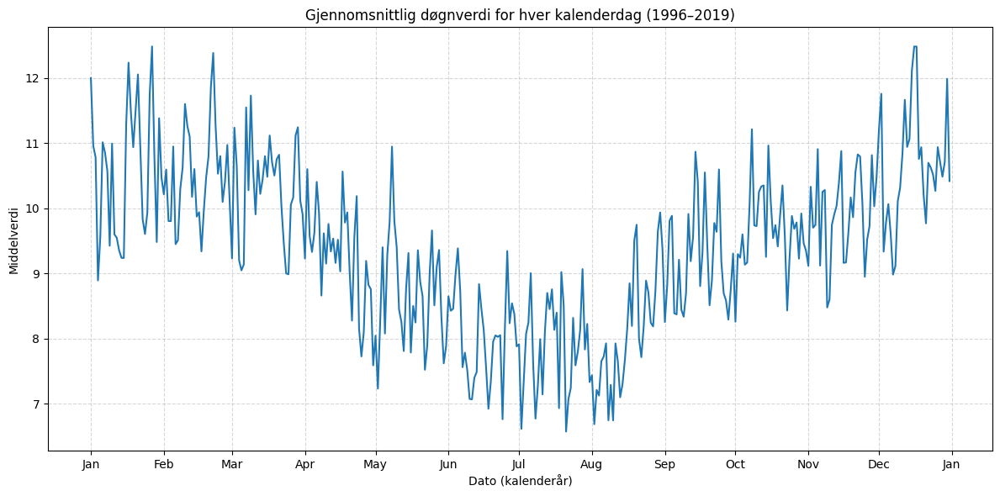

In [15]:
plt.figure(figsize=(12, 6))
plt.plot(dayofyear_mean["date_plot"], dayofyear_mean["value"], linewidth=1.5)
plt.title("Gjennomsnittlig døgnverdi for hver kalenderdag (1996–2019)")
plt.xlabel("Dato (kalenderår)")
plt.ylabel("Middelverdi")

# Tilpass aksene
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

# Formater x-aksen til månednavn
plt.gca().xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b"))
plt.gca().xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator())

plt.show()

In [16]:
dayofyear_mean["day_of_year"] = dayofyear_mean["date_plot"].dt.dayofyear.astype(int)



dayofyear_mean = dayofyear_mean.sort_values("day_of_year")


t = dayofyear_mean["day_of_year"].values.astype(float)
y = dayofyear_mean["value"].values.astype(float)

# cossinus-model 
omega = 2 * np.pi / 365.0
X = np.column_stack([
    np.ones_like(t),
    np.cos(omega * t),
    np.sin(omega * t)
])

beta, *_ = np.linalg.lstsq(X, y, rcond=None)
mu0, mu1, mu2 = beta


dayofyear_mean["value_estimate"] = mu0 + mu1*np.cos(omega * t) + mu2*np.sin(omega * t)

# Residualer
dayofyear_mean["residual"] = (
    dayofyear_mean["value"] - dayofyear_mean["value_estimate"]
)



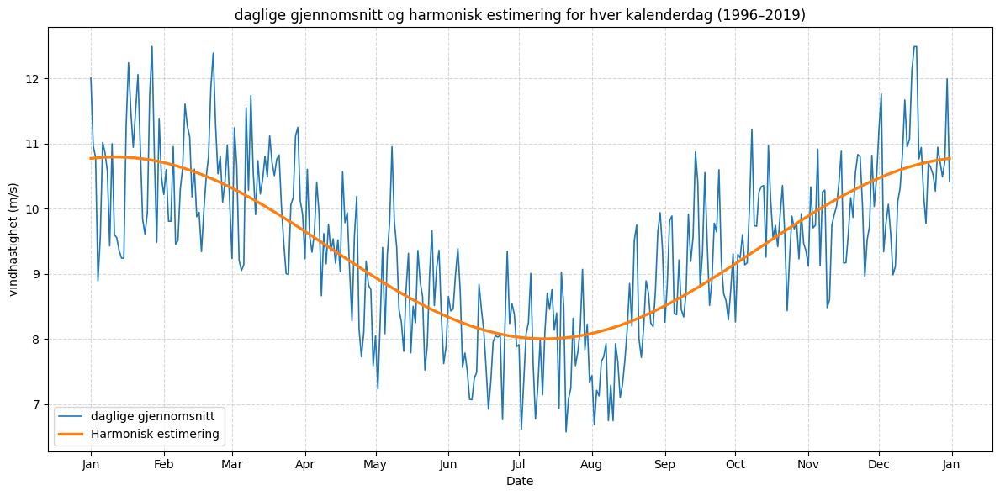

In [17]:
plt.figure(figsize=(12,6))
plt.plot(dayofyear_mean["date_plot"], dayofyear_mean["value"], label="daglige gjennomsnitt", linewidth=1.2)
plt.plot(dayofyear_mean["date_plot"], dayofyear_mean["value_estimate"], label="Harmonisk estimering", linewidth=2.4)
plt.title("daglige gjennomsnitt og harmonisk estimering for hver kalenderdag (1996–2019)")
plt.xlabel("Date")
plt.ylabel("vindhastighet (m/s)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()

# Formater x-aksen til månednavn
plt.gca().xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b"))
plt.gca().xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator())

plt.show()

In [18]:
actual = dayofyear_mean["value"].to_numpy()
estimate = dayofyear_mean["value_estimate"].to_numpy()

# Fjern eventuelle manglende verdier
valid = np.isfinite(actual) & np.isfinite(estimate)
actual = actual[valid]
estimate = estimate[valid]

residuals = dayofyear_mean["residual"]

# Beregn R², MSE, MAE og RMSE ---
r2 = r2_score(actual, estimate)
mse = mean_squared_error(actual, estimate)
mae = mean_absolute_error(actual, estimate)
rmse = np.sqrt(mse)

# Beregn amplituden til sinusmodellen 
amplitude = np.sqrt(mu1**2 + mu2**2)


print("Resultater for sinusmodellen")
print("----------------------------")
print(f"Amplitude: {amplitude:.4f}")
print(f"R²:        {r2:.4f}")
print(f"MSE:       {mse:.4f}")
print(f"MAE:       {mae:.4f}")
print(f"RMSE:      {rmse:.4f}")


print("\nResidualstatistikk")
print("------------------")
print(f"Gjennomsnitt: {np.mean(residuals):.4f}")
print(f"Standardavvik: {np.std(residuals):.4f}")
print(f"Minimum:      {np.min(residuals):.4f}")
print(f"Maksimum:     {np.max(residuals):.4f}")

# Vis de første residualene
print("\nDe første residualene:")
print(dayofyear_mean[["value", "value_estimate", "residual"]])

Resultater for sinusmodellen
----------------------------
Amplitude: 1.3948
R²:        0.6083
MSE:       0.6282
MAE:       0.6327
RMSE:      0.7926

Residualstatistikk
------------------
Gjennomsnitt: -0.0000
Standardavvik: 0.7926
Minimum:      -1.8863
Maksimum:     2.1624

De første residualene:
         value  value_estimate  residual
0    12.000814       10.769811  1.231003
1    10.960847       10.773877  0.186970
2    10.786345       10.777535  0.008809
3     8.894463       10.780784 -1.886321
4     9.562755       10.783623 -1.220868
..         ...             ...       ...
360  10.715034       10.749494 -0.034460
361  10.486721       10.755179 -0.268457
362  10.718514       10.760461 -0.041947
363  11.989831       10.765339  1.224492
364  10.419904       10.769811 -0.349908

[365 rows x 3 columns]


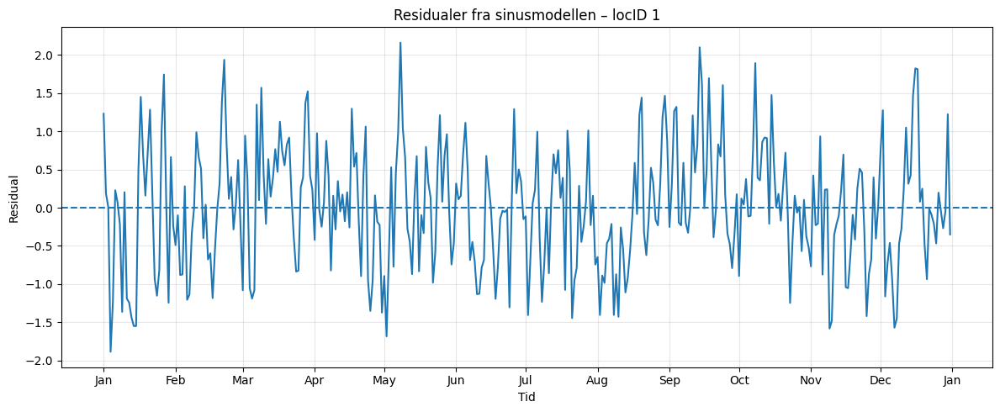

In [19]:
plt.figure(figsize=(12, 5))

plt.plot(dayofyear_mean["date_plot"], dayofyear_mean["residual"], linewidth=1.5)
plt.axhline(y=0, linestyle="--")

plt.title("Residualer fra sinusmodellen – locID 1")
plt.xlabel("Tid")
plt.ylabel("Residual")
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Formater x-aksen til månednavn
plt.gca().xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b"))
plt.gca().xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator())

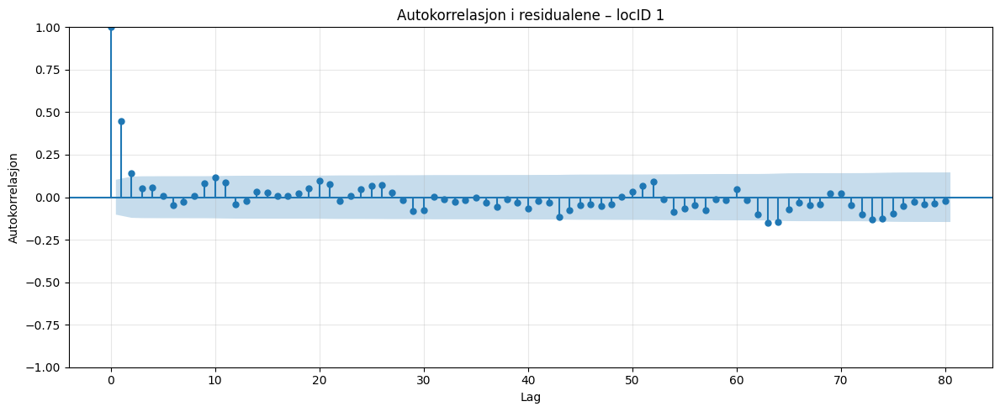

In [20]:
residuals = dayofyear_mean["residual"].dropna()

fig, ax = plt.subplots(figsize=(12, 5))

plot_acf(
    residuals,
    lags=80,
    alpha=0.05,
    ax=ax
)

ax.set_title("Autokorrelasjon i residualene – locID 1")
ax.set_xlabel("Lag")
ax.set_ylabel("Autokorrelasjon")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [21]:
from statsmodels.tsa.stattools import acf

acf_values = acf(
    residuals,
    nlags=80,
    fft=True
)

for lag, value in enumerate(acf_values[:50]):
    print(f"Lag {lag}: {value:.4f}")

Lag 0: 1.0000
Lag 1: 0.4465
Lag 2: 0.1409
Lag 3: 0.0543
Lag 4: 0.0556
Lag 5: 0.0057
Lag 6: -0.0469
Lag 7: -0.0278
Lag 8: 0.0085
Lag 9: 0.0810
Lag 10: 0.1165
Lag 11: 0.0844
Lag 12: -0.0443
Lag 13: -0.0246
Lag 14: 0.0331
Lag 15: 0.0285
Lag 16: 0.0069
Lag 17: 0.0090
Lag 18: 0.0222
Lag 19: 0.0516
Lag 20: 0.0986
Lag 21: 0.0790
Lag 22: -0.0237
Lag 23: 0.0082
Lag 24: 0.0448
Lag 25: 0.0670
Lag 26: 0.0739
Lag 27: 0.0295
Lag 28: -0.0155
Lag 29: -0.0806
Lag 30: -0.0764
Lag 31: 0.0014
Lag 32: -0.0145
Lag 33: -0.0268
Lag 34: -0.0167
Lag 35: -0.0030
Lag 36: -0.0328
Lag 37: -0.0589
Lag 38: -0.0141
Lag 39: -0.0314
Lag 40: -0.0662
Lag 41: -0.0213
Lag 42: -0.0339
Lag 43: -0.1183
Lag 44: -0.0789
Lag 45: -0.0461
Lag 46: -0.0433
Lag 47: -0.0518
Lag 48: -0.0423
Lag 49: 0.0042


[  1.   2.   3. ... 363. 364. 365.]


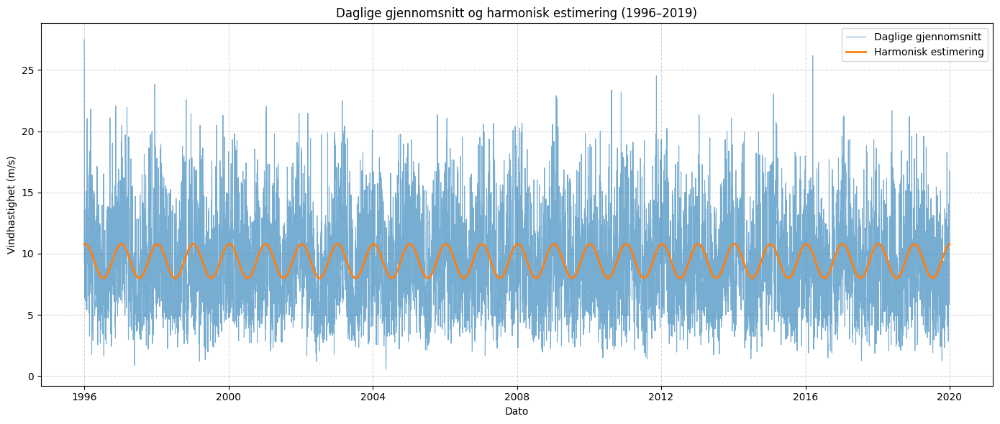

In [22]:
# Kopier datasettet
daily_mean = daily_mean.copy()

# Sørg for riktig datoformat
daily_mean["date"] = pd.to_datetime(daily_mean["date"])

# Kalenderdag (1–365), korrigert for skuddår
daily_mean["day_of_year"] = daily_mean["date"].dt.dayofyear

daily_mean.loc[
    daily_mean["date"].dt.is_leap_year &
    (daily_mean["date"].dt.month > 2),
    "day_of_year"
] -= 1

daily_mean = daily_mean.sort_values("date")

t = daily_mean["day_of_year"].values.astype(float)
print(t)
y = daily_mean["value"].values.astype(float)

# Cosinusmodell
omega = 2 * np.pi / 365.0

X = np.column_stack([
    np.ones_like(t),
    np.cos(omega * t),
    np.sin(omega * t)
])

beta, *_ = np.linalg.lstsq(X, y, rcond=None)

mu0, mu1, mu2 = beta

# Harmonisk estimering
daily_mean["value_estimate"] = (
    mu0
    + mu1 * np.cos(omega * t)
    + mu2 * np.sin(omega * t)
)

# Residualer
daily_mean["residual"] = (
    daily_mean["value"] - daily_mean["value_estimate"]
)

# Plot
plt.figure(figsize=(14, 6))

plt.plot(
    daily_mean["date"],
    daily_mean["value"],
    label="Daglige gjennomsnitt",
    linewidth=0.8,
    alpha=0.6
)

plt.plot(
    daily_mean["date"],
    daily_mean["value_estimate"],
    label="Harmonisk estimering",
    linewidth=2
)

plt.title("Daglige gjennomsnitt og harmonisk estimering (1996–2019)")
plt.xlabel("Dato")
plt.ylabel("Vindhastighet (m/s)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

In [23]:
# Hent residualene
residuals = dayofyear_mean["residual"].dropna()

# Ljung-Box-test
ljung_box = acorr_ljungbox(
    residuals,
    lags=[1, 5, 10, 20, 40, 80],
    return_df=True
)

print(ljung_box)

       lb_stat     lb_pvalue
1    73.356484  1.082260e-17
5    82.930488  2.043512e-16
10   91.657574  2.511147e-15
20  101.104409  7.986620e-13
40  118.492009  1.067612e-09
80  204.588040  7.133818e-13


### hvilken type vind?

In [24]:
categories = [
    ("Stille", 0.0, 0.2),
    ("Flau vind", 0.3, 1.5),
    ("Svak vind", 1.6, 3.3),
    ("Lett bris", 3.4, 5.4),
    ("Laber bris", 5.5, 7.9),
    ("Frisk bris", 8.0, 10.7),
    ("Liten kuling", 10.8, 13.8),
    ("Stiv kuling", 13.9, 17.1),
    ("Sterk kuling", 17.2, 20.7),
    ("Liten storm", 20.8, 24.4),
    ("Full storm", 24.5, 28.4),
    ("Sterk storm", 28.5, 32.6),
    ("Orkan", 32.7, float("inf")),
]
def classify_beaufort(value):
    for name, low, high in categories:
        if low <= value <= high:
            return name
    return None  


df_daily['beaufort_category'] = df_daily['value'].apply(classify_beaufort)

# skriver ut hvor mange observasjoner som faller inn i hver kategori
category_counts = df_daily['beaufort_category'].value_counts().sort_index()

print("Antall observasjoner per vindkategori")
print(category_counts)

Antall observasjoner per vindkategori
beaufort_category
Flau vind         13
Frisk bris      2268
Full storm         3
Laber bris      1975
Lett bris       1086
Liten kuling    1681
Liten storm       30
Sterk kuling     283
Stiv kuling      846
Svak vind        235
Name: count, dtype: int64


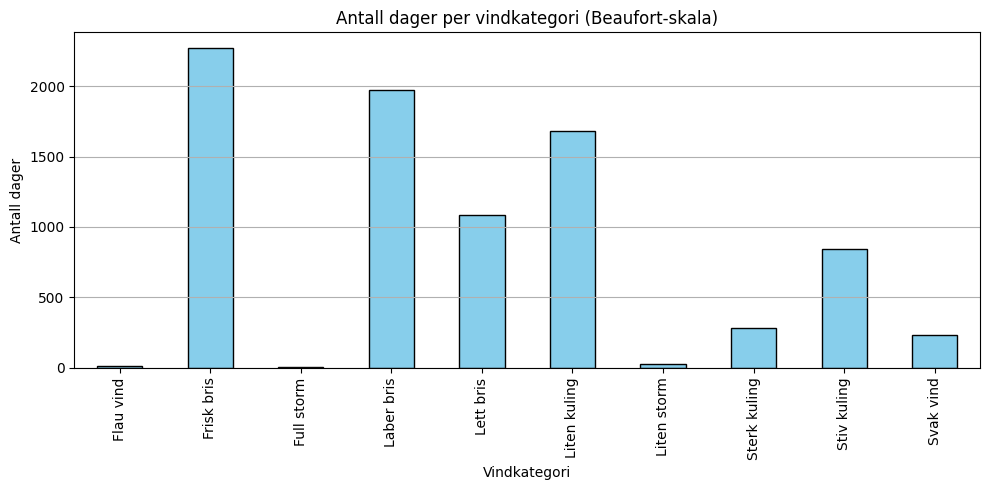

In [25]:
plt.figure(figsize=(10, 5))
category_counts.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title("Antall dager per vindkategori (Beaufort-skala)")
plt.xlabel("Vindkategori")
plt.ylabel("Antall dager")
plt.grid(axis='y')
plt.tight_layout()
plt.show()

### Random forrest 

#### 3 timer

In [26]:
df_rf_3h = df_3h.copy()

df_rf_3h = df_rf_3h.sort_values("datetime").reset_index(drop=True)

In [27]:
# Nåværende vindhastighet
df_rf_3h["lag_0"] = df_rf_3h["value"]

# Tidligere vindhastigheter
for i in range(1, 56):
    df_rf_3h[f"lag_{i}"] = df_rf_3h["value"].shift(i)
    
    print(df_rf_3h[f"lag_{i}"][:10])


0          NaN
1    24.978496
2    24.197471
3    24.593582
4    28.994197
5    31.685537
6    30.881512
7    28.408281
8    25.990288
9    26.180649
Name: lag_1, dtype: float64
0          NaN
1          NaN
2    24.978496
3    24.197471
4    24.593582
5    28.994197
6    31.685537
7    30.881512
8    28.408281
9    25.990288
Name: lag_2, dtype: float64
0          NaN
1          NaN
2          NaN
3    24.978496
4    24.197471
5    24.593582
6    28.994197
7    31.685537
8    30.881512
9    28.408281
Name: lag_3, dtype: float64
0          NaN
1          NaN
2          NaN
3          NaN
4    24.978496
5    24.197471
6    24.593582
7    28.994197
8    31.685537
9    30.881512
Name: lag_4, dtype: float64
0          NaN
1          NaN
2          NaN
3          NaN
4          NaN
5    24.978496
6    24.197471
7    24.593582
8    28.994197
9    31.685537
Name: lag_5, dtype: float64
0          NaN
1          NaN
2          NaN
3          NaN
4          NaN
5          NaN
6    24.978496
7    

datasettet med lag

In [28]:
df_rf_3h

,datetime,value,year,time,name,lat,lon,row,col,locID,...,lag_46,lag_47,lag_48,lag_49,lag_50,lag_51,lag_52,lag_53,lag_54,lag_55
0,1996-01-01 00:00:00,24.978496,1996.0,227904.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1996-01-01 03:00:00,24.197471,1996.0,227907.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1996-01-01 06:00:00,24.593582,1996.0,227910.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1996-01-01 09:00:00,28.994197,1996.0,227913.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1996-01-01 12:00:00,31.685537,1996.0,227916.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70075,2019-12-31 09:00:00,7.034111,2019.0,438273.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,...,3.721027,4.460469,6.304089,7.984519,9.860485,10.569029,11.294613,12.185528,13.538727,14.106755
70076,2019-12-31 12:00:00,4.900157,2019.0,438276.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,...,2.731705,3.721027,4.460469,6.304089,7.984519,9.860485,10.569029,11.294613,12.185528,13.538727
70077,2019-12-31 15:00:00,10.109447,2019.0,438279.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,...,1.220730,2.731705,3.721027,4.460469,6.304089,7.984519,9.860485,10.569029,11.294613,12.185528
70078,2019-12-31 18:00:00,12.140149,2019.0,438282.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,...,1.273953,1.220730,2.731705,3.721027,4.460469,6.304089,7.984519,9.860485,10.569029,11.294613


In [29]:
# 3timer * 8 = 24 timer frem i tid
forecast_steps = 8

df_rf_3h["target"] = df_rf_3h["value"].shift(-forecast_steps)

print(df_rf_3h["target"])

0        26.180649
1        25.852400
2        24.743528
3        24.264119
4        24.272927
           ...    
70075          NaN
70076          NaN
70077          NaN
70078          NaN
70079          NaN
Name: target, Length: 70080, dtype: float64


In [30]:
lag_cols = [f"lag_{i}" for i in range(56)]

#fjernng av alle NaN-verdier i lag-kolonnene og target-kolonnen
df_rf_3h = df_rf_3h.dropna(
    subset=lag_cols + ["target"]
).reset_index(drop=True)

#datasett etter fjerning av NaN-verdier så første uken i datasettet, og siste uken i datasettet, er fjernet
df_rf_3h

,datetime,value,year,time,name,lat,lon,row,col,locID,...,lag_47,lag_48,lag_49,lag_50,lag_51,lag_52,lag_53,lag_54,lag_55,target
0,1996-01-07 21:00:00,10.783874,1996.0,228069.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,...,26.180649,25.990288,28.408281,30.881512,31.685537,28.994197,24.593582,24.197471,24.978496,5.868638
1,1996-01-08 00:00:00,12.718518,1996.0,228072.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,...,25.852400,26.180649,25.990288,28.408281,30.881512,31.685537,28.994197,24.593582,24.197471,6.506585
2,1996-01-08 03:00:00,10.588376,1996.0,228075.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,...,24.743528,25.852400,26.180649,25.990288,28.408281,30.881512,31.685537,28.994197,24.593582,6.763532
3,1996-01-08 06:00:00,5.248115,1996.0,228078.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,...,24.264119,24.743528,25.852400,26.180649,25.990288,28.408281,30.881512,31.685537,28.994197,5.670735
4,1996-01-08 09:00:00,5.939557,1996.0,228081.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,...,24.272927,24.264119,24.743528,25.852400,26.180649,25.990288,28.408281,30.881512,31.685537,8.970940
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70012,2019-12-30 09:00:00,13.200422,2019.0,438249.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,...,14.106755,14.742759,14.853889,14.700569,14.436730,14.152703,13.733670,14.905045,16.074088,7.034111
70013,2019-12-30 12:00:00,13.948476,2019.0,438252.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,...,13.538727,14.106755,14.742759,14.853889,14.700569,14.436730,14.152703,13.733670,14.905045,4.900157
70014,2019-12-30 15:00:00,16.376616,2019.0,438255.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,...,12.185528,13.538727,14.106755,14.742759,14.853889,14.700569,14.436730,14.152703,13.733670,10.109447
70015,2019-12-30 18:00:00,16.320566,2019.0,438258.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,...,11.294613,12.185528,13.538727,14.106755,14.742759,14.853889,14.700569,14.436730,14.152703,12.140149


In [31]:
X = df_rf_3h[lag_cols]
y = df_rf_3h["target"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (70017, 56)
y shape: (70017,)


In [32]:
split = int(len(df_rf_3h) * 0.8)

X_train_rf_3h = X.iloc[:split]
X_test_rf_3h = X.iloc[split:]

y_train_rf_3h = y.iloc[:split]
y_test_rf_3h = y.iloc[split:]

print("Train:", len(X_train_rf_3h))
print("Test:", len(X_test_rf_3h))

Train: 56013
Test: 14004


In [33]:
# random forest-modellen
rf_3h = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)

rf_3h.fit(X_train_rf_3h, y_train_rf_3h)

y_pred_rf_3h = rf_3h.predict(X_test_rf_3h)

In [34]:
mse_rf_3h = mean_squared_error(y_test_rf_3h, y_pred_rf_3h)
rmse_rf_3h = np.sqrt(mse_rf_3h)
mae_rf_3h = mean_absolute_error(y_test_rf_3h, y_pred_rf_3h)
r2_rf_3h = r2_score(y_test_rf_3h, y_pred_rf_3h)

print("Random Forest – 3-timersdata")
print("Prediksjonshorisont: 24 timer")
print("--------------------------------")
print(f"MSE:  {mse_rf_3h:.4f}")
print(f"RMSE: {rmse_rf_3h:.4f}")
print(f"MAE:  {mae_rf_3h:.4f}")
print(f"R²:   {r2_rf_3h:.4f}")

Random Forest – 3-timersdata
Prediksjonshorisont: 24 timer
--------------------------------
MSE:  18.1172
RMSE: 4.2564
MAE:  3.4365
R²:   0.0648


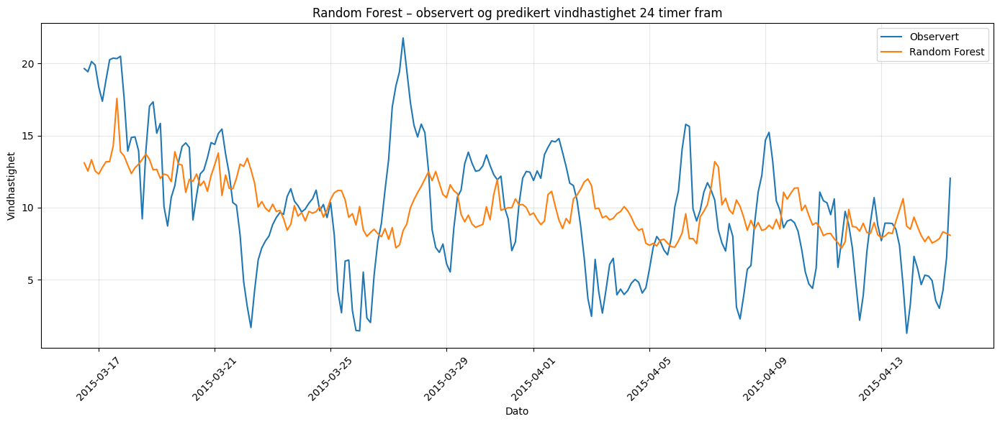

In [35]:
import matplotlib.pyplot as plt
import pandas as pd

# Vis 30 dager
n_plot = 30 * 8

test_dates_rf_3h = (
    df_rf_3h["datetime"].iloc[split:]
    + pd.Timedelta(hours=24)
)

plt.figure(figsize=(14, 6))

plt.plot(
    test_dates_rf_3h.iloc[:n_plot],
    y_test_rf_3h.iloc[:n_plot],
    label="Observert",
    linewidth=1.5
)

plt.plot(
    test_dates_rf_3h.iloc[:n_plot],
    y_pred_rf_3h[:n_plot],
    label="Random Forest",
    linewidth=1.5
)

plt.xlabel("Dato")
plt.ylabel("Vindhastighet")
plt.title(
    "Random Forest – observert og predikert vindhastighet "
    "24 timer fram"
)

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### 6 timer RF

In [36]:
df_rf_6h = df_6h.copy()

df_rf_6h = df_rf_6h.sort_values("datetime").reset_index(drop=True)

In [37]:
# Nåværende vindhastighet
df_rf_6h["lag_0"] = df_rf_6h["value"]

# Tidligere vindhastigheter
#for i in range(1, 29):
for i in range(1, 28):
    df_rf_6h[f"lag_{i}"] = df_rf_6h["value"].shift(i)
    

In [38]:
forecast_steps_6h = 4

df_rf_6h["target"] = df_rf_6h["value"].shift(
    -forecast_steps_6h
)

In [39]:
lag_cols_6h = [f"lag_{i}" for i in range(28)]


df_rf_6h = df_rf_6h.dropna(
    subset=lag_cols_6h + ["target"]
).reset_index(drop=True)

X_6h = df_rf_6h[lag_cols_6h]
y_6h = df_rf_6h["target"]

print("X shape:", X_6h.shape)
print("y shape:", y_6h.shape)

X shape: (35009, 28)
y shape: (35009,)


In [40]:
split_rf_6h = int(len(df_rf_6h) * 0.8)

X_train_rf_6h = X_6h.iloc[:split_rf_6h]
X_test_rf_6h = X_6h.iloc[split_rf_6h:]

y_train_rf_6h = y_6h.iloc[:split_rf_6h]
y_test_rf_6h = y_6h.iloc[split_rf_6h:]

print("Train:", len(X_train_rf_6h))
print("Test:", len(X_test_rf_6h))

Train: 28007
Test: 7002


In [41]:
from sklearn.ensemble import RandomForestRegressor

rf_6h = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)

rf_6h.fit(X_train_rf_6h, y_train_rf_6h)

y_pred_rf_6h = rf_6h.predict(X_test_rf_6h)

In [42]:
mse_rf_6h = mean_squared_error(y_test_rf_6h, y_pred_rf_6h)
rmse_rf_6h = np.sqrt(mse_rf_6h)
mae_rf_6h = mean_absolute_error(y_test_rf_6h, y_pred_rf_6h)
r2_rf_6h = r2_score(y_test_rf_6h, y_pred_rf_6h)

print("Random Forest – 6-timersdata")
print("Prediksjonshorisont: 24 timer")
print("--------------------------------")
print(f"MSE:  {mse_rf_6h:.4f}")
print(f"RMSE: {rmse_rf_6h:.4f}")
print(f"MAE:  {mae_rf_6h:.4f}")
print(f"R²:   {r2_rf_6h:.4f}")

Random Forest – 6-timersdata
Prediksjonshorisont: 24 timer
--------------------------------
MSE:  17.3007
RMSE: 4.1594
MAE:  3.3639
R²:   0.0661


In [43]:
y_persistence_6h = X_test_rf_6h["lag_0"].to_numpy()

p_rmse_6h = np.sqrt(
    mean_squared_error(y_test_rf_6h, y_persistence_6h)
)

p_mae_6h = mean_absolute_error(
    y_test_rf_6h,
    y_persistence_6h
)

p_r2_6h = r2_score(
    y_test_rf_6h,
    y_persistence_6h
)

print("Persistence – 6-timersdata")
print("--------------------------------")
print(f"RMSE: {p_rmse_6h:.4f}")
print(f"MAE:  {p_mae_6h:.4f}")
print(f"R²:   {p_r2_6h:.4f}")

Persistence – 6-timersdata
--------------------------------
RMSE: 5.2808
MAE:  4.1770
R²:   -0.5053


Text(0.5, 1.0, 'Random Forest – 6-timersdata\nFørste 30 dager av testperioden, 24 timers prediksjon')

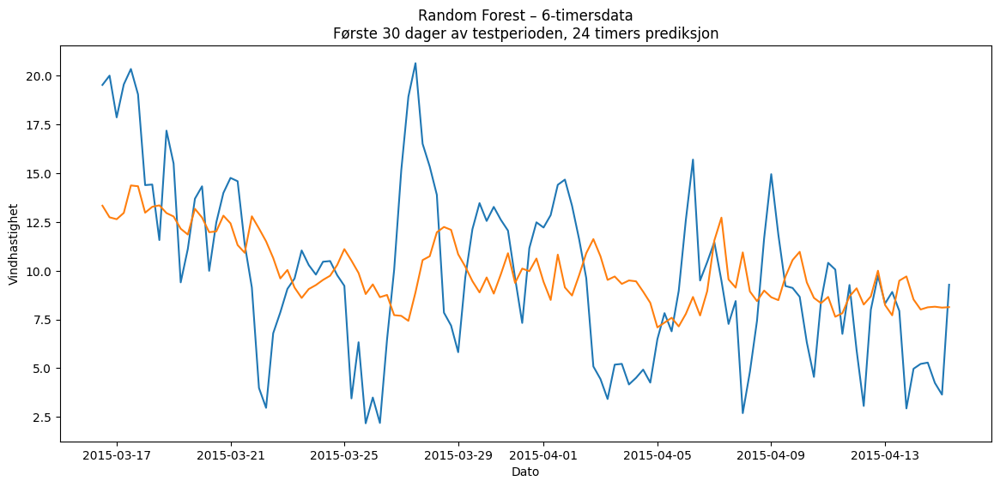

In [44]:
n_plot_6h = 30 * 4

test_dates_rf_6h = (
    df_rf_6h["datetime"].iloc[split_rf_6h:]
    + pd.Timedelta(hours=24)
)

plt.figure(figsize=(14, 6))

plt.plot(
    test_dates_rf_6h.iloc[:n_plot_6h],
    y_test_rf_6h.iloc[:n_plot_6h],
    label="Observert",
    linewidth=1.5
)

plt.plot(
    test_dates_rf_6h.iloc[:n_plot_6h],
    y_pred_rf_6h[:n_plot_6h],
    label="Random Forest",
    linewidth=1.5
)

plt.xlabel("Dato")
plt.ylabel("Vindhastighet")
plt.title(
    "Random Forest – 6-timersdata\n"
    "Første 30 dager av testperioden, "
    "24 timers prediksjon"
)

#### 12 timer RF

In [45]:
df_rf_12h = df_12h.copy()

df_rf_12h = (
    df_rf_12h
    .sort_values("datetime")
    .reset_index(drop=True)
)

In [46]:
df_rf_12h["lag_0"] = df_rf_12h["value"]

for i in range(1, 14):
    df_rf_12h[f"lag_{i}"] = df_rf_12h["value"].shift(i)

In [47]:
forecast_steps_12h = 2

df_rf_12h["target"] = df_rf_12h["value"].shift(
    -forecast_steps_12h
)

In [48]:
lag_cols_12h = [f"lag_{i}" for i in range(14)]

df_rf_12h = df_rf_12h.dropna(
    subset=lag_cols_12h + ["target"]
).reset_index(drop=True)

X_rf_12h = df_rf_12h[lag_cols_12h]
y_rf_12h = df_rf_12h["target"]

print("X shape:", X_rf_12h.shape)
print("y shape:", y_rf_12h.shape)


X shape: (17505, 14)
y shape: (17505,)


In [49]:
split_rf_12h = int(len(df_rf_12h) * 0.8)

X_train_rf_12h = X_rf_12h.iloc[:split_rf_12h]
X_test_rf_12h = X_rf_12h.iloc[split_rf_12h:]

y_train_rf_12h = y_rf_12h.iloc[:split_rf_12h]
y_test_rf_12h = y_rf_12h.iloc[split_rf_12h:]

print("Train:", len(X_train_rf_12h))
print("Test:", len(X_test_rf_12h))


Train: 14004
Test: 3501


In [50]:
rf_12h = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)

rf_12h.fit(X_train_rf_12h, y_train_rf_12h)

y_pred_rf_12h = rf_12h.predict(X_test_rf_12h)

In [51]:
mse_rf_12h = mean_squared_error(
    y_test_rf_12h,
    y_pred_rf_12h
)

rmse_rf_12h = np.sqrt(mse_rf_12h)

mae_rf_12h = mean_absolute_error(
    y_test_rf_12h,
    y_pred_rf_12h
)

r2_rf_12h = r2_score(
    y_test_rf_12h,
    y_pred_rf_12h
)

print("Random Forest – 12-timersdata")
print("Prediksjonshorisont: 24 timer")
print("--------------------------------")
print(f"MSE:  {mse_rf_12h:.4f}")
print(f"RMSE: {rmse_rf_12h:.4f}")
print(f"MAE:  {mae_rf_12h:.4f}")
print(f"R²:   {r2_rf_12h:.4f}")

Random Forest – 12-timersdata
Prediksjonshorisont: 24 timer
--------------------------------
MSE:  15.5725
RMSE: 3.9462
MAE:  3.2028
R²:   0.0715


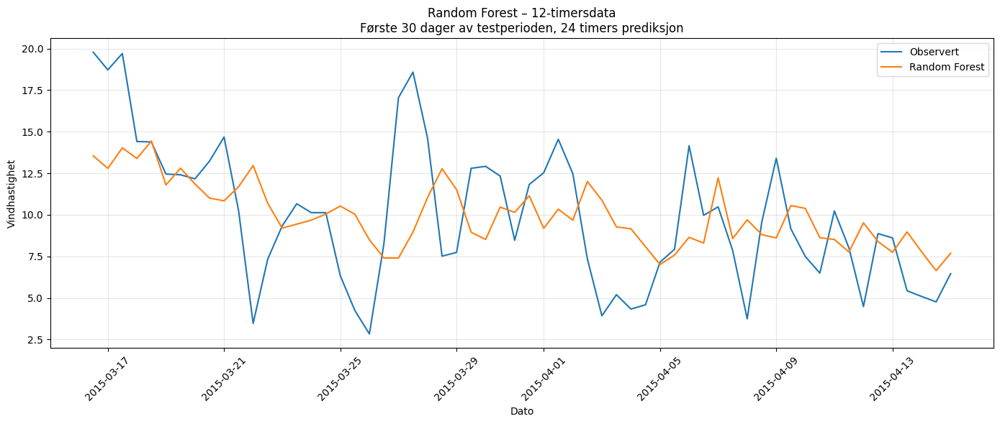

In [52]:
n_plot_12h = 30 * 2

test_dates_rf_12h = (
    df_rf_12h["datetime"].iloc[split_rf_12h:]
    + pd.Timedelta(hours=24)
)

plt.figure(figsize=(14, 6))

plt.plot(
    test_dates_rf_12h.iloc[:n_plot_12h],
    y_test_rf_12h.iloc[:n_plot_12h],
    label="Observert",
    linewidth=1.5
)

plt.plot(
    test_dates_rf_12h.iloc[:n_plot_12h],
    y_pred_rf_12h[:n_plot_12h],
    label="Random Forest",
    linewidth=1.5
)

plt.xlabel("Dato")
plt.ylabel("Vindhastighet")

plt.title(
    "Random Forest – 12-timersdata\n"
    "Første 30 dager av testperioden, "
    "24 timers prediksjon"
)

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

#### daglig

In [53]:
df_rf_daily = df_daily.copy()

df_rf_daily = (
    df_rf_daily
    .sort_values("datetime")
    .reset_index(drop=True)
)

In [54]:
# Vindhastigheten i dag
df_rf_daily["lag_0"] = df_rf_daily["value"]

# De foregående 6 dagene
for i in range(1, 7):
    df_rf_daily[f"lag_{i}"] = df_rf_daily["value"].shift(i)

In [55]:
forecast_steps_daily = 1

df_rf_daily["target"] = df_rf_daily["value"].shift(
    -forecast_steps_daily
)

In [56]:
lag_cols_daily = [f"lag_{i}" for i in range(7)]

df_rf_daily = df_rf_daily.dropna(
    subset=lag_cols_daily + ["target"]
).reset_index(drop=True)

X_rf_daily = df_rf_daily[lag_cols_daily]
y_rf_daily = df_rf_daily["target"]

print("X shape:", X_rf_daily.shape)
print("y shape:", y_rf_daily.shape)

X shape: (8753, 7)
y shape: (8753,)


In [57]:
split_rf_daily = int(len(df_rf_daily) * 0.8)

X_train_rf_daily = X_rf_daily.iloc[:split_rf_daily]
X_test_rf_daily = X_rf_daily.iloc[split_rf_daily:]

y_train_rf_daily = y_rf_daily.iloc[:split_rf_daily]
y_test_rf_daily = y_rf_daily.iloc[split_rf_daily:]

print("Train:", len(X_train_rf_daily))
print("Test:", len(X_test_rf_daily))

Train: 7002
Test: 1751


In [58]:
rf_daily = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)

rf_daily.fit(
    X_train_rf_daily,
    y_train_rf_daily
)

y_pred_rf_daily = rf_daily.predict(X_test_rf_daily)

In [59]:
mse_rf_daily = mean_squared_error(
    y_test_rf_daily,
    y_pred_rf_daily
)

rmse_rf_daily = np.sqrt(mse_rf_daily)

mae_rf_daily = mean_absolute_error(
    y_test_rf_daily,
    y_pred_rf_daily
)

r2_rf_daily = r2_score(
    y_test_rf_daily,
    y_pred_rf_daily
)

print("Random Forest – daglige data")
print("Prediksjonshorisont: 24 timer")
print("--------------------------------")
print(f"MSE:  {mse_rf_daily:.4f}")
print(f"RMSE: {rmse_rf_daily:.4f}")
print(f"MAE:  {mae_rf_daily:.4f}")
print(f"R²:   {r2_rf_daily:.4f}")

Random Forest – daglige data
Prediksjonshorisont: 24 timer
--------------------------------
MSE:  11.5114
RMSE: 3.3928
MAE:  2.7569
R²:   0.1464


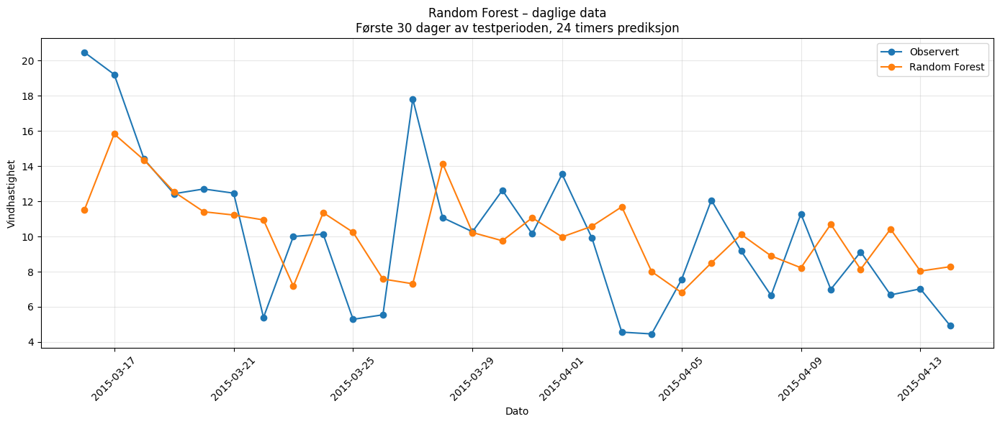

In [60]:

n_plot_daily = 30

test_dates_rf_daily = (
    pd.to_datetime(
        df_rf_daily["datetime"].iloc[split_rf_daily:]
    )
    + pd.Timedelta(days=1)
)

plt.figure(figsize=(14, 6))

plt.plot(
    test_dates_rf_daily.iloc[:n_plot_daily],
    y_test_rf_daily.iloc[:n_plot_daily],
    label="Observert",
    marker="o",
    linewidth=1.5
)

plt.plot(
    test_dates_rf_daily.iloc[:n_plot_daily],
    y_pred_rf_daily[:n_plot_daily],
    label="Random Forest",
    marker="o",
    linewidth=1.5
)

plt.xlabel("Dato")
plt.ylabel("Vindhastighet")

plt.title(
    "Random Forest – daglige data\n"
    "Første 30 dager av testperioden, "
    "24 timers prediksjon"
)

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [61]:
rf_results = pd.DataFrame({
    "Tidsoppløsning": ["3 timer", "6 timer", "12 timer", "Daglig"],
    "MSE": [
        mse_rf_3h,
        mse_rf_6h,
        mse_rf_12h,
        mse_rf_daily
    ],
    "RMSE": [
        rmse_rf_3h,
        rmse_rf_6h,
        rmse_rf_12h,
        rmse_rf_daily
    ],
    "MAE": [
        mae_rf_3h,
        mae_rf_6h,
        mae_rf_12h,
        mae_rf_daily
    ],
    "R²": [
        r2_rf_3h,
        r2_rf_6h,
        r2_rf_12h,
        r2_rf_daily
    ]
})

print(rf_results.round(4))

  Tidsoppløsning      MSE    RMSE     MAE      R²
0        3 timer  18.1172  4.2564  3.4365  0.0648
1        6 timer  17.3007  4.1594  3.3639  0.0661
2       12 timer  15.5725  3.9462  3.2028  0.0715
3         Daglig  11.5114  3.3928  2.7569  0.1464


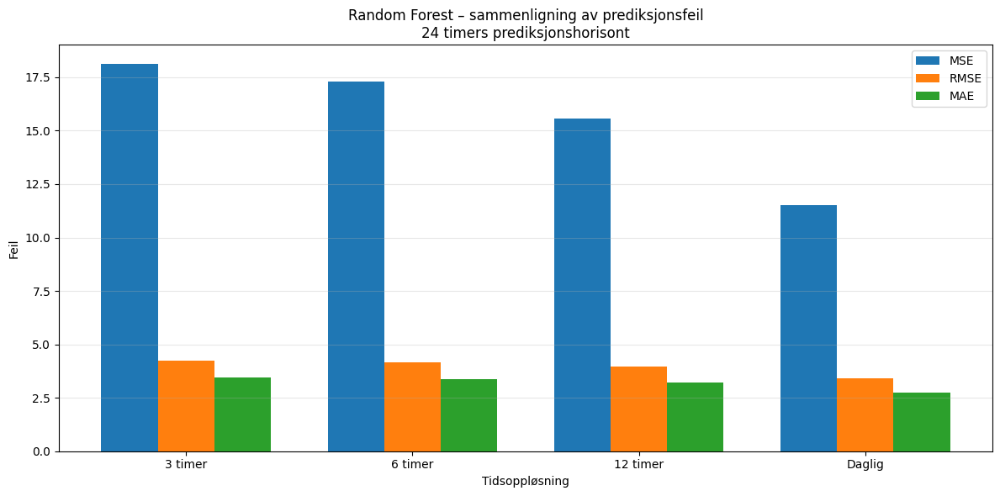

In [62]:
metrics = ["MSE", "RMSE", "MAE"]

x = np.arange(len(rf_results))
width = 0.25

plt.figure(figsize=(12, 6))

for i, metric in enumerate(metrics):
    plt.bar(
        x + (i - 1) * width,
        rf_results[metric],
        width,
        label=metric
    )

plt.xticks(
    x,
    rf_results["Tidsoppløsning"]
)

plt.xlabel("Tidsoppløsning")
plt.ylabel("Feil")
plt.title(
    "Random Forest – sammenligning av prediksjonsfeil\n"
    "24 timers prediksjonshorisont"
)

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

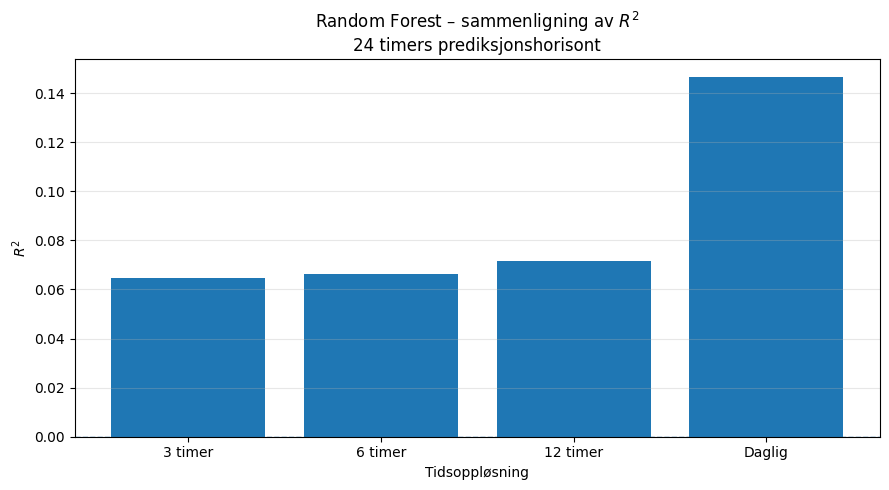

In [63]:
plt.figure(figsize=(9, 5))

plt.bar(
    rf_results["Tidsoppløsning"],
    rf_results["R²"]
)

plt.xlabel("Tidsoppløsning")
plt.ylabel(r"$R^2$")
plt.title(
    "Random Forest – sammenligning av $R^2$\n"
    "24 timers prediksjonshorisont"
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

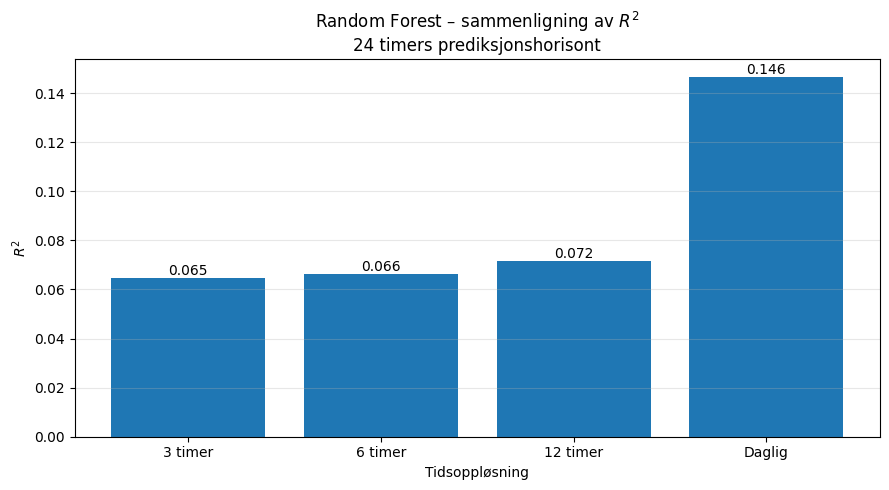

In [64]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    rf_results["Tidsoppløsning"],
    rf_results["R²"]
)

for bar, value in zip(bars, rf_results["R²"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Tidsoppløsning")
plt.ylabel(r"$R^2$")
plt.title(
    "Random Forest – sammenligning av $R^2$\n"
    "24 timers prediksjonshorisont"
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Men det er én viktig ting når du tolker denne sammenligningen: df_daily er mye mer aggregert enn df_3h. Daglige gjennomsnitt glatter ut mye av den kortsiktige variasjonen i vindhastigheten. Derfor kan daily-modellen få lavere RMSE/MAE og høyere \(R^2\) uten at det automatisk betyr at daglig oppløsning er «bedre» i alle betydninger. Det er nettopp dette som kan bli et interessant resultat i masteroppgaven.

#### sesong daily


##### cossinus estimatnen

In [65]:
df_rf_season = daily_mean[["date", "value"]].copy()

df_rf_season["date"] = pd.to_datetime(df_rf_season["date"])

df_rf_season = (
    df_rf_season
    .sort_values("date")
    .reset_index(drop=True)
)

print(df_rf_season.head())

        date      value
0 1996-01-01  27.466171
1 1996-01-02  22.795527
2 1996-01-03   9.255732
3 1996-01-04  13.591242
4 1996-01-05  12.153363


In [66]:
split = int(len(df_rf_season) * 0.8)

train_rf_season = df_rf_season.iloc[:split].copy()
test_rf_season = df_rf_season.iloc[split:].copy()

print("Train:", train_rf_season["date"].min(), "til", train_rf_season["date"].max())
print("Test:", test_rf_season["date"].min(), "til", test_rf_season["date"].max())

Train: 1996-01-01 00:00:00 til 2015-03-14 00:00:00
Test: 2015-03-15 00:00:00 til 2019-12-31 00:00:00


In [67]:
train_rf_season["month"] = train_rf_season["date"].dt.month
train_rf_season["day"] = train_rf_season["date"].dt.day

test_rf_season["month"] = test_rf_season["date"].dt.month
test_rf_season["day"] = test_rf_season["date"].dt.day

In [68]:
train_rf_calendar = (
    train_rf_season
    .groupby(["month", "day"], as_index=False)["value"]
    .mean()
)

train_rf_calendar["day_of_year"] = np.arange(365)

In [69]:
t = train_rf_calendar["day_of_year"].to_numpy()

X_sinus = np.column_stack([
    np.ones(len(t)),
    np.cos(2 * np.pi * t / 365),
    np.sin(2 * np.pi * t / 365)
])

y_sinus = train_rf_calendar["value"].to_numpy()

beta = np.linalg.lstsq(
    X_sinus,
    y_sinus,
    rcond=None
)[0]

mu0, mu1, mu2 = beta

print("mu0:", mu0)
print("mu1:", mu1)
print("mu2:", mu2)


mu0: 9.463101051806973
mu1: 1.471393880763345
mu2: 0.16550068845733346


In [70]:
calendar_lookup = train_rf_calendar[["month", "day", "day_of_year"]].copy()

t_all = calendar_lookup["day_of_year"].to_numpy()

calendar_lookup["value_estimate"] = (
    mu0
    + mu1 * np.cos(2 * np.pi * t_all / 365)
    + mu2 * np.sin(2 * np.pi * t_all / 365)
)

In [71]:
df_rf_season["month"] = df_rf_season["date"].dt.month
df_rf_season["day"] = df_rf_season["date"].dt.day

df_rf_season = df_rf_season.merge(
    calendar_lookup[
        ["month", "day", "value_estimate"]
    ],
    on=["month", "day"],
    how="left"
)

In [72]:
print(
    df_rf_season[
        ["date", "value", "value_estimate"]
    ].head()
)

        date      value  value_estimate
0 1996-01-01  27.466171       10.934495
1 1996-01-02  22.795527       10.937126
2 1996-01-03   9.255732       10.939320
3 1996-01-04  13.591242       10.941076
4 1996-01-05  12.153363       10.942395


In [73]:
df_rf_season["residual"] = (
    df_rf_season["value"]
    - df_rf_season["value_estimate"]
)

##### start av trening av modell og RF modellen

fjerning av første og siste uke av datasettet

In [74]:
df_rf_season["lag_0"] = df_rf_season["residual"]

for i in range(1, 7):
    df_rf_season[f"lag_{i}"] = (
        df_rf_season["residual"].shift(i)
    )

lag_cols_season = [
    f"lag_{i}" for i in range(7)
]

In [75]:
df_rf_season["target_residual"] = (
    df_rf_season["residual"].shift(-1)
)

df_rf_season["target_season"] = (
    df_rf_season["value_estimate"].shift(-1)
)

df_rf_season["target_value"] = (
    df_rf_season["value"].shift(-1)
)

In [76]:
df_rf_season = df_rf_season.dropna(
    subset=(
        lag_cols_season
        + [
            "target_residual",
            "target_season",
            "target_value"
        ]
    )
).reset_index(drop=True)

In [77]:
X_rf_season = df_rf_season[lag_cols_season]
y_rf_residual = df_rf_season["target_residual"]

split_rf_season = int(len(df_rf_season) * 0.8)

X_train_rf_season = X_rf_season.iloc[:split_rf_season]
X_test_rf_season = X_rf_season.iloc[split_rf_season:]

y_train_rf_residual = y_rf_residual.iloc[:split_rf_season]
y_test_rf_residual = y_rf_residual.iloc[split_rf_season:]

y_test_rf_season = (
    df_rf_season["target_value"]
    .iloc[split_rf_season:]
)

season_rf_test = (
    df_rf_season["target_season"]
    .iloc[split_rf_season:]
)

In [78]:
rf_season = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)

rf_season.fit(
    X_train_rf_season,
    y_train_rf_residual
)

RandomForestRegressor(max_depth=20, max_features=0.7, min_samples_leaf=2,
                      min_samples_split=5, n_estimators=200, n_jobs=-1,
                      random_state=42)

In [79]:
residual_rf_pred = rf_season.predict(
    X_test_rf_season
)

In [80]:
y_pred_rf_season = (
    residual_rf_pred
    + season_rf_test.to_numpy()
)

In [81]:
mse_rf_season = mean_squared_error(
    y_test_rf_season,
    y_pred_rf_season
)

rmse_rf_season = np.sqrt(mse_rf_season)

mae_rf_season = mean_absolute_error(
    y_test_rf_season,
    y_pred_rf_season
)

r2_rf_season = r2_score(
    y_test_rf_season,
    y_pred_rf_season
)

print("Random Forest – Daily med sesongjustering")
print("Prediksjonshorisont: 24 timer")
print("--------------------------------")
print(f"MSE:  {mse_rf_season:.4f}")
print(f"RMSE: {rmse_rf_season:.4f}")
print(f"MAE:  {mae_rf_season:.4f}")
print(f"R²:   {r2_rf_season:.4f}")

Random Forest – Daily med sesongjustering
Prediksjonshorisont: 24 timer
--------------------------------
MSE:  11.4261
RMSE: 3.3803
MAE:  2.7239
R²:   0.1528


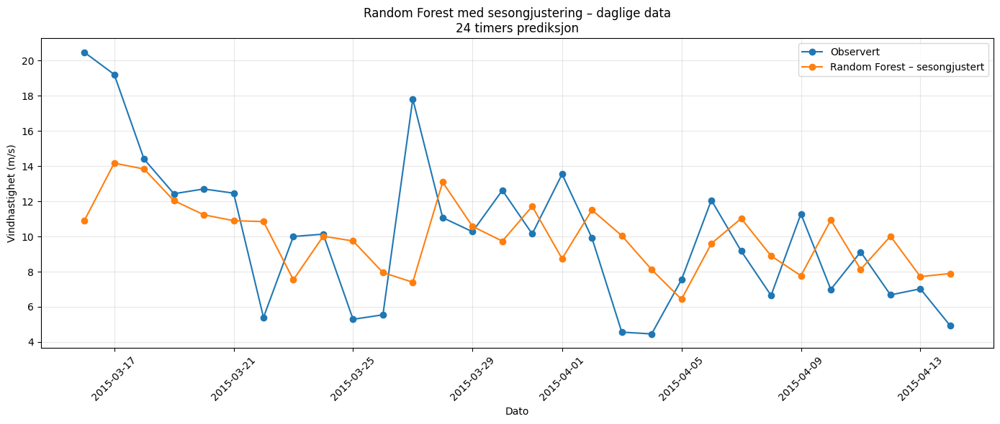

In [82]:
# Datoen som faktisk predikeres
test_dates_rf_season = (
    pd.to_datetime(df_rf_season["date"])
    .shift(-1)
    .iloc[split_rf_season:]
)

# Første 30 prediksjoner
n_plot_season = 30

plt.figure(figsize=(14, 6))

plt.plot(
    test_dates_rf_season.iloc[:n_plot_season],
    y_test_rf_season.iloc[:n_plot_season],
    label="Observert",
    marker="o",
    linewidth=1.5
)

plt.plot(
    test_dates_rf_season.iloc[:n_plot_season],
    y_pred_rf_season[:n_plot_season],
    label="Random Forest – sesongjustert",
    marker="o",
    linewidth=1.5
)

plt.xlabel("Dato")
plt.ylabel("Vindhastighet (m/s)")

plt.title(
    "Random Forest med sesongjustering – daglige data\n"
    "24 timers prediksjon"
)

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "rf_daily_season_prediction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [83]:
df_rf_season["target_date"] = (
    df_rf_season["date"].shift(-1)
)

In [84]:
df_rf_season = df_rf_season.dropna(
    subset=(
        lag_cols_season
        + [
            "target_residual",
            "target_season",
            "target_value",
            "target_date"
        ]
    )
).reset_index(drop=True)

##### sammenliggsplott 

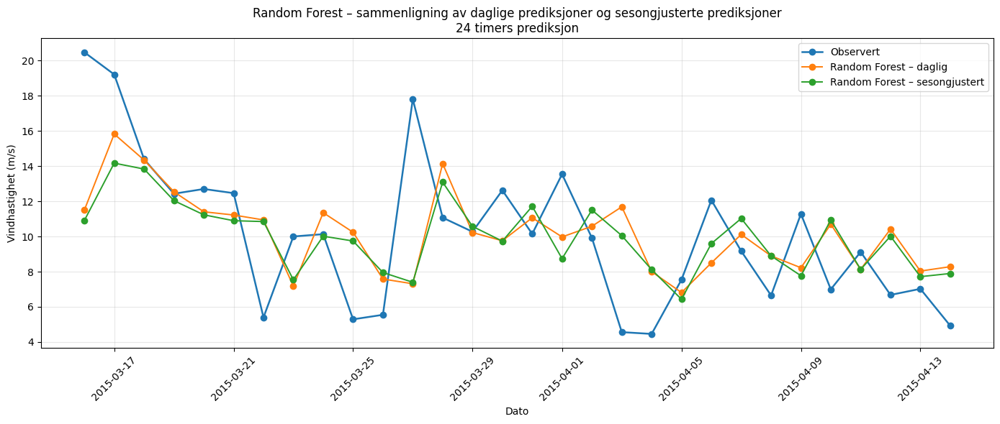

In [85]:
n_plot = 30

plt.figure(figsize=(14, 6))

plt.plot(
    test_dates_rf_season.iloc[:n_plot],
    y_test_rf_season.iloc[:n_plot],
    label="Observert",
    marker="o",
    linewidth=1.8
)

plt.plot(
    test_dates_rf_daily.iloc[:n_plot],
    y_pred_rf_daily[:n_plot],
    label="Random Forest – daglig",
    marker="o",
    linewidth=1.4
)

plt.plot(
    test_dates_rf_season.iloc[:n_plot],
    y_pred_rf_season[:n_plot],
    label="Random Forest – sesongjustert",
    marker="o",
    linewidth=1.4
)

plt.xlabel("Dato")
plt.ylabel("Vindhastighet (m/s)")

plt.title(
    "Random Forest – sammenligning av daglige prediksjoner og sesongjusterte prediksjoner\n"
    "24 timers prediksjon"
)

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "rf_daily_season_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [86]:

rf_results = pd.DataFrame({
    "Tidsoppløsning": ["3 timer", "6 timer", "12 timer", "Daglig","Sesongjustert Daglig"],
    "MSE": [
        mse_rf_3h,
        mse_rf_6h,
        mse_rf_12h,
        mse_rf_daily,
        mse_rf_season
    ],
    "RMSE": [
        rmse_rf_3h,
        rmse_rf_6h,
        rmse_rf_12h,
        rmse_rf_daily,
        rmse_rf_season
    ],
    "MAE": [
        mae_rf_3h,
        mae_rf_6h,
        mae_rf_12h,
        mae_rf_daily,
        mae_rf_season
    ],
    "R²": [
        r2_rf_3h,
        r2_rf_6h,
        r2_rf_12h,
        r2_rf_daily,
        r2_rf_season
    ]
})

print(rf_results.round(4))

         Tidsoppløsning      MSE    RMSE     MAE      R²
0               3 timer  18.1172  4.2564  3.4365  0.0648
1               6 timer  17.3007  4.1594  3.3639  0.0661
2              12 timer  15.5725  3.9462  3.2028  0.0715
3                Daglig  11.5114  3.3928  2.7569  0.1464
4  Sesongjustert Daglig  11.4261  3.3803  2.7239  0.1528


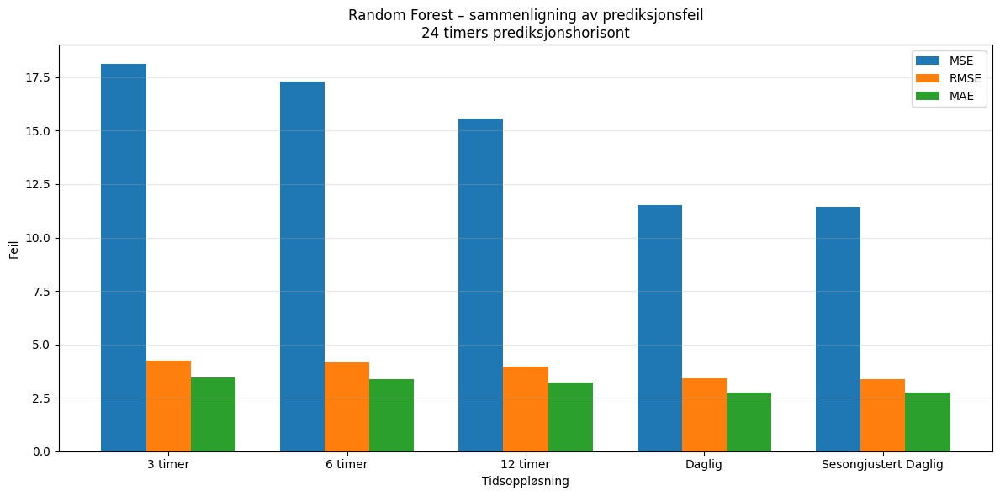

In [87]:
metrics = ["MSE", "RMSE", "MAE"]

x = np.arange(len(rf_results))
width = 0.25

plt.figure(figsize=(12, 6))

for i, metric in enumerate(metrics):
    plt.bar(
        x + (i - 1) * width,
        rf_results[metric],
        width,
        label=metric
    )

plt.xticks(
    x,
    rf_results["Tidsoppløsning"]
)

plt.xlabel("Tidsoppløsning")
plt.ylabel("Feil")
plt.title(
    "Random Forest – sammenligning av prediksjonsfeil\n"
    "24 timers prediksjonshorisont"
)

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

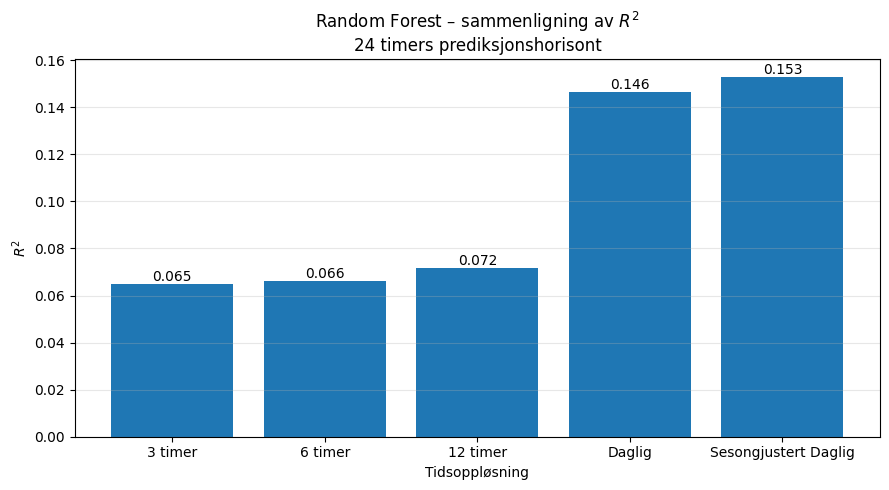

In [88]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    rf_results["Tidsoppløsning"],
    rf_results["R²"]
)

for bar, value in zip(bars, rf_results["R²"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Tidsoppløsning")
plt.ylabel(r"$R^2$")
plt.title(
    "Random Forest – sammenligning av $R^2$\n"
    "24 timers prediksjonshorisont"
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### AUTO REG

#### Auto reg for 3 timer

In [89]:
df_ar_3h = df_3h.copy()

df_ar_3h = (
    df_ar_3h
    .sort_values("datetime")
    .reset_index(drop=True)
)

series_3h = df_ar_3h["value"].astype(float)

print("Antall observasjoner:", len(series_3h))
print(series_3h.head())

Antall observasjoner: 70080
0    24.978496
1    24.197471
2    24.593582
3    28.994197
4    31.685537
Name: value, dtype: float64


In [90]:
split_ar_3h = int(len(series_3h) * 0.8)

train_ar_3h = series_3h.iloc[:split_ar_3h]
test_ar_3h = series_3h.iloc[split_ar_3h:]

print("Treningsobservasjoner:", len(train_ar_3h))
print("Testobservasjoner:", len(test_ar_3h))

Treningsobservasjoner: 56064
Testobservasjoner: 14016


In [91]:


# Modellinnstillinger
p = 56       # 56 lag = 7 døgn
h = 8        # 8 steg = 24 timer

ar_3h = AutoReg(
    train_ar_3h,
    lags=p,
    trend="c",
)

ar_result_3h = ar_3h.fit()

print(ar_result_3h.summary())

                            AutoReg Model Results                             
Dep. Variable:                  value   No. Observations:                56064
Model:                    AutoReg(56)   Log Likelihood             -109653.210
Method:               Conditional MLE   S.D. of innovations              1.714
Date:                Mon, 16 Nov 2026   AIC                         219422.421
Time:                        00:38:02   BIC                         219940.549
Sample:                            56   HQIC                        219583.871
                                56064                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.7554      0.031     24.006      0.000       0.694       0.817
value.L1       1.2933      0.004    306.062      0.000       1.285       1.302
value.L2      -0.4978      0.007    -72.053      0.0

In [92]:
h = 8

# Estimerte parametere fra AR-modellen
params = ar_result_3h.params.to_numpy()

c = params[0]
phi = params[1:]

values = series_3h.to_numpy()

predictions_ar_3h = []
actual_ar_3h = []
dates_ar_3h = []

for t in range(split_ar_3h - 1, len(values) - h):

    # Siste 56 kjente observasjoner
    history = list(values[t - p + 1:t + 1])

    # Rekursiv prognose 8 steg fram
    for step in range(h):
        lag_values = np.array(history[-p:][::-1])

        next_pred = c + np.dot(phi, lag_values)

        history.append(next_pred)

    # Prognose for t + 8
    predictions_ar_3h.append(history[-1])

    # Faktisk verdi ved t + 8
    actual_ar_3h.append(values[t + h])

    dates_ar_3h.append(
        df_ar_3h["datetime"].iloc[t + h]
    )

y_pred_ar_3h = np.array(predictions_ar_3h)
y_test_ar_3h = np.array(actual_ar_3h)

dates_ar_3h = pd.to_datetime(dates_ar_3h)

In [93]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

mse_ar_3h = mean_squared_error(
    y_test_ar_3h,
    y_pred_ar_3h
)

rmse_ar_3h = np.sqrt(mse_ar_3h)

mae_ar_3h = mean_absolute_error(
    y_test_ar_3h,
    y_pred_ar_3h
)

r2_ar_3h = r2_score(
    y_test_ar_3h,
    y_pred_ar_3h
)

print("Autoregressiv modell – 3-timersdata")
print("Modell: AR(56)")
print("Prediksjonshorisont: 24 timer")
print("--------------------------------")
print(f"MSE:  {mse_ar_3h:.4f}")
print(f"RMSE: {rmse_ar_3h:.4f}")
print(f"MAE:  {mae_ar_3h:.4f}")
print(f"R²:   {r2_ar_3h:.4f}")

Autoregressiv modell – 3-timersdata
Modell: AR(56)
Prediksjonshorisont: 24 timer
--------------------------------
MSE:  18.3169
RMSE: 4.2798
MAE:  3.4624
R²:   0.0568


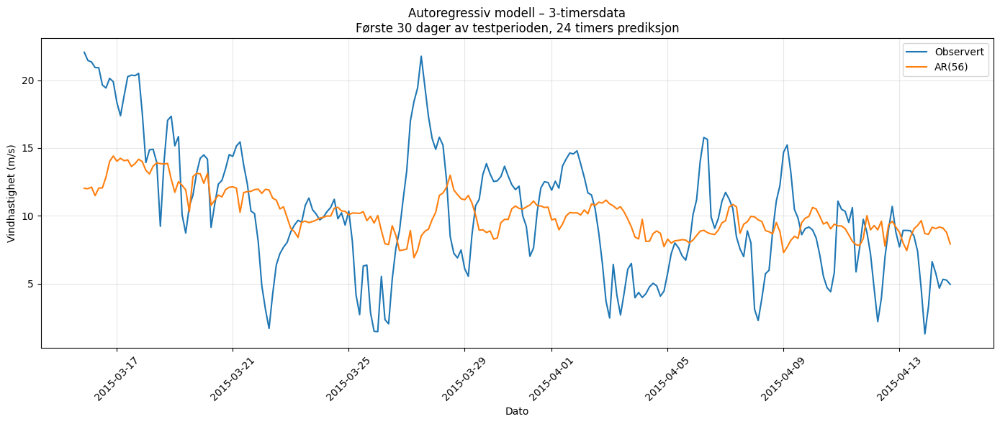

In [94]:
import matplotlib.pyplot as plt

n_plot_ar_3h = 30 * 8

plt.figure(figsize=(14, 6))

plt.plot(
    dates_ar_3h[:n_plot_ar_3h],
    y_test_ar_3h[:n_plot_ar_3h],
    label="Observert",
    linewidth=1.5
)

plt.plot(
    dates_ar_3h[:n_plot_ar_3h],
    y_pred_ar_3h[:n_plot_ar_3h],
    label="AR(56)",
    linewidth=1.5
)

plt.xlabel("Dato")
plt.ylabel("Vindhastighet (m/s)")

plt.title(
    "Autoregressiv modell – 3-timersdata\n"
    "Første 30 dager av testperioden, "
    "24 timers prediksjon"
)

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### 6 timer

In [95]:
import numpy as np
import pandas as pd

df_ar_6h = df_6h.copy()

df_ar_6h = (
    df_ar_6h
    .sort_values("datetime")
    .reset_index(drop=True)
)

series_6h = df_ar_6h["value"].astype(float)

print("Antall observasjoner:", len(series_6h))
print(series_6h.head())

Antall observasjoner: 35040
0    24.587983
1    26.793889
2    31.283525
3    27.199285
4    26.016525
Name: value, dtype: float64


In [96]:
split_ar_6h = int(len(series_6h) * 0.8)

train_ar_6h = series_6h.iloc[:split_ar_6h]
test_ar_6h = series_6h.iloc[split_ar_6h:]

print("Treningsobservasjoner:", len(train_ar_6h))
print("Testobservasjoner:", len(test_ar_6h))

Treningsobservasjoner: 28032
Testobservasjoner: 7008


In [97]:
from statsmodels.tsa.ar_model import AutoReg

p_6h = 28

ar_6h = AutoReg(
    train_ar_6h,
    lags=p_6h,
    trend="c",
    old_names=False
)

ar_result_6h = ar_6h.fit()

print(ar_result_6h.summary())

                            AutoReg Model Results                             
Dep. Variable:                  value   No. Observations:                28032
Model:                    AutoReg(28)   Log Likelihood              -65274.555
Method:               Conditional MLE   S.D. of innovations              2.489
Date:                Mon, 16 Nov 2026   AIC                         130609.110
Time:                        00:38:03   BIC                         130856.313
Sample:                            28   HQIC                        130688.689
                                28032                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.5563      0.064     24.158      0.000       1.430       1.683
value.L1       1.0793      0.006    180.616      0.000       1.068       1.091
value.L2      -0.4103      0.009    -46.665      0.0

In [98]:
h_6h = 4

# Estimerte parametere fra AR-modellen
params_6h = ar_result_6h.params.to_numpy()

c_6h = params_6h[0]
phi_6h = params_6h[1:]

values_6h = series_6h.to_numpy()

predictions_ar_6h = []
actual_ar_6h = []
dates_ar_6h = []

for t in range(split_ar_6h - 1, len(values_6h) - h_6h):

    # Siste 28 kjente observasjoner
    history = list(values_6h[t - p_6h + 1:t + 1])

    # Rekursiv prognose 4 steg fram
    for step in range(h_6h):

        lag_values = np.array(
            history[-p_6h:][::-1]
        )

        next_pred = c_6h + np.dot(phi_6h, lag_values)

        history.append(next_pred)

    # Prognose for t + 4
    predictions_ar_6h.append(history[-1])

    # Faktisk verdi ved t + 4
    actual_ar_6h.append(values_6h[t + h_6h])

    dates_ar_6h.append(
        df_ar_6h["datetime"].iloc[t + h_6h]
    )

y_pred_ar_6h = np.array(predictions_ar_6h)
y_test_ar_6h = np.array(actual_ar_6h)

dates_ar_6h = pd.to_datetime(dates_ar_6h)

In [99]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

mse_ar_6h = mean_squared_error(
    y_test_ar_6h,
    y_pred_ar_6h
)

rmse_ar_6h = np.sqrt(mse_ar_6h)

mae_ar_6h = mean_absolute_error(
    y_test_ar_6h,
    y_pred_ar_6h
)

r2_ar_6h = r2_score(
    y_test_ar_6h,
    y_pred_ar_6h
)

print("Autoregressiv modell – 6-timersdata")
print("Modell: AR(28)")
print("Prediksjonshorisont: 24 timer")
print("--------------------------------")
print(f"MSE:  {mse_ar_6h:.4f}")
print(f"RMSE: {rmse_ar_6h:.4f}")
print(f"MAE:  {mae_ar_6h:.4f}")
print(f"R²:   {r2_ar_6h:.4f}")

Autoregressiv modell – 6-timersdata
Modell: AR(28)
Prediksjonshorisont: 24 timer
--------------------------------
MSE:  17.4050
RMSE: 4.1719
MAE:  3.3786
R²:   0.0632


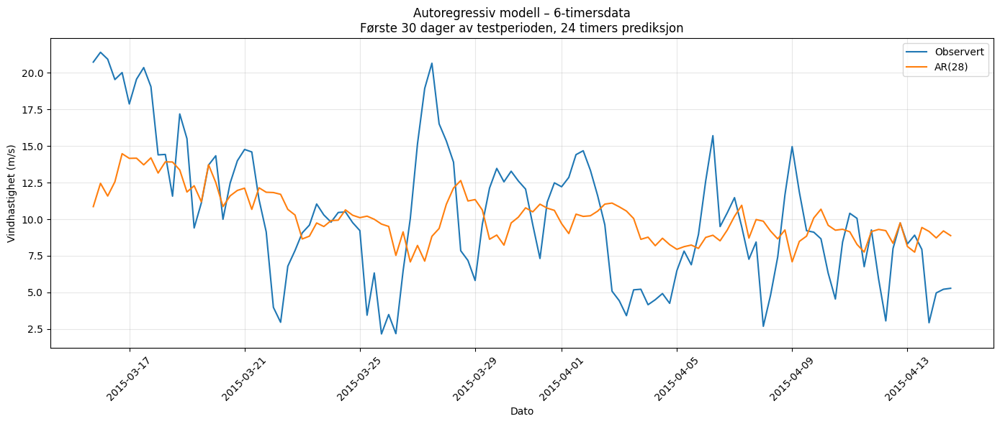

In [100]:
import matplotlib.pyplot as plt

n_plot_ar_6h = 30 * 4

plt.figure(figsize=(14, 6))

plt.plot(
    dates_ar_6h[:n_plot_ar_6h],
    y_test_ar_6h[:n_plot_ar_6h],
    label="Observert",
    linewidth=1.5
)

plt.plot(
    dates_ar_6h[:n_plot_ar_6h],
    y_pred_ar_6h[:n_plot_ar_6h],
    label="AR(28)",
    linewidth=1.5
)

plt.xlabel("Dato")
plt.ylabel("Vindhastighet (m/s)")

plt.title(
    "Autoregressiv modell – 6-timersdata\n"
    "Første 30 dager av testperioden, "
    "24 timers prediksjon"
)

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### 12 timer

In [101]:
import numpy as np
import pandas as pd

df_ar_12h = df_12h.copy()

df_ar_12h = (
    df_ar_12h
    .sort_values("datetime")
    .reset_index(drop=True)
)

series_12h = df_ar_12h["value"].astype(float)

print("Antall observasjoner:", len(series_12h))
print(series_12h.head())

Antall observasjoner: 17520
0    25.690936
1    29.241405
2    25.260174
3    20.330881
4     9.431920
Name: value, dtype: float64


In [102]:
split_ar_12h = int(len(series_12h) * 0.8)

train_ar_12h = series_12h.iloc[:split_ar_12h]
test_ar_12h = series_12h.iloc[split_ar_12h:]

print("Treningsobservasjoner:", len(train_ar_12h))
print("Testobservasjoner:", len(test_ar_12h))

Treningsobservasjoner: 14016
Testobservasjoner: 3504


In [103]:

p_12h = 14

ar_12h = AutoReg(
    train_ar_12h,
    lags=p_12h,
    trend="c",
    old_names=False
)

ar_result_12h = ar_12h.fit()

print(ar_result_12h.summary())

                            AutoReg Model Results                             
Dep. Variable:                  value   No. Observations:                14016
Model:                    AutoReg(14)   Log Likelihood              -36288.988
Method:               Conditional MLE   S.D. of innovations              3.231
Date:                Mon, 16 Nov 2026   AIC                          72609.977
Time:                        00:38:03   BIC                          72730.728
Sample:                            14   HQIC                         72650.176
                                14016                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.8372      0.118     24.111      0.000       2.607       3.068
value.L1       0.7477      0.008     88.517      0.000       0.731       0.764
value.L2      -0.2005      0.011    -19.002      0.0

In [104]:
h_12h = 2

# Estimerte parametere
params_12h = ar_result_12h.params.to_numpy()

c_12h = params_12h[0]
phi_12h = params_12h[1:]

values_12h = series_12h.to_numpy()

predictions_ar_12h = []
actual_ar_12h = []
dates_ar_12h = []

for t in range(split_ar_12h - 1, len(values_12h) - h_12h):

    # Siste 14 kjente observasjoner
    history = list(
        values_12h[t - p_12h + 1:t + 1]
    )

    # Rekursiv prediksjon 2 steg fram
    for step in range(h_12h):

        lag_values = np.array(
            history[-p_12h:][::-1]
        )

        next_pred = c_12h + np.dot(
            phi_12h,
            lag_values
        )

        history.append(next_pred)

    # Predikert vindhastighet
    predictions_ar_12h.append(history[-1])

    # Faktisk vindhastighet
    actual_ar_12h.append(values_12h[t + h_12h])

    # Dato for prediksjonen
    dates_ar_12h.append(
        df_ar_12h["datetime"].iloc[t + h_12h]
    )

y_pred_ar_12h = np.array(predictions_ar_12h)
y_test_ar_12h = np.array(actual_ar_12h)

dates_ar_12h = pd.to_datetime(dates_ar_12h)

In [105]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

mse_ar_12h = mean_squared_error(
    y_test_ar_12h,
    y_pred_ar_12h
)

rmse_ar_12h = np.sqrt(mse_ar_12h)

mae_ar_12h = mean_absolute_error(
    y_test_ar_12h,
    y_pred_ar_12h
)

r2_ar_12h = r2_score(
    y_test_ar_12h,
    y_pred_ar_12h
)

print("Autoregressiv modell – 12-timersdata")
print("Modell: AR(14)")
print("Prediksjonshorisont: 24 timer")
print("--------------------------------")
print(f"MSE:  {mse_ar_12h:.4f}")
print(f"RMSE: {rmse_ar_12h:.4f}")
print(f"MAE:  {mae_ar_12h:.4f}")
print(f"R²:   {r2_ar_12h:.4f}")

Autoregressiv modell – 12-timersdata
Modell: AR(14)
Prediksjonshorisont: 24 timer
--------------------------------
MSE:  15.4448
RMSE: 3.9300
MAE:  3.1907
R²:   0.0820


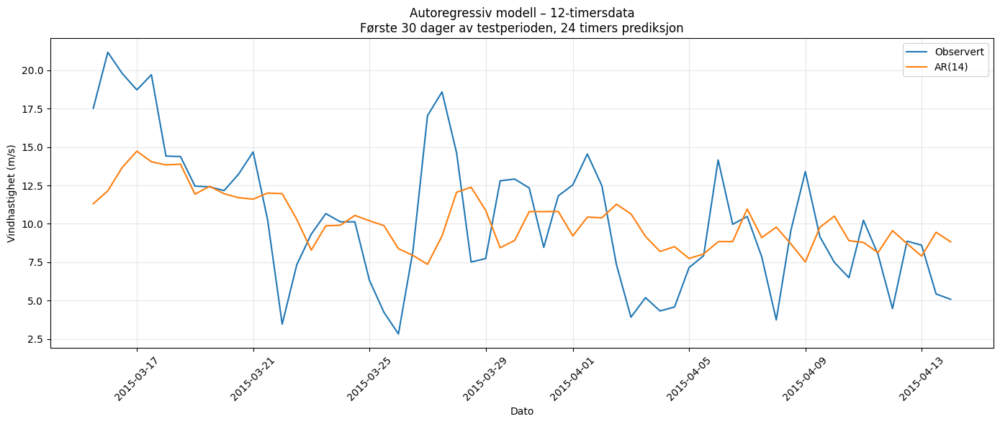

In [106]:
import matplotlib.pyplot as plt

n_plot_ar_12h = 30 * 2

plt.figure(figsize=(14, 6))

plt.plot(
    dates_ar_12h[:n_plot_ar_12h],
    y_test_ar_12h[:n_plot_ar_12h],
    label="Observert",
    linewidth=1.5
)

plt.plot(
    dates_ar_12h[:n_plot_ar_12h],
    y_pred_ar_12h[:n_plot_ar_12h],
    label="AR(14)",
    linewidth=1.5
)

plt.xlabel("Dato")
plt.ylabel("Vindhastighet (m/s)")

plt.title(
    "Autoregressiv modell – 12-timersdata\n"
    "Første 30 dager av testperioden, "
    "24 timers prediksjon"
)

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [107]:
print("Autoregressiv modell – 12-timersdata")
print("--------------------------------")
print(f"AR-orden: {p_12h}")
print(f"AIC: {ar_result_12h.aic:.4f}")
print(f"BIC: {ar_result_12h.bic:.4f}")
print(f"Log-likelihood: {ar_result_12h.llf:.4f}")

# Kontroller AIC-formelen
k_12h = len(ar_result_12h.params) + 1

aic_manual_12h = (
    -2 * ar_result_12h.llf
    + 2 * k_12h
)

print(f"AIC manuelt: {aic_manual_12h:.4f}")

Autoregressiv modell – 12-timersdata
--------------------------------
AR-orden: 14
AIC: 72609.9769
BIC: 72730.7282
Log-likelihood: -36288.9884
AIC manuelt: 72609.9769


#### daglig


In [108]:
import numpy as np
import pandas as pd

df_ar_daily = df_daily.copy()

df_ar_daily = (
    df_ar_daily
    .sort_values("datetime")
    .reset_index(drop=True)
)

series_daily = df_ar_daily["value"].astype(float)

print("Antall observasjoner:", len(series_daily))
print(series_daily.head())

Antall observasjoner: 8760
0    27.466171
1    22.795527
2     9.255732
3    13.591242
4    12.153363
Name: value, dtype: float64


In [109]:
split_ar_daily = int(len(series_daily) * 0.8)

train_ar_daily = series_daily.iloc[:split_ar_daily]
test_ar_daily = series_daily.iloc[split_ar_daily:]

print("Treningsobservasjoner:", len(train_ar_daily))
print("Testobservasjoner:", len(test_ar_daily))

Treningsobservasjoner: 7008
Testobservasjoner: 1752


In [110]:

p_daily = 7

ar_daily = AutoReg(
    train_ar_daily,
    lags=p_daily,
    trend="c",
    old_names=False
)

ar_result_daily = ar_daily.fit()

print(ar_result_daily.summary())

                            AutoReg Model Results                             
Dep. Variable:                  value   No. Observations:                 7008
Model:                     AutoReg(7)   Log Likelihood              -18550.930
Method:               Conditional MLE   S.D. of innovations              3.424
Date:                Mon, 16 Nov 2026   AIC                          37119.859
Time:                        00:38:03   BIC                          37181.543
Sample:                             7   HQIC                         37141.114
                                 7008                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.2655      0.175     24.326      0.000       3.922       4.609
value.L1       0.4954      0.012     41.470      0.000       0.472       0.519
value.L2      -0.0604      0.013     -4.534      0.0

In [111]:
h_daily = 1

# Estimerte parametere
params_daily = ar_result_daily.params.to_numpy()

c_daily = params_daily[0]
phi_daily = params_daily[1:]

values_daily = series_daily.to_numpy()

predictions_ar_daily = []
actual_ar_daily = []
dates_ar_daily = []

for t in range(
    split_ar_daily - 1,
    len(values_daily) - h_daily
):

    # Siste 7 kjente observasjoner
    history = list(
        values_daily[t - p_daily + 1:t + 1]
    )

    # Prediksjon ett døgn fram
    for step in range(h_daily):

        lag_values = np.array(
            history[-p_daily:][::-1]
        )

        next_pred = c_daily + np.dot(
            phi_daily,
            lag_values
        )

        history.append(next_pred)

    # Predikert vindhastighet
    predictions_ar_daily.append(history[-1])

    # Faktisk vindhastighet
    actual_ar_daily.append(values_daily[t + h_daily])

    # Dato for prediksjonen
    dates_ar_daily.append(
        df_ar_daily["datetime"].iloc[t + h_daily]
    )

y_pred_ar_daily = np.array(predictions_ar_daily)
y_test_ar_daily = np.array(actual_ar_daily)

dates_ar_daily = pd.to_datetime(dates_ar_daily)

In [112]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

mse_ar_daily = mean_squared_error(
    y_test_ar_daily,
    y_pred_ar_daily
)

rmse_ar_daily = np.sqrt(mse_ar_daily)

mae_ar_daily = mean_absolute_error(
    y_test_ar_daily,
    y_pred_ar_daily
)

r2_ar_daily = r2_score(
    y_test_ar_daily,
    y_pred_ar_daily
)

print("Autoregressiv modell – daglige data")
print("Modell: AR(7)")
print("Prediksjonshorisont: 24 timer")
print("--------------------------------")
print(f"MSE:  {mse_ar_daily:.4f}")
print(f"RMSE: {rmse_ar_daily:.4f}")
print(f"MAE:  {mae_ar_daily:.4f}")
print(f"R²:   {r2_ar_daily:.4f}")

Autoregressiv modell – daglige data
Modell: AR(7)
Prediksjonshorisont: 24 timer
--------------------------------
MSE:  10.9931
RMSE: 3.3156
MAE:  2.6905
R²:   0.1857


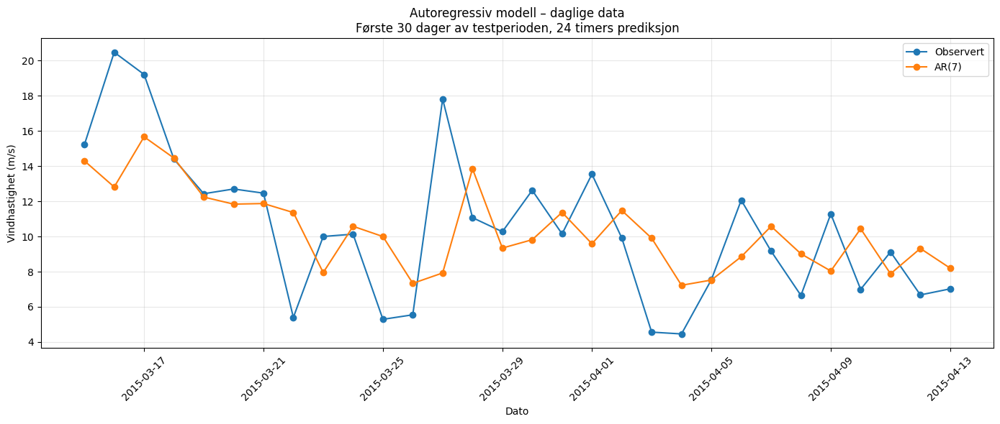

In [113]:
n_plot_ar_daily = 30

plt.figure(figsize=(14, 6))

plt.plot(
    dates_ar_daily[:n_plot_ar_daily],
    y_test_ar_daily[:n_plot_ar_daily],
    label="Observert",
    marker="o",
    linewidth=1.5
)

plt.plot(
    dates_ar_daily[:n_plot_ar_daily],
    y_pred_ar_daily[:n_plot_ar_daily],
    label="AR(7)",
    marker="o",
    linewidth=1.5
)

plt.xlabel("Dato")
plt.ylabel("Vindhastighet (m/s)")

plt.title(
    "Autoregressiv modell – daglige data\n"
    "Første 30 dager av testperioden, "
    "24 timers prediksjon"
)

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [114]:
print("Autoregressiv modell – daglige data")
print("--------------------------------")
print(f"AR-orden: {p_daily}")
print(f"AIC: {ar_result_daily.aic:.4f}")
print(f"BIC: {ar_result_daily.bic:.4f}")
print(f"Log-likelihood: {ar_result_daily.llf:.4f}")

# Beregn AIC manuelt
k_daily = len(ar_result_daily.params) + 1

aic_manual_daily = (
    -2 * ar_result_daily.llf
    + 2 * k_daily
)

print(f"AIC manuelt: {aic_manual_daily:.4f}")

Autoregressiv modell – daglige data
--------------------------------
AR-orden: 7
AIC: 37119.8591
BIC: 37181.5434
Log-likelihood: -18550.9295
AIC manuelt: 37119.8591


In [115]:
ar_results = pd.DataFrame({
    "Tidsoppløsning": [
        "3 timer",
        "6 timer",
        "12 timer",
        "Daglig"
    ],
    "MSE": [
        mse_ar_3h,
        mse_ar_6h,
        mse_ar_12h,
        mse_ar_daily
    ],
    "RMSE": [
        rmse_ar_3h,
        rmse_ar_6h,
        rmse_ar_12h,
        rmse_ar_daily
    ],
    "MAE": [
        mae_ar_3h,
        mae_ar_6h,
        mae_ar_12h,
        mae_ar_daily
    ],
    "R²": [
        r2_ar_3h,
        r2_ar_6h,
        r2_ar_12h,
        r2_ar_daily
    ],
})

print(ar_results.round(4))

  Tidsoppløsning      MSE    RMSE     MAE      R²
0        3 timer  18.3169  4.2798  3.4624  0.0568
1        6 timer  17.4050  4.1719  3.3786  0.0632
2       12 timer  15.4448  3.9300  3.1907  0.0820
3         Daglig  10.9931  3.3156  2.6905  0.1857


#### daglig sesongjustert

In [116]:
df_ar_season = daily_mean[["date", "value"]].copy()

df_ar_season["date"] = pd.to_datetime(
    df_ar_season["date"]
)

df_ar_season = (
    df_ar_season
    .sort_values("date")
    .reset_index(drop=True)
)

# Fjern 29. februar for 365-dagers sesongmodell
df_ar_season = df_ar_season.loc[
    ~(
        (df_ar_season["date"].dt.month == 2)
        & (df_ar_season["date"].dt.day == 29)
    )
].reset_index(drop=True)

split_ar_season = int(len(df_ar_season) * 0.8)

train_ar_season = df_ar_season.iloc[
    :split_ar_season
].copy()

test_ar_season = df_ar_season.iloc[
    split_ar_season:
].copy()

print(
    "Train:",
    train_ar_season["date"].min(),
    "til",
    train_ar_season["date"].max()
)

print(
    "Test:",
    test_ar_season["date"].min(),
    "til",
    test_ar_season["date"].max()
)

Train: 1996-01-01 00:00:00 til 2015-03-14 00:00:00
Test: 2015-03-15 00:00:00 til 2019-12-31 00:00:00


In [117]:
train_ar_season["month"] = (
    train_ar_season["date"].dt.month
)

train_ar_season["day"] = (
    train_ar_season["date"].dt.day
)

train_calendar_ar = (
    train_ar_season
    .groupby(["month", "day"], as_index=False)["value"]
    .mean()
    .sort_values(["month", "day"])
    .reset_index(drop=True)
)

train_calendar_ar["day_of_year"] = np.arange(
    len(train_calendar_ar)
)

assert len(train_calendar_ar) == 365

t_ar = train_calendar_ar["day_of_year"].to_numpy()

X_sinus_ar = np.column_stack([
    np.ones(len(t_ar)),
    np.cos(2 * np.pi * t_ar / 365),
    np.sin(2 * np.pi * t_ar / 365)
])

y_sinus_ar = train_calendar_ar["value"].to_numpy()

beta_ar = np.linalg.lstsq(
    X_sinus_ar,
    y_sinus_ar,
    rcond=None
)[0]

mu0_ar, mu1_ar, mu2_ar = beta_ar

print("Sinusmodell – kun treningsdata")
print("--------------------------------")
print(f"mu0: {mu0_ar:.4f}")
print(f"mu1: {mu1_ar:.4f}")
print(f"mu2: {mu2_ar:.4f}")

Sinusmodell – kun treningsdata
--------------------------------
mu0: 9.4631
mu1: 1.4714
mu2: 0.1655


In [118]:
calendar_lookup_ar = train_calendar_ar[
    ["month", "day", "day_of_year"]
].copy()

t_all_ar = calendar_lookup_ar[
    "day_of_year"
].to_numpy()

calendar_lookup_ar["value_estimate"] = (
    mu0_ar
    + mu1_ar * np.cos(2 * np.pi * t_all_ar / 365)
    + mu2_ar * np.sin(2 * np.pi * t_all_ar / 365)
)

df_ar_season["month"] = (
    df_ar_season["date"].dt.month
)

df_ar_season["day"] = (
    df_ar_season["date"].dt.day
)

df_ar_season = df_ar_season.merge(
    calendar_lookup_ar[
        ["month", "day", "value_estimate"]
    ],
    on=["month", "day"],
    how="left",
    validate="many_to_one"
)

assert df_ar_season["value_estimate"].notna().all()

print(
    df_ar_season[
        ["date", "value", "value_estimate"]
    ].head()
)

        date      value  value_estimate
0 1996-01-01  27.466171       10.934495
1 1996-01-02  22.795527       10.937126
2 1996-01-03   9.255732       10.939320
3 1996-01-04  13.591242       10.941076
4 1996-01-05  12.153363       10.942395


In [119]:
df_ar_season["residual"] = (
    df_ar_season["value"]
    - df_ar_season["value_estimate"]
)

print(
    df_ar_season[
        ["date", "value", "value_estimate", "residual"]
    ].head()
)

        date      value  value_estimate   residual
0 1996-01-01  27.466171       10.934495  16.531676
1 1996-01-02  22.795527       10.937126  11.858402
2 1996-01-03   9.255732       10.939320  -1.683588
3 1996-01-04  13.591242       10.941076   2.650166
4 1996-01-05  12.153363       10.942395   1.210968


In [120]:
p_ar_season = 7

train_residual_ar = (
    df_ar_season["residual"]
    .iloc[:split_ar_season]
)

ar_season = AutoReg(
    train_residual_ar,
    lags=p_ar_season,
    trend="c",
    old_names=False
)

ar_result_season = ar_season.fit()

print(ar_result_season.summary())

                            AutoReg Model Results                             
Dep. Variable:               residual   No. Observations:                 7008
Model:                     AutoReg(7)   Log Likelihood              -18466.202
Method:               Conditional MLE   S.D. of innovations              3.383
Date:                Mon, 16 Nov 2026   AIC                          36950.403
Time:                        00:38:03   BIC                          37012.088
Sample:                             7   HQIC                         36971.659
                                 7008                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -0.0012      0.040     -0.030      0.976      -0.080       0.078
residual.L1     0.4706      0.012     39.373      0.000       0.447       0.494
residual.L2    -0.0735      0.013     -5.564    

In [121]:
h_ar_season = 1

params_ar_season = np.asarray(
    ar_result_season.params
)

c_ar_season = params_ar_season[0]
phi_ar_season = params_ar_season[1:]

residual_values_ar = (
    df_ar_season["residual"].to_numpy()
)

actual_values_ar = (
    df_ar_season["value"].to_numpy()
)

season_values_ar = (
    df_ar_season["value_estimate"].to_numpy()
)

predictions_ar_season = []
actual_ar_season = []
dates_ar_season = []
residual_predictions_ar = []

for t in range(
    split_ar_season - 1,
    len(df_ar_season) - h_ar_season
):

    # De siste 7 kjente residualene
    history = list(
        residual_values_ar[
            t - p_ar_season + 1:t + 1
        ]
    )

    # Prediker neste dags residual
    lag_values = np.array(
        history[-p_ar_season:][::-1]
    )

    next_residual = (
        c_ar_season
        + np.dot(phi_ar_season, lag_values)
    )

    # Legg tilbake sesongkomponenten
    next_prediction = (
        next_residual
        + season_values_ar[t + h_ar_season]
    )

    residual_predictions_ar.append(
        next_residual
    )

    predictions_ar_season.append(
        next_prediction
    )

    actual_ar_season.append(
        actual_values_ar[t + h_ar_season]
    )

    dates_ar_season.append(
        df_ar_season["date"].iloc[
            t + h_ar_season
        ]
    )

y_pred_ar_season = np.array(
    predictions_ar_season
)

y_test_ar_season = np.array(
    actual_ar_season
)

dates_ar_season = pd.to_datetime(
    dates_ar_season
)

In [122]:
mse_ar_season = mean_squared_error(
    y_test_ar_season,
    y_pred_ar_season
)

rmse_ar_season = np.sqrt(
    mse_ar_season
)

mae_ar_season = mean_absolute_error(
    y_test_ar_season,
    y_pred_ar_season
)

r2_ar_season = r2_score(
    y_test_ar_season,
    y_pred_ar_season
)

print("AutoReg – Daglig med sesongjustering")
print("Modell: AR(7)")
print("Prediksjonshorisont: 24 timer")
print("--------------------------------")
print(f"MSE:  {mse_ar_season:.4f}")
print(f"RMSE: {rmse_ar_season:.4f}")
print(f"MAE:  {mae_ar_season:.4f}")
print(f"R²:   {r2_ar_season:.4f}")

AutoReg – Daglig med sesongjustering
Modell: AR(7)
Prediksjonshorisont: 24 timer
--------------------------------
MSE:  10.8365
RMSE: 3.2919
MAE:  2.6607
R²:   0.1973


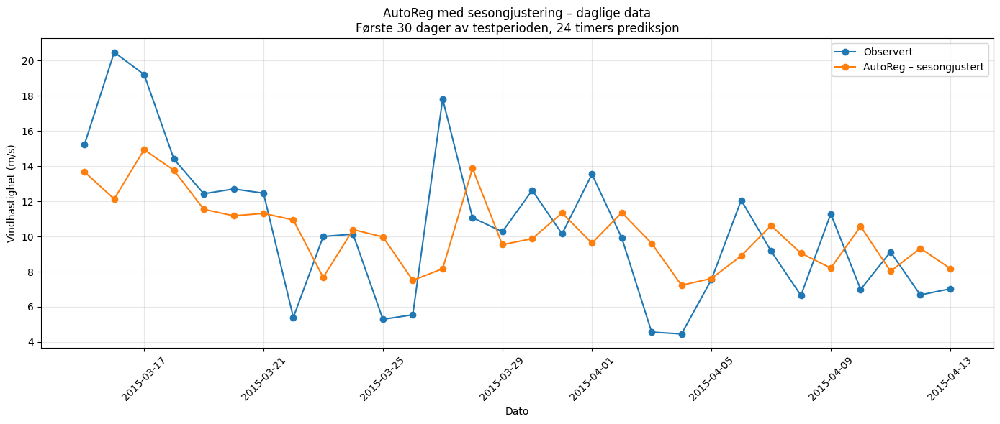

In [123]:
n_plot_ar_season = 30

plt.figure(figsize=(14, 6))

plt.plot(
    dates_ar_season[:n_plot_ar_season],
    y_test_ar_season[:n_plot_ar_season],
    label="Observert",
    marker="o",
    linewidth=1.5
)

plt.plot(
    dates_ar_season[:n_plot_ar_season],
    y_pred_ar_season[:n_plot_ar_season],
    label="AutoReg – sesongjustert",
    marker="o",
    linewidth=1.5
)

plt.xlabel("Dato")
plt.ylabel("Vindhastighet (m/s)")

plt.title(
    "AutoReg med sesongjustering – daglige data\n"
    "Første 30 dager av testperioden, "
    "24 timers prediksjon"
)

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "ar_daily_season_prediction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [124]:
# Vanlig AR(7)
df_ar_normal_pred = pd.DataFrame({
    "date": pd.to_datetime(dates_ar_daily),
    "observed_normal": y_test_ar_daily,
    "predicted_normal": y_pred_ar_daily
})

# Sesongjustert AR(7)
df_ar_season_pred = pd.DataFrame({
    "date": dates_ar_season,
    "observed_season": y_test_ar_season,
    "predicted_season": y_pred_ar_season
})

# Slå sammen på dato
comparison_ar_daily = pd.merge(
    df_ar_normal_pred,
    df_ar_season_pred,
    on="date",
    how="inner",
    validate="one_to_one"
)

comparison_ar_daily = (
    comparison_ar_daily
    .sort_values("date")
    .reset_index(drop=True)
)

assert len(comparison_ar_daily) > 0, (
    "Ingen felles testdatoer mellom modellene."
)

assert np.allclose(
    comparison_ar_daily["observed_normal"],
    comparison_ar_daily["observed_season"]
), "Modellene har ulike observerte verdier på samme dato."

print(
    "Felles testobservasjoner:",
    len(comparison_ar_daily)
)

Felles testobservasjoner: 1752


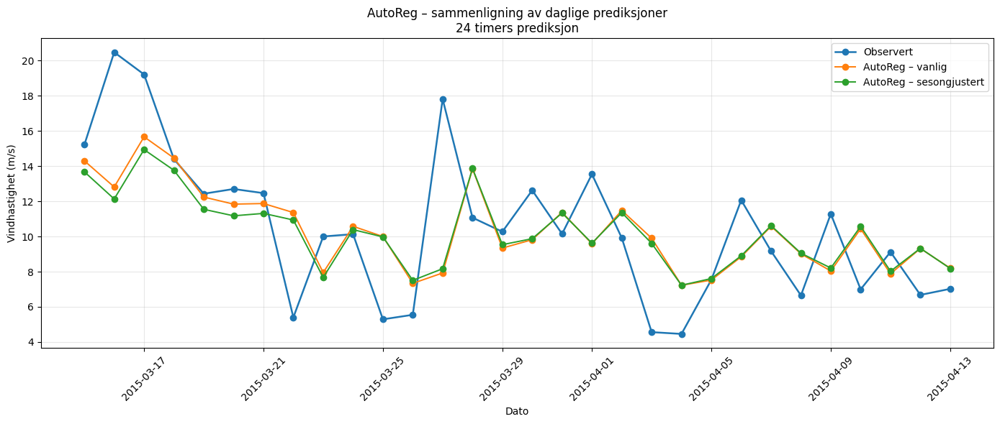

In [125]:
n_plot = 30

plot_ar = comparison_ar_daily.iloc[:n_plot]

plt.figure(figsize=(14, 6))

plt.plot(
    plot_ar["date"],
    plot_ar["observed_season"],
    label="Observert",
    marker="o",
    linewidth=1.8
)

plt.plot(
    plot_ar["date"],
    plot_ar["predicted_normal"],
    label="AutoReg – vanlig",
    marker="o",
    linewidth=1.4
)

plt.plot(
    plot_ar["date"],
    plot_ar["predicted_season"],
    label="AutoReg – sesongjustert",
    marker="o",
    linewidth=1.4
)

plt.xlabel("Dato")
plt.ylabel("Vindhastighet (m/s)")

plt.title(
    "AutoReg – sammenligning av daglige prediksjoner\n"
    "24 timers prediksjon"
)

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "ar_daily_season_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [126]:
def ar_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)

    return {
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R²": r2_score(y_true, y_pred)
    }

ar_daily_comparison = pd.DataFrame({
    "Vanlig AR(7)": ar_metrics(
        comparison_ar_daily["observed_normal"],
        comparison_ar_daily["predicted_normal"]
    ),
    "Sesongjustert AR(7)": ar_metrics(
        comparison_ar_daily["observed_season"],
        comparison_ar_daily["predicted_season"]
    )
}).T

print(ar_daily_comparison.round(4))

                         MSE    RMSE     MAE      R²
Vanlig AR(7)         10.9931  3.3156  2.6905  0.1857
Sesongjustert AR(7)  10.8365  3.2919  2.6607  0.1973


In [127]:
ar_results = pd.DataFrame({
    "Tidsoppløsning": [
        "3 timer",
        "6 timer",
        "12 timer",
        "Daglig",
        "Sesongjustert daglig"
    ],
    "MSE": [
        mse_ar_3h,
        mse_ar_6h,
        mse_ar_12h,
        mse_ar_daily,
        mse_ar_season
    ],
    "RMSE": [
        rmse_ar_3h,
        rmse_ar_6h,
        rmse_ar_12h,
        rmse_ar_daily,
        rmse_ar_season
    ],
    "MAE": [
        mae_ar_3h,
        mae_ar_6h,
        mae_ar_12h,
        mae_ar_daily,
        mae_ar_season
    ],
    "R²": [
        r2_ar_3h,
        r2_ar_6h,
        r2_ar_12h,
        r2_ar_daily,
        r2_ar_season
    ]
})

print(ar_results.round(4))

         Tidsoppløsning      MSE    RMSE     MAE      R²
0               3 timer  18.3169  4.2798  3.4624  0.0568
1               6 timer  17.4050  4.1719  3.3786  0.0632
2              12 timer  15.4448  3.9300  3.1907  0.0820
3                Daglig  10.9931  3.3156  2.6905  0.1857
4  Sesongjustert daglig  10.8365  3.2919  2.6607  0.1973


### Neveral netverk

#### 3 timer

In [128]:

# Reproduserbarhet
np.random.seed(42)
torch.manual_seed(42)

# Kopier og sorter datasettet
df_ann_3h = df_3h.copy()

df_ann_3h["datetime"] = pd.to_datetime(
    df_ann_3h["datetime"]
)

df_ann_3h = (
    df_ann_3h
    .sort_values("datetime")
    .reset_index(drop=True)
)

print("Antall observasjoner:", len(df_ann_3h))
print(df_ann_3h[["datetime", "value"]].head())

Antall observasjoner: 70080
             datetime      value
0 1996-01-01 00:00:00  24.978496
1 1996-01-01 03:00:00  24.197471
2 1996-01-01 06:00:00  24.593582
3 1996-01-01 09:00:00  28.994197
4 1996-01-01 12:00:00  31.685537


In [129]:
p_ann_3h = 56
h_ann_3h = 8

# Kontroller at dataene har regelmessig 3-timersintervall
tidsforskjell = df_ann_3h["datetime"].diff().dropna()


# Lag inngangsvariabler
lag_data = {
    f"lag_{i}": df_ann_3h["value"].shift(i)
    for i in range(p_ann_3h)
}

df_ann_3h = pd.concat(
    [df_ann_3h, pd.DataFrame(lag_data)],
    axis=1
)

lag_cols_ann_3h = [
    f"lag_{i}" for i in range(p_ann_3h)
]

# Vindhastighet 24 timer fram
df_ann_3h["target"] = (
    df_ann_3h["value"].shift(-h_ann_3h)
)

df_ann_3h["target_datetime"] = (
    df_ann_3h["datetime"].shift(-h_ann_3h)
)

df_ann_3h = (
    df_ann_3h
    .dropna(
        subset=lag_cols_ann_3h
        + ["target", "target_datetime"]
    )
    .reset_index(drop=True)
)

print("Antall observasjoner etter lag:", len(df_ann_3h))

Antall observasjoner etter lag: 70017


In [130]:
n_ann_3h = len(df_ann_3h)

split_test_ann_3h = int(n_ann_3h * 0.8)
split_val_ann_3h = int(split_test_ann_3h * 0.9)

# Indekser for trening, validering og test
fit_end_ann_3h = split_val_ann_3h - h_ann_3h
val_end_ann_3h = split_test_ann_3h - h_ann_3h

if fit_end_ann_3h <= 0 or val_end_ann_3h <= split_val_ann_3h:
    raise ValueError("For få observasjoner til datadelingen.")

df_fit_ann_3h = df_ann_3h.iloc[:fit_end_ann_3h]
df_val_ann_3h = df_ann_3h.iloc[
    split_val_ann_3h:val_end_ann_3h
]
df_test_ann_3h = df_ann_3h.iloc[split_test_ann_3h:]

X_fit_ann_3h = df_fit_ann_3h[lag_cols_ann_3h]
X_val_ann_3h = df_val_ann_3h[lag_cols_ann_3h]
X_test_ann_3h = df_test_ann_3h[lag_cols_ann_3h]

y_fit_ann_3h = df_fit_ann_3h["target"]
y_val_ann_3h = df_val_ann_3h["target"]
y_test_ann_3h = df_test_ann_3h["target"].to_numpy()

dates_test_ann_3h = df_test_ann_3h[
    "target_datetime"
].reset_index(drop=True)

print("Trening:", len(X_fit_ann_3h))
print("Validering:", len(X_val_ann_3h))
print("Test:", len(X_test_ann_3h))

Trening: 50403
Validering: 5594
Test: 14004


In [131]:
scaler_X_ann_3h = MinMaxScaler()
scaler_y_ann_3h = MinMaxScaler()

X_fit_scaled_ann_3h = scaler_X_ann_3h.fit_transform(
    X_fit_ann_3h
)

X_val_scaled_ann_3h = scaler_X_ann_3h.transform(
    X_val_ann_3h
)

X_test_scaled_ann_3h = scaler_X_ann_3h.transform(
    X_test_ann_3h
)

y_fit_scaled_ann_3h = scaler_y_ann_3h.fit_transform(
    y_fit_ann_3h.to_numpy().reshape(-1, 1)
)

y_val_scaled_ann_3h = scaler_y_ann_3h.transform(
    y_val_ann_3h.to_numpy().reshape(-1, 1)
)

In [132]:
class WindANN(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)


ann_model_3h = WindANN(
    input_size=p_ann_3h
)

print(ann_model_3h)

print(
    "Antall trenbare parametere:",
    sum(
        p.numel()
        for p in ann_model_3h.parameters()
        if p.requires_grad
    )
)

WindANN(
  (network): Sequential(
    (0): Linear(in_features=56, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)
Antall trenbare parametere: 5761


In [133]:
X_fit_tensor_ann_3h = torch.tensor(
    X_fit_scaled_ann_3h,
    dtype=torch.float32
)

y_fit_tensor_ann_3h = torch.tensor(
    y_fit_scaled_ann_3h,
    dtype=torch.float32
)

X_val_tensor_ann_3h = torch.tensor(
    X_val_scaled_ann_3h,
    dtype=torch.float32
)

y_val_tensor_ann_3h = torch.tensor(
    y_val_scaled_ann_3h,
    dtype=torch.float32
)

train_dataset_ann_3h = TensorDataset(
    X_fit_tensor_ann_3h,
    y_fit_tensor_ann_3h
)

train_loader_ann_3h = DataLoader(
    train_dataset_ann_3h,
    batch_size=32,
    shuffle=True
)

In [134]:
criterion_ann_3h = nn.MSELoss()

optimizer_ann_3h = torch.optim.Adam(
    ann_model_3h.parameters(),
    lr=0.001
)

epochs_ann_3h = 100
patience_ann_3h = 10

best_val_loss_ann_3h = float("inf")
best_state_ann_3h = None
best_epoch_ann_3h = 0
wait_ann_3h = 0

train_losses_ann_3h = []
val_losses_ann_3h = []

for epoch in range(epochs_ann_3h):

    ann_model_3h.train()
    total_loss = 0.0

    for X_batch, y_batch in train_loader_ann_3h:

        optimizer_ann_3h.zero_grad()

        y_batch_pred = ann_model_3h(X_batch)

        loss = criterion_ann_3h(
            y_batch_pred,
            y_batch
        )

        loss.backward()
        optimizer_ann_3h.step()

        total_loss += loss.item() * len(X_batch)

    train_loss = (
        total_loss / len(X_fit_tensor_ann_3h)
    )

    ann_model_3h.eval()

    with torch.no_grad():
        val_pred = ann_model_3h(
            X_val_tensor_ann_3h
        )

        val_loss = criterion_ann_3h(
            val_pred,
            y_val_tensor_ann_3h
        ).item()

    train_losses_ann_3h.append(train_loss)
    val_losses_ann_3h.append(val_loss)

    if val_loss < best_val_loss_ann_3h:

        best_val_loss_ann_3h = val_loss

        best_state_ann_3h = copy.deepcopy(
            ann_model_3h.state_dict()
        )

        best_epoch_ann_3h = epoch + 1
        wait_ann_3h = 0

    else:
        wait_ann_3h += 1

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1}: "
            f"Train MSE = {train_loss:.6f}, "
            f"Val MSE = {val_loss:.6f}"
        )

    if wait_ann_3h >= patience_ann_3h:
        print(
            f"Early stopping ved epoch {epoch + 1}"
        )
        break

# Gjenopprett beste modell
ann_model_3h.load_state_dict(
    best_state_ann_3h
)

print("Beste epoch:", best_epoch_ann_3h)
print("Beste validerings-MSE:", best_val_loss_ann_3h)

NameError: name 'copy' is not defined

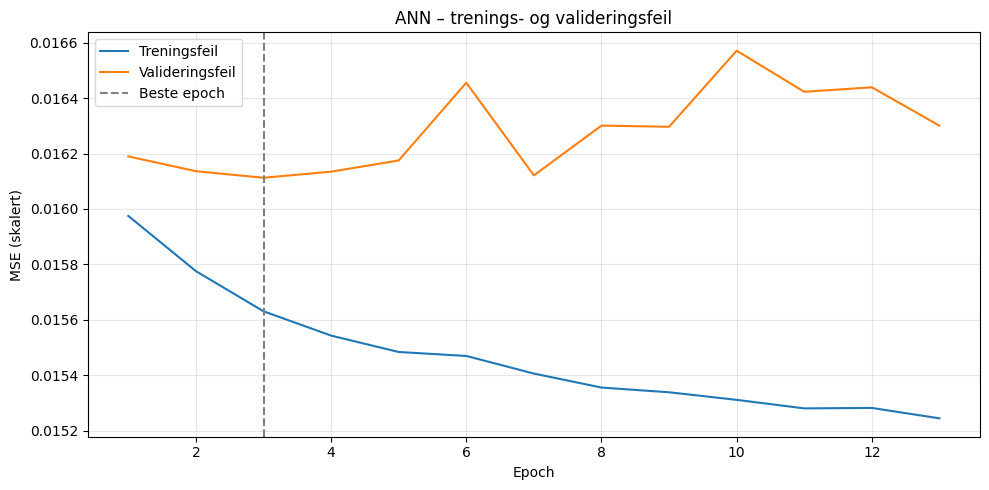

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(train_losses_ann_3h) + 1),
    train_losses_ann_3h,
    label="Treningsfeil"
)

plt.plot(
    range(1, len(val_losses_ann_3h) + 1),
    val_losses_ann_3h,
    label="Valideringsfeil"
)

plt.axvline(
    best_epoch_ann_3h,
    color="gray",
    linestyle="--",
    label="Beste epoch"
)

plt.xlabel("Epoch")
plt.ylabel("MSE (skalert)")

plt.title(
    "ANN – trenings- og valideringsfeil"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "ann_3h_training.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
X_test_tensor_ann_3h = torch.tensor(
    X_test_scaled_ann_3h,
    dtype=torch.float32
)

ann_model_3h.eval()

with torch.no_grad():

    y_pred_scaled_ann_3h = (
        ann_model_3h(X_test_tensor_ann_3h)
        .cpu()
        .numpy()
    )

# Tilbake til m/s
y_pred_ann_3h = (
    scaler_y_ann_3h
    .inverse_transform(y_pred_scaled_ann_3h)
    .flatten()
)

In [ ]:
mse_ann_3h = mean_squared_error(
    y_test_ann_3h,
    y_pred_ann_3h
)

rmse_ann_3h = np.sqrt(mse_ann_3h)

mae_ann_3h = mean_absolute_error(
    y_test_ann_3h,
    y_pred_ann_3h
)

r2_ann_3h = r2_score(
    y_test_ann_3h,
    y_pred_ann_3h
)

print("ANN – 3-timersdata")
print("--------------------------")
print(f"MSE:  {mse_ann_3h:.4f}")
print(f"RMSE: {rmse_ann_3h:.4f}")
print(f"MAE:  {mae_ann_3h:.4f}")
print(f"R²:   {r2_ann_3h:.4f}")

ANN – 3-timersdata
--------------------------
MSE:  18.2357
RMSE: 4.2703
MAE:  3.4686
R²:   0.0587


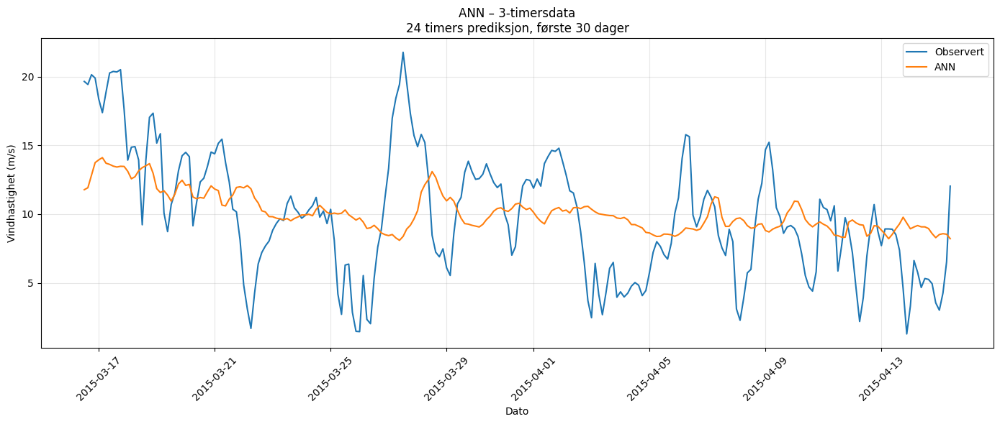

In [ ]:
n_plot_ann_3h = 30 * 8

plt.figure(figsize=(14, 6))

plt.plot(
    dates_test_ann_3h.iloc[:n_plot_ann_3h],
    y_test_ann_3h[:n_plot_ann_3h],
    label="Observert",
    linewidth=1.5
)

plt.plot(
    dates_test_ann_3h.iloc[:n_plot_ann_3h],
    y_pred_ann_3h[:n_plot_ann_3h],
    label="ANN",
    linewidth=1.5
)

plt.xlabel("Dato")
plt.ylabel("Vindhastighet (m/s)")

plt.title(
    "ANN – 3-timersdata\n"
    "24 timers prediksjon, første 30 dager"
)

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "ann_3h_prediction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

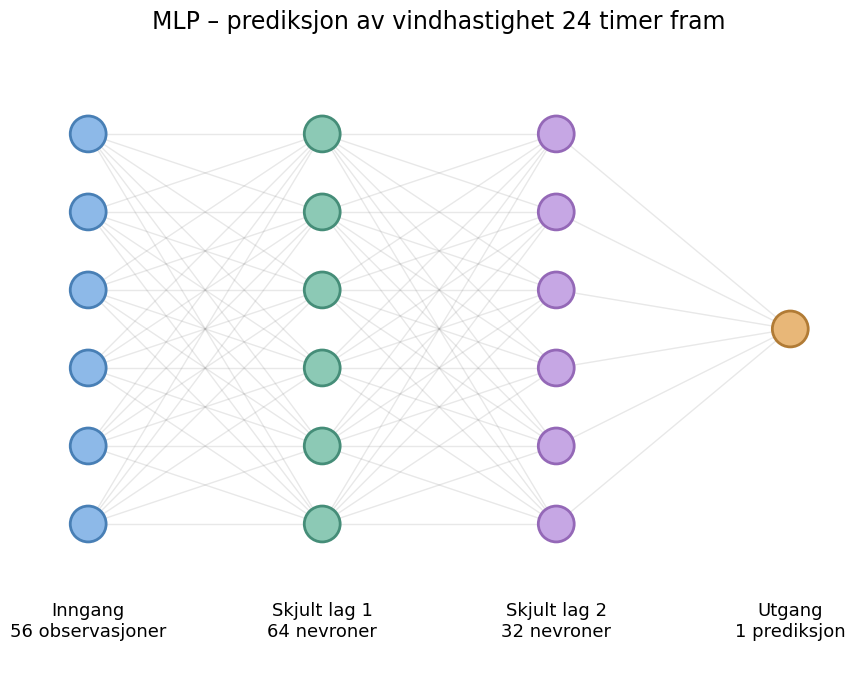

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import numpy as np

# ANN-arkitektur
layer_sizes = [56, 64, 32, 1]

layer_names = [
    "Inngang\n56 observasjoner",
    "Skjult lag 1\n64 nevroner",
    "Skjult lag 2\n32 nevroner",
    "Utgang\n1 prediksjon"
]

# Antall nevroner som vises i figuren
display_sizes = [6, 6, 6, 1]

colors = [
    "#8DB9E8",
    "#8CC9B5",
    "#C6A7E4",
    "#E8B778"
]

edge_colors = [
    "#487FB5",
    "#458D78",
    "#9468B7",
    "#B17B35"
]

fig, ax = plt.subplots(figsize=(14, 7))

x_positions = [0, 3, 6, 9]

neuron_positions = []

# Tegn nevronene
for layer_idx, n in enumerate(display_sizes):

    y_positions = np.linspace(
        -(n - 1) / 2,
        (n - 1) / 2,
        n
    )

    positions = []

    for y in y_positions:

        x = x_positions[layer_idx]

        positions.append((x, y))

        neuron = Circle(
            (x, y),
            radius=0.23,
            facecolor=colors[layer_idx],
            edgecolor=edge_colors[layer_idx],
            linewidth=2,
            zorder=3
        )

        ax.add_patch(neuron)

    neuron_positions.append(positions)

# Tegn forbindelsene
for layer_idx in range(len(display_sizes) - 1):

    for x1, y1 in neuron_positions[layer_idx]:

        for x2, y2 in neuron_positions[layer_idx + 1]:

            ax.plot(
                [x1, x2],
                [y1, y2],
                color="gray",
                alpha=0.18,
                linewidth=1,
                zorder=1
            )

# Legg til navn under lagene
for i, label in enumerate(layer_names):

    ax.text(
        x_positions[i],
        -3.5,
        label,
        ha="center",
        va="top",
        fontsize=13
    )

ax.set_title(
    "MLP – prediksjon av vindhastighet 24 timer fram",
    fontsize=17,
    pad=25
)

ax.set_xlim(-0.8, 9.8)
ax.set_ylim(-4.5, 3.4)

ax.set_aspect("equal")
ax.axis("off")

plt.tight_layout()

# Lagre figuren
plt.savefig(
    "ann_3h_architecture.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "ann_3h_architecture.pdf",
    bbox_inches="tight"
)

plt.show()

#### 6 timer

In [ ]:

np.random.seed(42)
torch.manual_seed(42)

df_ann_6h = df_6h.copy()

df_ann_6h["datetime"] = pd.to_datetime(
    df_ann_6h["datetime"]
)

df_ann_6h = (
    df_ann_6h
    .sort_values("datetime")
    .reset_index(drop=True)
)

print("Antall observasjoner:", len(df_ann_6h))
print(df_ann_6h[["datetime", "value"]].head())

Antall observasjoner: 35040
             datetime      value
0 1996-01-01 00:00:00  24.587983
1 1996-01-01 06:00:00  26.793889
2 1996-01-01 12:00:00  31.283525
3 1996-01-01 18:00:00  27.199285
4 1996-01-02 00:00:00  26.016525


In [ ]:
p_ann_6h = 28
h_ann_6h = 4

# Lag 28 lagvariabler
lag_data_ann_6h = {
    f"lag_{i}": df_ann_6h["value"].shift(i)
    for i in range(p_ann_6h)
}

df_ann_6h = pd.concat(
    [
        df_ann_6h,
        pd.DataFrame(lag_data_ann_6h)
    ],
    axis=1
)

lag_cols_ann_6h = [
    f"lag_{i}" for i in range(p_ann_6h)
]

# Vindhastighet 24 timer fram
df_ann_6h["target"] = (
    df_ann_6h["value"].shift(-h_ann_6h)
)

df_ann_6h["target_datetime"] = (
    df_ann_6h["datetime"].shift(-h_ann_6h)
)

df_ann_6h = (
    df_ann_6h
    .dropna(
        subset=lag_cols_ann_6h
        + ["target", "target_datetime"]
    )
    .reset_index(drop=True)
)

print("Antall observasjoner etter lag:", len(df_ann_6h))
print("Antall inngangsvariabler:", len(lag_cols_ann_6h))

Antall observasjoner etter lag: 35009
Antall inngangsvariabler: 28


In [ ]:
# Kontroller at laghistorikken dekker 27 seks-timersintervaller
# og at målet ligger nøyaktig 24 timer fram.

gyldig_historikk_ann_6h = (
    df_ann_6h["datetime"]
    - df_ann_6h["datetime"].shift(p_ann_6h - 1)
    == pd.Timedelta(hours=6 * (p_ann_6h - 1))
)

gyldig_horisont_ann_6h = (
    df_ann_6h["target_datetime"]
    - df_ann_6h["datetime"]
    == pd.Timedelta(hours=24)
)

# Denne kontrollen er best utført før dropna/reset_index
# og før forskyvninger i et filtrert datasett.

In [ ]:
p_ann_6h = 28
h_ann_6h = 4

df_ann_6h = (
    df_6h.copy()
    .assign(datetime=lambda d: pd.to_datetime(d["datetime"]))
    .sort_values("datetime")
    .reset_index(drop=True)
)

# Lagvariabler
lag_cols_ann_6h = [
    f"lag_{i}" for i in range(p_ann_6h)
]

for i in range(p_ann_6h):
    df_ann_6h[f"lag_{i}"] = (
        df_ann_6h["value"].shift(i)
    )

df_ann_6h["target"] = (
    df_ann_6h["value"].shift(-h_ann_6h)
)

df_ann_6h["target_datetime"] = (
    df_ann_6h["datetime"].shift(-h_ann_6h)
)

# Kontroller hvert intervall i historikken
delta_ann_6h = df_ann_6h["datetime"].diff()

gyldige_steg_ann_6h = (
    delta_ann_6h.eq(pd.Timedelta(hours=6))
)

gyldig_historikk_ann_6h = (
    gyldige_steg_ann_6h
    .rolling(p_ann_6h - 1, min_periods=p_ann_6h - 1)
    .sum()
    .eq(p_ann_6h - 1)
)

# Kontroller at også de fire framtidige intervallene
# er nøyaktig seks timer
gyldig_framtid_ann_6h = pd.Series(
    True, index=df_ann_6h.index
)

for i in range(1, h_ann_6h + 1):
    gyldig_framtid_ann_6h &= (
        df_ann_6h["datetime"].shift(-i)
        - df_ann_6h["datetime"].shift(-(i - 1))
    ).eq(pd.Timedelta(hours=6))

antall_for_ann_6h = len(df_ann_6h)

df_ann_6h = df_ann_6h.loc[
    gyldig_historikk_ann_6h
    & gyldig_framtid_ann_6h
].dropna(
    subset=lag_cols_ann_6h + ["target", "target_datetime"]
).reset_index(drop=True)

print("Observasjoner før kontroll:", antall_for_ann_6h)
print("Gyldige prognoser:", len(df_ann_6h))

Observasjoner før kontroll: 35040
Gyldige prognoser: 34823


In [ ]:
n_ann_6h = len(df_ann_6h)

split_test_ann_6h = int(n_ann_6h * 0.8)
split_val_ann_6h = int(split_test_ann_6h * 0.9)

# Mellomrom på fire prognoseopprinnelser
fit_end_ann_6h = split_val_ann_6h - h_ann_6h
val_end_ann_6h = split_test_ann_6h - h_ann_6h

df_fit_ann_6h = df_ann_6h.iloc[:fit_end_ann_6h]
df_val_ann_6h = df_ann_6h.iloc[
    split_val_ann_6h:val_end_ann_6h
]
df_test_ann_6h = df_ann_6h.iloc[split_test_ann_6h:]

X_fit_ann_6h = df_fit_ann_6h[lag_cols_ann_6h]
X_val_ann_6h = df_val_ann_6h[lag_cols_ann_6h]
X_test_ann_6h = df_test_ann_6h[lag_cols_ann_6h]

y_fit_ann_6h = df_fit_ann_6h["target"]
y_val_ann_6h = df_val_ann_6h["target"]
y_test_ann_6h = df_test_ann_6h["target"].to_numpy()

dates_test_ann_6h = (
    df_test_ann_6h["target_datetime"]
    .reset_index(drop=True)
)

print("Trening:", len(X_fit_ann_6h))
print("Validering:", len(X_val_ann_6h))
print("Test:", len(X_test_ann_6h))

Trening: 25068
Validering: 2782
Test: 6965


In [ ]:
scaler_X_ann_6h = MinMaxScaler()
scaler_y_ann_6h = MinMaxScaler()

X_fit_scaled_ann_6h = scaler_X_ann_6h.fit_transform(
    X_fit_ann_6h
)

X_val_scaled_ann_6h = scaler_X_ann_6h.transform(
    X_val_ann_6h
)

X_test_scaled_ann_6h = scaler_X_ann_6h.transform(
    X_test_ann_6h
)

y_fit_scaled_ann_6h = scaler_y_ann_6h.fit_transform(
    y_fit_ann_6h.to_numpy().reshape(-1, 1)
)

y_val_scaled_ann_6h = scaler_y_ann_6h.transform(
    y_val_ann_6h.to_numpy().reshape(-1, 1)
)

In [ ]:
class WindANN(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)


ann_model_6h = WindANN(
    input_size=p_ann_6h
)

print(ann_model_6h)

print(
    "Antall trenbare parametere:",
    sum(
        p.numel()
        for p in ann_model_6h.parameters()
        if p.requires_grad
    )
)

WindANN(
  (network): Sequential(
    (0): Linear(in_features=28, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)
Antall trenbare parametere: 3969


In [ ]:
X_fit_tensor_ann_6h = torch.tensor(
    X_fit_scaled_ann_6h,
    dtype=torch.float32
)

y_fit_tensor_ann_6h = torch.tensor(
    y_fit_scaled_ann_6h,
    dtype=torch.float32
)

X_val_tensor_ann_6h = torch.tensor(
    X_val_scaled_ann_6h,
    dtype=torch.float32
)

y_val_tensor_ann_6h = torch.tensor(
    y_val_scaled_ann_6h,
    dtype=torch.float32
)

train_dataset_ann_6h = TensorDataset(
    X_fit_tensor_ann_6h,
    y_fit_tensor_ann_6h
)

train_loader_ann_6h = DataLoader(
    train_dataset_ann_6h,
    batch_size=32,
    shuffle=True
)

In [ ]:
criterion_ann_6h = nn.MSELoss()

optimizer_ann_6h = torch.optim.Adam(
    ann_model_6h.parameters(),
    lr=0.001
)

epochs_ann_6h = 100
patience_ann_6h = 10

best_val_loss_ann_6h = float("inf")
best_state_ann_6h = None
best_epoch_ann_6h = 0
wait_ann_6h = 0

train_losses_ann_6h = []
val_losses_ann_6h = []

for epoch in range(epochs_ann_6h):

    ann_model_6h.train()
    total_loss = 0.0

    for X_batch, y_batch in train_loader_ann_6h:

        optimizer_ann_6h.zero_grad()

        y_batch_pred = ann_model_6h(X_batch)

        loss = criterion_ann_6h(
            y_batch_pred,
            y_batch
        )

        loss.backward()
        optimizer_ann_6h.step()

        total_loss += loss.item() * len(X_batch)

    train_loss = (
        total_loss / len(X_fit_tensor_ann_6h)
    )

    ann_model_6h.eval()

    with torch.no_grad():
        val_pred = ann_model_6h(
            X_val_tensor_ann_6h
        )

        val_loss = criterion_ann_6h(
            val_pred,
            y_val_tensor_ann_6h
        ).item()

    train_losses_ann_6h.append(train_loss)
    val_losses_ann_6h.append(val_loss)

    if val_loss < best_val_loss_ann_6h:

        best_val_loss_ann_6h = val_loss

        best_state_ann_6h = copy.deepcopy(
            ann_model_6h.state_dict()
        )

        best_epoch_ann_6h = epoch + 1
        wait_ann_6h = 0

    else:
        wait_ann_6h += 1

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1}: "
            f"Train MSE = {train_loss:.6f}, "
            f"Val MSE = {val_loss:.6f}"
        )

    if wait_ann_6h >= patience_ann_6h:
        print(
            f"Early stopping ved epoch {epoch + 1}"
        )
        break

ann_model_6h.load_state_dict(
    best_state_ann_6h
)

print("Beste epoch:", best_epoch_ann_6h)
print("Beste validerings-MSE:", best_val_loss_ann_6h)

Epoch 10: Train MSE = 0.015582, Val MSE = 0.016058
Early stopping ved epoch 17
Beste epoch: 7
Beste validerings-MSE: 0.016053536906838417


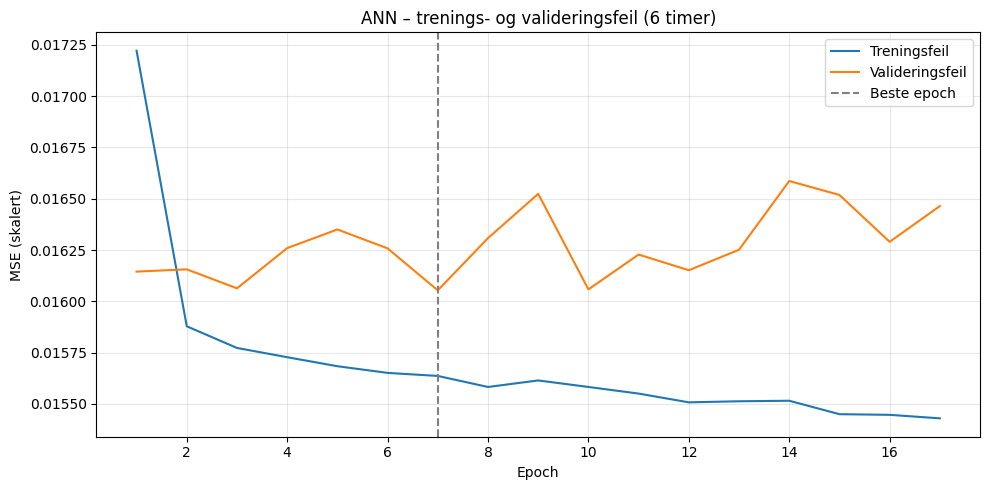

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(train_losses_ann_6h) + 1),
    train_losses_ann_6h,
    label="Treningsfeil"
)

plt.plot(
    range(1, len(val_losses_ann_6h) + 1),
    val_losses_ann_6h,
    label="Valideringsfeil"
)

plt.axvline(
    best_epoch_ann_6h,
    color="gray",
    linestyle="--",
    label="Beste epoch"
)

plt.xlabel("Epoch")
plt.ylabel("MSE (skalert)")
plt.title("ANN – trenings- og valideringsfeil (6 timer)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "ann_6h_training.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
X_test_tensor_ann_6h = torch.tensor(
    X_test_scaled_ann_6h,
    dtype=torch.float32
)

ann_model_6h.eval()

with torch.no_grad():
    y_pred_scaled_ann_6h = (
        ann_model_6h(X_test_tensor_ann_6h)
        .cpu()
        .numpy()
    )

# Transformasjon tilbake til m/s
y_pred_ann_6h = (
    scaler_y_ann_6h
    .inverse_transform(y_pred_scaled_ann_6h)
    .flatten()
)

In [ ]:
mse_ann_6h = mean_squared_error(
    y_test_ann_6h,
    y_pred_ann_6h
)

rmse_ann_6h = np.sqrt(mse_ann_6h)

mae_ann_6h = mean_absolute_error(
    y_test_ann_6h,
    y_pred_ann_6h
)

r2_ann_6h = r2_score(
    y_test_ann_6h,
    y_pred_ann_6h
)

print("ANN – 6-timersdata")
print("--------------------------")
print(f"MSE:  {mse_ann_6h:.4f}")
print(f"RMSE: {rmse_ann_6h:.4f}")
print(f"MAE:  {mae_ann_6h:.4f}")
print(f"R²:   {r2_ann_6h:.4f}")

ANN – 6-timersdata
--------------------------
MSE:  17.3493
RMSE: 4.1653
MAE:  3.3782
R²:   0.0606


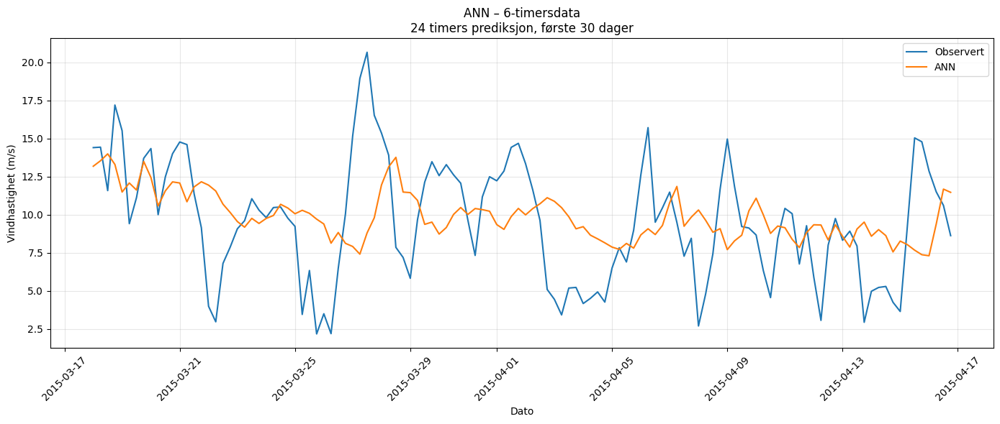

In [ ]:
n_plot_ann_6h = 30 * 4

plt.figure(figsize=(14, 6))

plt.plot(
    dates_test_ann_6h.iloc[:n_plot_ann_6h],
    y_test_ann_6h[:n_plot_ann_6h],
    label="Observert",
    linewidth=1.5
)

plt.plot(
    dates_test_ann_6h.iloc[:n_plot_ann_6h],
    y_pred_ann_6h[:n_plot_ann_6h],
    label="ANN",
    linewidth=1.5
)

plt.xlabel("Dato")
plt.ylabel("Vindhastighet (m/s)")

plt.title(
    "ANN – 6-timersdata\n"
    "24 timers prediksjon, første 30 dager"
)

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "ann_6h_prediction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

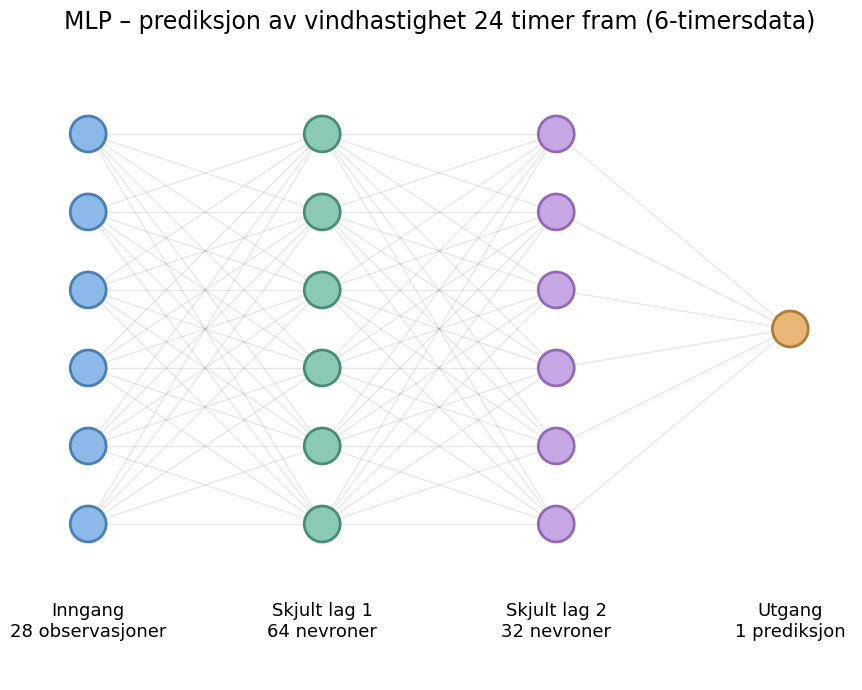

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import numpy as np

# ANN-arkitektur for 6-timersdata
layer_sizes = [28, 64, 32, 1]

layer_names = [
    "Inngang\n28 observasjoner",
    "Skjult lag 1\n64 nevroner",
    "Skjult lag 2\n32 nevroner",
    "Utgang\n1 prediksjon"
]

# Antall nevroner som vises i figuren
display_sizes = [6, 6, 6, 1]

colors = [
    "#8DB9E8",
    "#8CC9B5",
    "#C6A7E4",
    "#E8B778"
]

edge_colors = [
    "#487FB5",
    "#458D78",
    "#9468B7",
    "#B17B35"
]

fig, ax = plt.subplots(figsize=(14, 7))

x_positions = [0, 3, 6, 9]

neuron_positions = []

# Tegn nevronene
for layer_idx, n in enumerate(display_sizes):

    y_positions = np.linspace(
        -(n - 1) / 2,
        (n - 1) / 2,
        n
    )

    positions = []

    for y in y_positions:

        x = x_positions[layer_idx]

        positions.append((x, y))

        neuron = Circle(
            (x, y),
            radius=0.23,
            facecolor=colors[layer_idx],
            edgecolor=edge_colors[layer_idx],
            linewidth=2,
            zorder=3
        )

        ax.add_patch(neuron)

    neuron_positions.append(positions)

# Tegn forbindelsene
for layer_idx in range(len(display_sizes) - 1):

    for x1, y1 in neuron_positions[layer_idx]:

        for x2, y2 in neuron_positions[layer_idx + 1]:

            ax.plot(
                [x1, x2],
                [y1, y2],
                color="gray",
                alpha=0.18,
                linewidth=1,
                zorder=1
            )

# Legg til navn under lagene
for i, label in enumerate(layer_names):

    ax.text(
        x_positions[i],
        -3.5,
        label,
        ha="center",
        va="top",
        fontsize=13
    )

ax.set_title(
    "MLP – prediksjon av vindhastighet 24 timer fram (6-timersdata)",
    fontsize=17,
    pad=25
)

ax.set_xlim(-0.8, 9.8)
ax.set_ylim(-4.5, 3.4)

ax.set_aspect("equal")
ax.axis("off")

plt.tight_layout()

# Lagre figuren
plt.savefig(
    "ann_6h_architecture.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "ann_6h_architecture.pdf",
    bbox_inches="tight"
)

plt.show()

#### 12 timer

In [ ]:

# Reproduserbarhet
np.random.seed(42)
torch.manual_seed(42)

# Kopier datasettet
df_ann_12h = df_12h.copy()

df_ann_12h["datetime"] = pd.to_datetime(
    df_ann_12h["datetime"]
)

df_ann_12h = (
    df_ann_12h
    .sort_values("datetime")
    .reset_index(drop=True)
)

print("Antall observasjoner:", len(df_ann_12h))
print(df_ann_12h[["datetime", "value"]].head())

Antall observasjoner: 17520
             datetime      value
0 1996-01-01 00:00:00  25.690936
1 1996-01-01 12:00:00  29.241405
2 1996-01-02 00:00:00  25.260174
3 1996-01-02 12:00:00  20.330881
4 1996-01-03 00:00:00   9.431920


In [ ]:
p_ann_12h = 14
h_ann_12h = 2

# Lag 14 lagvariabler
lag_data_ann_12h = {
    f"lag_{i}": df_ann_12h["value"].shift(i)
    for i in range(p_ann_12h)
}

df_ann_12h = pd.concat(
    [
        df_ann_12h,
        pd.DataFrame(lag_data_ann_12h)
    ],
    axis=1
)

lag_cols_ann_12h = [
    f"lag_{i}" for i in range(p_ann_12h)
]

# Målvariabel: vindhastighet 24 timer fram
df_ann_12h["target"] = (
    df_ann_12h["value"].shift(-h_ann_12h)
)

df_ann_12h["target_datetime"] = (
    df_ann_12h["datetime"].shift(-h_ann_12h)
)

df_ann_12h = (
    df_ann_12h
    .dropna(
        subset=lag_cols_ann_12h
        + ["target", "target_datetime"]
    )
    .reset_index(drop=True)
)

print("Antall observasjoner etter lag:", len(df_ann_12h))

Antall observasjoner etter lag: 17505


In [ ]:
df_ann_12h = (
    df_12h.copy()
    .assign(
        datetime=lambda d: pd.to_datetime(d["datetime"])
    )
    .sort_values("datetime")
    .reset_index(drop=True)
)

p_ann_12h = 14
h_ann_12h = 2

lag_cols_ann_12h = [
    f"lag_{i}" for i in range(p_ann_12h)
]

for i in range(p_ann_12h):
    df_ann_12h[f"lag_{i}"] = (
        df_ann_12h["value"].shift(i)
    )

df_ann_12h["target"] = (
    df_ann_12h["value"].shift(-h_ann_12h)
)

df_ann_12h["target_datetime"] = (
    df_ann_12h["datetime"].shift(-h_ann_12h)
)

# Kontroller historikken
delta_ann_12h = df_ann_12h["datetime"].diff()

gyldige_steg_ann_12h = (
    delta_ann_12h.eq(pd.Timedelta(hours=12))
)

gyldig_historikk_ann_12h = (
    gyldige_steg_ann_12h
    .rolling(
        p_ann_12h - 1,
        min_periods=p_ann_12h - 1
    )
    .sum()
    .eq(p_ann_12h - 1)
)

# Kontroller de to framtidige tidsstegene
gyldig_framtid_ann_12h = pd.Series(
    True,
    index=df_ann_12h.index
)

for i in range(1, h_ann_12h + 1):
    gyldig_framtid_ann_12h &= (
        df_ann_12h["datetime"].shift(-i)
        - df_ann_12h["datetime"].shift(-(i - 1))
    ).eq(pd.Timedelta(hours=12))

antall_for_ann_12h = len(df_ann_12h)

df_ann_12h = (
    df_ann_12h.loc[
        gyldig_historikk_ann_12h
        & gyldig_framtid_ann_12h
    ]
    .dropna(
        subset=lag_cols_ann_12h
        + ["target", "target_datetime"]
    )
    .reset_index(drop=True)
)

print("Observasjoner før kontroll:", antall_for_ann_12h)
print("Gyldige prognoser:", len(df_ann_12h))

Observasjoner før kontroll: 17520
Gyldige prognoser: 17415


In [ ]:
n_ann_12h = len(df_ann_12h)

split_test_ann_12h = int(n_ann_12h * 0.8)
split_val_ann_12h = int(split_test_ann_12h * 0.9)

# Mellomrom mellom periodene
fit_end_ann_12h = split_val_ann_12h - h_ann_12h
val_end_ann_12h = split_test_ann_12h - h_ann_12h

df_fit_ann_12h = df_ann_12h.iloc[:fit_end_ann_12h]

df_val_ann_12h = df_ann_12h.iloc[
    split_val_ann_12h:val_end_ann_12h
]

df_test_ann_12h = df_ann_12h.iloc[
    split_test_ann_12h:
]

X_fit_ann_12h = df_fit_ann_12h[lag_cols_ann_12h]
X_val_ann_12h = df_val_ann_12h[lag_cols_ann_12h]
X_test_ann_12h = df_test_ann_12h[lag_cols_ann_12h]

y_fit_ann_12h = df_fit_ann_12h["target"]
y_val_ann_12h = df_val_ann_12h["target"]

y_test_ann_12h = (
    df_test_ann_12h["target"].to_numpy()
)

dates_test_ann_12h = (
    df_test_ann_12h["target_datetime"]
    .reset_index(drop=True)
)

print("Trening:", len(X_fit_ann_12h))
print("Validering:", len(X_val_ann_12h))
print("Test:", len(X_test_ann_12h))

Trening: 12536
Validering: 1392
Test: 3483


In [ ]:
scaler_X_ann_12h = MinMaxScaler()
scaler_y_ann_12h = MinMaxScaler()

X_fit_scaled_ann_12h = scaler_X_ann_12h.fit_transform(
    X_fit_ann_12h
)

X_val_scaled_ann_12h = scaler_X_ann_12h.transform(
    X_val_ann_12h
)

X_test_scaled_ann_12h = scaler_X_ann_12h.transform(
    X_test_ann_12h
)

y_fit_scaled_ann_12h = scaler_y_ann_12h.fit_transform(
    y_fit_ann_12h.to_numpy().reshape(-1, 1)
)

y_val_scaled_ann_12h = scaler_y_ann_12h.transform(
    y_val_ann_12h.to_numpy().reshape(-1, 1)
)

In [ ]:
class WindANN(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)


ann_model_12h = WindANN(
    input_size=p_ann_12h
)

print(ann_model_12h)

print(
    "Antall trenbare parametere:",
    sum(
        p.numel()
        for p in ann_model_12h.parameters()
        if p.requires_grad
    )
)

WindANN(
  (network): Sequential(
    (0): Linear(in_features=14, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)
Antall trenbare parametere: 3073


In [ ]:
X_fit_tensor_ann_12h = torch.tensor(
    X_fit_scaled_ann_12h,
    dtype=torch.float32
)

y_fit_tensor_ann_12h = torch.tensor(
    y_fit_scaled_ann_12h,
    dtype=torch.float32
)

X_val_tensor_ann_12h = torch.tensor(
    X_val_scaled_ann_12h,
    dtype=torch.float32
)

y_val_tensor_ann_12h = torch.tensor(
    y_val_scaled_ann_12h,
    dtype=torch.float32
)

train_dataset_ann_12h = TensorDataset(
    X_fit_tensor_ann_12h,
    y_fit_tensor_ann_12h
)

train_loader_ann_12h = DataLoader(
    train_dataset_ann_12h,
    batch_size=32,
    shuffle=True
)

In [ ]:
criterion_ann_12h = nn.MSELoss()

optimizer_ann_12h = torch.optim.Adam(
    ann_model_12h.parameters(),
    lr=0.001
)

epochs_ann_12h = 100
patience_ann_12h = 10

best_val_loss_ann_12h = float("inf")
best_state_ann_12h = None
best_epoch_ann_12h = 0
wait_ann_12h = 0

train_losses_ann_12h = []
val_losses_ann_12h = []

for epoch in range(epochs_ann_12h):

    ann_model_12h.train()
    total_loss = 0.0

    for X_batch, y_batch in train_loader_ann_12h:

        optimizer_ann_12h.zero_grad()

        y_batch_pred = ann_model_12h(X_batch)

        loss = criterion_ann_12h(
            y_batch_pred,
            y_batch
        )

        loss.backward()
        optimizer_ann_12h.step()

        total_loss += loss.item() * len(X_batch)

    train_loss = (
        total_loss / len(X_fit_tensor_ann_12h)
    )

    ann_model_12h.eval()

    with torch.no_grad():
        val_pred = ann_model_12h(
            X_val_tensor_ann_12h
        )

        val_loss = criterion_ann_12h(
            val_pred,
            y_val_tensor_ann_12h
        ).item()

    train_losses_ann_12h.append(train_loss)
    val_losses_ann_12h.append(val_loss)

    if val_loss < best_val_loss_ann_12h:

        best_val_loss_ann_12h = val_loss

        best_state_ann_12h = copy.deepcopy(
            ann_model_12h.state_dict()
        )

        best_epoch_ann_12h = epoch + 1
        wait_ann_12h = 0

    else:
        wait_ann_12h += 1

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1}: "
            f"Train MSE = {train_loss:.6f}, "
            f"Val MSE = {val_loss:.6f}"
        )

    if wait_ann_12h >= patience_ann_12h:
        print(
            f"Early stopping ved epoch {epoch + 1}"
        )
        break

# Gjenopprett beste modell
ann_model_12h.load_state_dict(
    best_state_ann_12h
)

print("Beste epoch:", best_epoch_ann_12h)
print("Beste validerings-MSE:", best_val_loss_ann_12h)

Epoch 10: Train MSE = 0.019117, Val MSE = 0.019503
Epoch 20: Train MSE = 0.018903, Val MSE = 0.019447
Early stopping ved epoch 23
Beste epoch: 13
Beste validerings-MSE: 0.019354138523340225


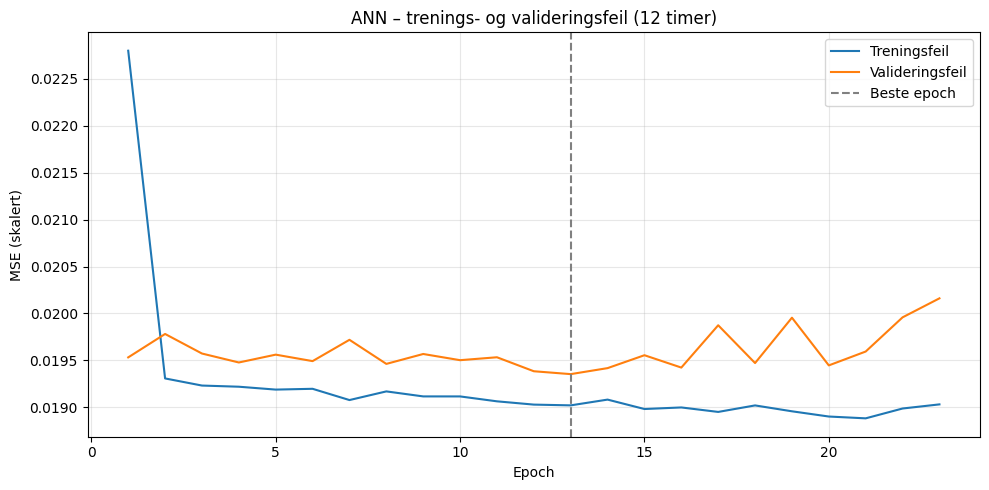

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(train_losses_ann_12h) + 1),
    train_losses_ann_12h,
    label="Treningsfeil"
)

plt.plot(
    range(1, len(val_losses_ann_12h) + 1),
    val_losses_ann_12h,
    label="Valideringsfeil"
)

plt.axvline(
    best_epoch_ann_12h,
    color="gray",
    linestyle="--",
    label="Beste epoch"
)

plt.xlabel("Epoch")
plt.ylabel("MSE (skalert)")

plt.title(
    "ANN – trenings- og valideringsfeil (12 timer)"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "ann_12h_training.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
X_test_tensor_ann_12h = torch.tensor(
    X_test_scaled_ann_12h,
    dtype=torch.float32
)

ann_model_12h.eval()

with torch.no_grad():
    y_pred_scaled_ann_12h = (
        ann_model_12h(X_test_tensor_ann_12h)
        .cpu()
        .numpy()
    )

# Transformasjon tilbake til m/s
y_pred_ann_12h = (
    scaler_y_ann_12h
    .inverse_transform(y_pred_scaled_ann_12h)
    .flatten()
)

In [ ]:
mse_ann_12h = mean_squared_error(
    y_test_ann_12h,
    y_pred_ann_12h
)

rmse_ann_12h = np.sqrt(mse_ann_12h)

mae_ann_12h = mean_absolute_error(
    y_test_ann_12h,
    y_pred_ann_12h
)

r2_ann_12h = r2_score(
    y_test_ann_12h,
    y_pred_ann_12h
)

print("ANN – 12-timersdata")
print("--------------------------")
print(f"MSE:  {mse_ann_12h:.4f}")
print(f"RMSE: {rmse_ann_12h:.4f}")
print(f"MAE:  {mae_ann_12h:.4f}")
print(f"R²:   {r2_ann_12h:.4f}")

ANN – 12-timersdata
--------------------------
MSE:  15.3557
RMSE: 3.9186
MAE:  3.1807
R²:   0.0808


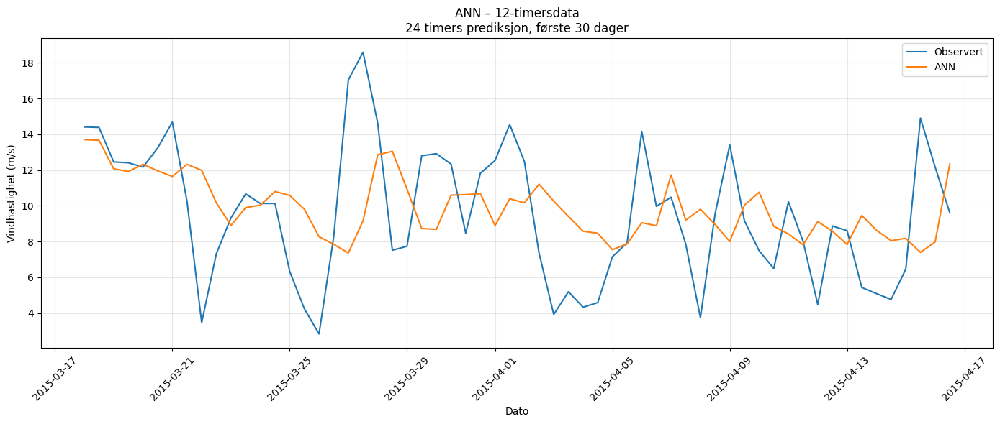

In [ ]:
n_plot_ann_12h = 30 * 2

plt.figure(figsize=(14, 6))

plt.plot(
    dates_test_ann_12h.iloc[:n_plot_ann_12h],
    y_test_ann_12h[:n_plot_ann_12h],
    label="Observert",
    linewidth=1.5
)

plt.plot(
    dates_test_ann_12h.iloc[:n_plot_ann_12h],
    y_pred_ann_12h[:n_plot_ann_12h],
    label="ANN",
    linewidth=1.5
)

plt.xlabel("Dato")
plt.ylabel("Vindhastighet (m/s)")

plt.title(
    "ANN – 12-timersdata\n"
    "24 timers prediksjon, første 30 dager"
)

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "ann_12h_prediction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### daglig


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import copy

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Reproduserbarhet
np.random.seed(42)
torch.manual_seed(42)

# Kopier datasettet
df_ann_daily = df_daily.copy()

# Finn datokolonnen
if "datetime" in df_ann_daily.columns:
    date_col_ann_daily = "datetime"
elif "date" in df_ann_daily.columns:
    date_col_ann_daily = "date"
else:
    raise ValueError("Fant ingen dato- eller datetime-kolonne.")

df_ann_daily["datetime"] = pd.to_datetime(
    df_ann_daily[date_col_ann_daily]
)

df_ann_daily = (
    df_ann_daily
    .sort_values("datetime")
    .reset_index(drop=True)
)

print("Antall observasjoner:", len(df_ann_daily))
print(df_ann_daily[["datetime", "value"]].head())

Antall observasjoner: 8760
    datetime      value
0 1996-01-01  27.466171
1 1996-01-02  22.795527
2 1996-01-03   9.255732
3 1996-01-04  13.591242
4 1996-01-05  12.153363


In [ ]:
p_ann_daily = 7 #uke
h_ann_daily = 1 #24 timer

# Lag syv lagvariabler
lag_cols_ann_daily = [
    f"lag_{i}" for i in range(p_ann_daily)
]

for i in range(p_ann_daily):
    df_ann_daily[f"lag_{i}"] = (
        df_ann_daily["value"].shift(i)
    )

# Målvariabel: vindhastighet neste dag
df_ann_daily["target"] = (
    df_ann_daily["value"].shift(-h_ann_daily)
)

df_ann_daily["target_datetime"] = (
    df_ann_daily["datetime"].shift(-h_ann_daily)
)

# Kontroller at historikken består av påfølgende dager
delta_ann_daily = df_ann_daily["datetime"].diff()

gyldige_steg_ann_daily = (
    delta_ann_daily.eq(pd.Timedelta(days=1))
)

gyldig_historikk_ann_daily = (
    gyldige_steg_ann_daily
    .rolling(
        p_ann_daily - 1,
        min_periods=p_ann_daily - 1
    )
    .sum()
    .eq(p_ann_daily - 1)
)

# Kontroller at målvariabelen ligger én dag fram
gyldig_horisont_ann_daily = (
    df_ann_daily["target_datetime"]
    - df_ann_daily["datetime"]
).eq(pd.Timedelta(days=1))

antall_for_ann_daily = len(df_ann_daily)

df_ann_daily = (
    df_ann_daily.loc[
        gyldig_historikk_ann_daily
        & gyldig_horisont_ann_daily
    ]
    .dropna(
        subset=lag_cols_ann_daily
        + ["target", "target_datetime"]
    )
    .reset_index(drop=True)
)

print("Observasjoner før kontroll:", antall_for_ann_daily)
print("Gyldige prognoser:", len(df_ann_daily))
print("Antall inngangsvariabler:", len(lag_cols_ann_daily))

Observasjoner før kontroll: 8760
Gyldige prognoser: 8711
Antall inngangsvariabler: 7


In [ ]:
n_ann_daily = len(df_ann_daily)

split_test_ann_daily = int(n_ann_daily * 0.8)
split_val_ann_daily = int(split_test_ann_daily * 0.9)

# Mellomrom mellom periodene
fit_end_ann_daily = (
    split_val_ann_daily - h_ann_daily
)

val_end_ann_daily = (
    split_test_ann_daily - h_ann_daily
)

df_fit_ann_daily = df_ann_daily.iloc[
    :fit_end_ann_daily
]

df_val_ann_daily = df_ann_daily.iloc[
    split_val_ann_daily:val_end_ann_daily
]

df_test_ann_daily = df_ann_daily.iloc[
    split_test_ann_daily:
]

X_fit_ann_daily = df_fit_ann_daily[lag_cols_ann_daily]
X_val_ann_daily = df_val_ann_daily[lag_cols_ann_daily]
X_test_ann_daily = df_test_ann_daily[lag_cols_ann_daily]

y_fit_ann_daily = df_fit_ann_daily["target"]
y_val_ann_daily = df_val_ann_daily["target"]

y_test_ann_daily = (
    df_test_ann_daily["target"].to_numpy()
)

dates_test_ann_daily = (
    df_test_ann_daily["target_datetime"]
    .reset_index(drop=True)
)

print("Trening:", len(X_fit_ann_daily))
print("Validering:", len(X_val_ann_daily))
print("Test:", len(X_test_ann_daily))

Trening: 6270
Validering: 696
Test: 1743


In [ ]:
scaler_X_ann_daily = MinMaxScaler()
scaler_y_ann_daily = MinMaxScaler()

X_fit_scaled_ann_daily = (
    scaler_X_ann_daily.fit_transform(
        X_fit_ann_daily
    )
)

X_val_scaled_ann_daily = (
    scaler_X_ann_daily.transform(
        X_val_ann_daily
    )
)

X_test_scaled_ann_daily = (
    scaler_X_ann_daily.transform(
        X_test_ann_daily
    )
)

y_fit_scaled_ann_daily = (
    scaler_y_ann_daily.fit_transform(
        y_fit_ann_daily.to_numpy().reshape(-1, 1)
    )
)

y_val_scaled_ann_daily = (
    scaler_y_ann_daily.transform(
        y_val_ann_daily.to_numpy().reshape(-1, 1)
    )
)

In [ ]:
class WindANN(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)


ann_model_daily = WindANN(
    input_size=p_ann_daily
)

print(ann_model_daily)

print(
    "Antall trenbare parametere:",
    sum(
        p.numel()
        for p in ann_model_daily.parameters()
        if p.requires_grad
    )
)

WindANN(
  (network): Sequential(
    (0): Linear(in_features=7, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)
Antall trenbare parametere: 2625


In [ ]:
X_fit_tensor_ann_daily = torch.tensor(
    X_fit_scaled_ann_daily,
    dtype=torch.float32
)

y_fit_tensor_ann_daily = torch.tensor(
    y_fit_scaled_ann_daily,
    dtype=torch.float32
)

X_val_tensor_ann_daily = torch.tensor(
    X_val_scaled_ann_daily,
    dtype=torch.float32
)

y_val_tensor_ann_daily = torch.tensor(
    y_val_scaled_ann_daily,
    dtype=torch.float32
)

train_dataset_ann_daily = TensorDataset(
    X_fit_tensor_ann_daily,
    y_fit_tensor_ann_daily
)

train_loader_ann_daily = DataLoader(
    train_dataset_ann_daily,
    batch_size=32,
    shuffle=True
)

In [ ]:
criterion_ann_daily = nn.MSELoss()

optimizer_ann_daily = torch.optim.Adam(
    ann_model_daily.parameters(),
    lr=0.001
)

epochs_ann_daily = 100
patience_ann_daily = 10

best_val_loss_ann_daily = float("inf")
best_state_ann_daily = None
best_epoch_ann_daily = 0
wait_ann_daily = 0

train_losses_ann_daily = []
val_losses_ann_daily = []

for epoch in range(epochs_ann_daily):

    ann_model_daily.train()
    total_loss = 0.0

    for X_batch, y_batch in train_loader_ann_daily:

        optimizer_ann_daily.zero_grad()

        y_batch_pred = ann_model_daily(X_batch)

        loss = criterion_ann_daily(
            y_batch_pred,
            y_batch
        )

        loss.backward()
        optimizer_ann_daily.step()

        total_loss += loss.item() * len(X_batch)

    train_loss = (
        total_loss / len(X_fit_tensor_ann_daily)
    )

    ann_model_daily.eval()

    with torch.no_grad():

        val_pred = ann_model_daily(
            X_val_tensor_ann_daily
        )

        val_loss = criterion_ann_daily(
            val_pred,
            y_val_tensor_ann_daily
        ).item()

    train_losses_ann_daily.append(train_loss)
    val_losses_ann_daily.append(val_loss)

    if val_loss < best_val_loss_ann_daily:

        best_val_loss_ann_daily = val_loss

        best_state_ann_daily = copy.deepcopy(
            ann_model_daily.state_dict()
        )

        best_epoch_ann_daily = epoch + 1
        wait_ann_daily = 0

    else:
        wait_ann_daily += 1

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1}: "
            f"Train MSE = {train_loss:.6f}, "
            f"Val MSE = {val_loss:.6f}"
        )

    if wait_ann_daily >= patience_ann_daily:
        print(
            f"Early stopping ved epoch {epoch + 1}"
        )
        break

# Gjenopprett modellen fra beste epoch
ann_model_daily.load_state_dict(
    best_state_ann_daily
)

print("Beste epoch:", best_epoch_ann_daily)
print("Beste validerings-MSE:", best_val_loss_ann_daily)

Epoch 10: Train MSE = 0.020546, Val MSE = 0.021442
Early stopping ved epoch 18
Beste epoch: 8
Beste validerings-MSE: 0.020204614847898483


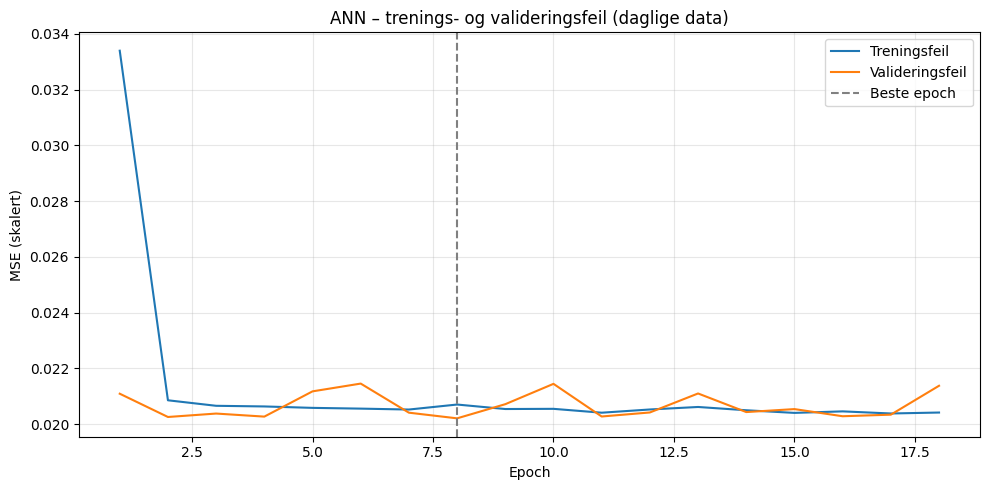

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(train_losses_ann_daily) + 1),
    train_losses_ann_daily,
    label="Treningsfeil"
)

plt.plot(
    range(1, len(val_losses_ann_daily) + 1),
    val_losses_ann_daily,
    label="Valideringsfeil"
)

plt.axvline(
    best_epoch_ann_daily,
    color="gray",
    linestyle="--",
    label="Beste epoch"
)

plt.xlabel("Epoch")
plt.ylabel("MSE (skalert)")

plt.title(
    "ANN – trenings- og valideringsfeil (daglige data)"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "ann_daily_training.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
X_test_tensor_ann_daily = torch.tensor(
    X_test_scaled_ann_daily,
    dtype=torch.float32
)

ann_model_daily.eval()

with torch.no_grad():

    y_pred_scaled_ann_daily = (
        ann_model_daily(X_test_tensor_ann_daily)
        .cpu()
        .numpy()
    )

# Transformasjon tilbake til m/s
y_pred_ann_daily = (
    scaler_y_ann_daily
    .inverse_transform(y_pred_scaled_ann_daily)
    .flatten()
)

In [ ]:
mse_ann_daily = mean_squared_error(
    y_test_ann_daily,
    y_pred_ann_daily
)

rmse_ann_daily = np.sqrt(mse_ann_daily)

mae_ann_daily = mean_absolute_error(
    y_test_ann_daily,
    y_pred_ann_daily
)

r2_ann_daily = r2_score(
    y_test_ann_daily,
    y_pred_ann_daily
)

print("ANN – daglige data")
print("--------------------------")
print(f"MSE:  {mse_ann_daily:.4f}")
print(f"RMSE: {rmse_ann_daily:.4f}")
print(f"MAE:  {mae_ann_daily:.4f}")
print(f"R²:   {r2_ann_daily:.4f}")

ANN – daglige data
--------------------------
MSE:  10.9385
RMSE: 3.3073
MAE:  2.6736
R²:   0.1847


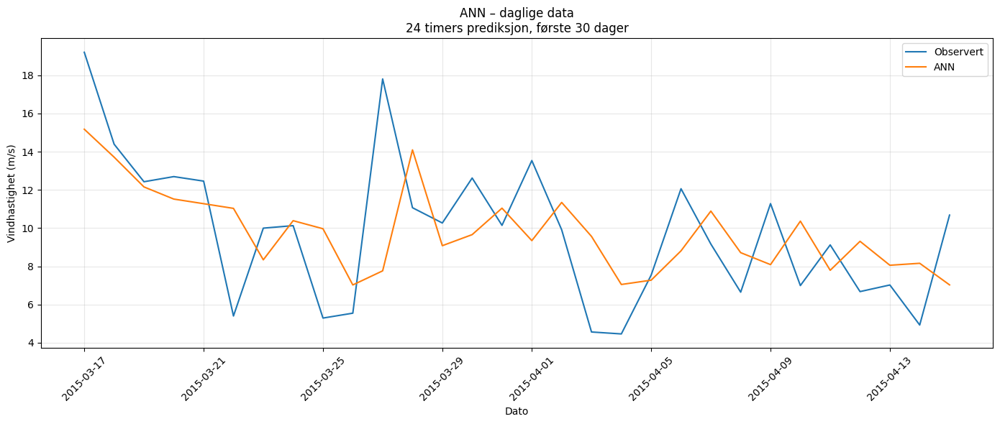

In [ ]:
start_ann_daily = dates_test_ann_daily.iloc[0]
slutt_ann_daily = start_ann_daily + pd.Timedelta(days=30)

mask_plot_ann_daily = (
    dates_test_ann_daily < slutt_ann_daily
)

plt.figure(figsize=(14, 6))

plt.plot(
    dates_test_ann_daily[mask_plot_ann_daily],
    y_test_ann_daily[mask_plot_ann_daily.to_numpy()],
    label="Observert",
    linewidth=1.5
)

plt.plot(
    dates_test_ann_daily[mask_plot_ann_daily],
    y_pred_ann_daily[mask_plot_ann_daily.to_numpy()],
    label="ANN",
    linewidth=1.5
)

plt.xlabel("Dato")
plt.ylabel("Vindhastighet (m/s)")

plt.title(
    "ANN – daglige data\n"
    "24 timers prediksjon, første 30 dager"
)

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "ann_daily_prediction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### sesong justert

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import copy

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

np.random.seed(42)
torch.manual_seed(42)

df_ann_seasonal = df_daily.copy()

# Finn datokolonnen
if "datetime" in df_ann_seasonal.columns:
    date_col = "datetime"
elif "date" in df_ann_seasonal.columns:
    date_col = "date"
else:
    raise ValueError("Fant ingen datokolonne.")

df_ann_seasonal["datetime"] = pd.to_datetime(
    df_ann_seasonal[date_col]
)

df_ann_seasonal = (
    df_ann_seasonal[["datetime", "value"]]
    .dropna()
    .sort_values("datetime")
    .reset_index(drop=True)
)

# Forutsetter at 29. februar allerede er fjernet
assert not (
    (df_ann_seasonal["datetime"].dt.month == 2)
    & (df_ann_seasonal["datetime"].dt.day == 29)
).any(), "29. februar finnes fortsatt i datasettet."

if df_ann_seasonal["datetime"].dt.normalize().duplicated().any():
    raise ValueError("Flere observasjoner på samme dato.")

print(df_ann_seasonal.head())
print("Antall observasjoner:", len(df_ann_seasonal))

    datetime      value
0 1996-01-01  27.466171
1 1996-01-02  22.795527
2 1996-01-03   9.255732
3 1996-01-04  13.591242
4 1996-01-05  12.153363
Antall observasjoner: 8760


In [ ]:
# Dagnummer i kalender uten 29. februar
df_ann_seasonal["day_365"] = (
    df_ann_seasonal["datetime"].dt.dayofyear
    - (
        df_ann_seasonal["datetime"].dt.is_leap_year
        & (df_ann_seasonal["datetime"].dt.month > 2)
    ).astype(int)
)

# Sammenhengende indeks uten skudddager
df_ann_seasonal["day_index"] = (
    df_ann_seasonal["datetime"].dt.year * 365
    + df_ann_seasonal["day_365"]
)

# Harmoniske sesongvariabler
df_ann_seasonal["cos_season"] = np.cos(
    2 * np.pi * df_ann_seasonal["day_365"] / 365
)

df_ann_seasonal["sin_season"] = np.sin(
    2 * np.pi * df_ann_seasonal["day_365"] / 365
)

print(
    df_ann_seasonal[
        ["datetime", "day_365", "cos_season", "sin_season"]
    ].head()
)

    datetime  day_365  cos_season  sin_season
0 1996-01-01        1    0.999852    0.017213
1 1996-01-02        2    0.999407    0.034422
2 1996-01-03        3    0.998667    0.051620
3 1996-01-04        4    0.997630    0.068802
4 1996-01-05        5    0.996298    0.085965


In [ ]:
p_ann_seasonal = 7
h_ann_seasonal = 1

# Lagvariabler fra vindhastigheten
lag_cols_raw = [
    f"raw_lag_{i}" for i in range(p_ann_seasonal)
]

for i in range(p_ann_seasonal):
    df_ann_seasonal[f"raw_lag_{i}"] = (
        df_ann_seasonal["value"].shift(i)
    )

# Målvariabel
df_ann_seasonal["target_value"] = (
    df_ann_seasonal["value"].shift(-h_ann_seasonal)
)

df_ann_seasonal["target_datetime"] = (
    df_ann_seasonal["datetime"].shift(-h_ann_seasonal)
)

# Tidsindeks for målvariabelen
df_ann_seasonal["target_day_index"] = (
    df_ann_seasonal["day_index"].shift(-h_ann_seasonal)
)

# Kontroller historikken
valid_step = (
    df_ann_seasonal["day_index"].diff().eq(1)
)

valid_history = (
    valid_step
    .rolling(
        p_ann_seasonal - 1,
        min_periods=p_ann_seasonal - 1
    )
    .sum()
    .eq(p_ann_seasonal - 1)
)

# Kontroller prediksjonshorisonten
valid_target = (
    df_ann_seasonal["target_day_index"]
    - df_ann_seasonal["day_index"]
).eq(1)

df_ann_seasonal = (
    df_ann_seasonal.loc[
        valid_history & valid_target
    ]
    .dropna(
        subset=lag_cols_raw + [
            "target_value",
            "target_datetime"
        ]
    )
    .reset_index(drop=True)
)

print("Gyldige prognoseobservasjoner:", len(df_ann_seasonal))

Gyldige prognoseobservasjoner: 8753


In [ ]:
n_ann_seasonal = len(df_ann_seasonal)

split_test_ann_seasonal = int(n_ann_seasonal * 0.8)
split_val_ann_seasonal = int(
    split_test_ann_seasonal * 0.9
)

fit_end_ann_seasonal = (
    split_val_ann_seasonal - h_ann_seasonal
)

val_end_ann_seasonal = (
    split_test_ann_seasonal - h_ann_seasonal
)

df_fit_ann_seasonal = df_ann_seasonal.iloc[
    :fit_end_ann_seasonal
].copy()

df_val_ann_seasonal = df_ann_seasonal.iloc[
    split_val_ann_seasonal:val_end_ann_seasonal
].copy()

df_test_ann_seasonal = df_ann_seasonal.iloc[
    split_test_ann_seasonal:
].copy()

print("Trening:", len(df_fit_ann_seasonal))
print("Validering:", len(df_val_ann_seasonal))
print("Test:", len(df_test_ann_seasonal))

Trening: 6300
Validering: 700
Test: 1751


In [ ]:
# Bruk alle observerte dager fram til siste
# tilgjengelige treningstidspunkt
last_fit_origin = df_fit_ann_seasonal["datetime"].max()

df_season_fit = df_ann_seasonal.loc[
    df_ann_seasonal["datetime"] <= last_fit_origin,
    ["datetime", "value", "cos_season", "sin_season"]
].copy()

# Designmatrise
X_season_fit = np.column_stack([
    np.ones(len(df_season_fit)),
    df_season_fit["cos_season"],
    df_season_fit["sin_season"]
])

y_season_fit = df_season_fit["value"].to_numpy()

# Minste kvadraters metode
mu_ann_seasonal, _, _, _ = np.linalg.lstsq(
    X_season_fit,
    y_season_fit,
    rcond=None
)

mu0_ann, mu1_ann, mu2_ann = mu_ann_seasonal

print(f"mu0 = {mu0_ann:.4f}")
print(f"mu1 = {mu1_ann:.4f}")
print(f"mu2 = {mu2_ann:.4f}")

mu0 = 9.4576
mu1 = 1.4119
mu2 = 0.2096


In [ ]:
X_season_all = np.column_stack([
    np.ones(len(df_ann_seasonal)),
    df_ann_seasonal["cos_season"],
    df_ann_seasonal["sin_season"]
])

df_ann_seasonal["season_estimate"] = (
    X_season_all @ mu_ann_seasonal
)

df_ann_seasonal["residual"] = (
    df_ann_seasonal["value"]
    - df_ann_seasonal["season_estimate"]
)

# Lag sesongkomponenten for målvariabelen
target_dates = pd.to_datetime(
    df_ann_seasonal["target_datetime"]
)

target_day_365 = (
    target_dates.dt.dayofyear
    - (
        target_dates.dt.is_leap_year
        & (target_dates.dt.month > 2)
    ).astype(int)
)

df_ann_seasonal["target_season"] = (
    mu0_ann
    + mu1_ann * np.cos(2 * np.pi * target_day_365 / 365)
    + mu2_ann * np.sin(2 * np.pi * target_day_365 / 365)
)

df_ann_seasonal["target_residual"] = (
    df_ann_seasonal["target_value"]
    - df_ann_seasonal["target_season"]
)

In [ ]:
lag_cols_ann_seasonal = [
    f"lag_{i}" for i in range(p_ann_seasonal)
]

# Sesongkomponent for hver lagdato
for i in range(p_ann_seasonal):

    lag_date = df_ann_seasonal["datetime"] - pd.to_timedelta(
        i, unit="D"
    )

    # Håndter kalenderen uten 29. februar:
    # Bruk den faktiske datoen fra originaldata der det er mulig.
    # Vi henter derfor lagdatoene fra den opprinnelige
    # gyldige tidsindeksen i stedet for kalenderdager.

    lag_day_365 = (
        df_ann_seasonal["day_365"] - i - 1
    ) % 365 + 1

    lag_season = (
        mu0_ann
        + mu1_ann * np.cos(2 * np.pi * lag_day_365 / 365)
        + mu2_ann * np.sin(2 * np.pi * lag_day_365 / 365)
    )

    df_ann_seasonal[f"lag_{i}"] = (
        df_ann_seasonal[f"raw_lag_{i}"]
        - lag_season
    )

# Oppdater deldatasettene med residualvariabler
df_fit_ann_seasonal = df_ann_seasonal.iloc[
    :fit_end_ann_seasonal
].copy()

df_val_ann_seasonal = df_ann_seasonal.iloc[
    split_val_ann_seasonal:val_end_ann_seasonal
].copy()

df_test_ann_seasonal = df_ann_seasonal.iloc[
    split_test_ann_seasonal:
].copy()

In [ ]:
X_fit_ann_seasonal = (
    df_fit_ann_seasonal[lag_cols_ann_seasonal]
)

X_val_ann_seasonal = (
    df_val_ann_seasonal[lag_cols_ann_seasonal]
)

X_test_ann_seasonal = (
    df_test_ann_seasonal[lag_cols_ann_seasonal]
)

y_fit_ann_seasonal = (
    df_fit_ann_seasonal["target_residual"]
)

y_val_ann_seasonal = (
    df_val_ann_seasonal["target_residual"]
)

y_test_ann_seasonal = (
    df_test_ann_seasonal["target_value"].to_numpy()
)

season_test_ann_seasonal = (
    df_test_ann_seasonal["target_season"].to_numpy()
)

dates_test_ann_seasonal = (
    df_test_ann_seasonal["target_datetime"]
    .reset_index(drop=True)
)

scaler_X_ann_seasonal = MinMaxScaler()
scaler_y_ann_seasonal = MinMaxScaler()

X_fit_scaled_ann_seasonal = (
    scaler_X_ann_seasonal.fit_transform(
        X_fit_ann_seasonal
    )
)

X_val_scaled_ann_seasonal = (
    scaler_X_ann_seasonal.transform(
        X_val_ann_seasonal
    )
)

X_test_scaled_ann_seasonal = (
    scaler_X_ann_seasonal.transform(
        X_test_ann_seasonal
    )
)

y_fit_scaled_ann_seasonal = (
    scaler_y_ann_seasonal.fit_transform(
        y_fit_ann_seasonal.to_numpy().reshape(-1, 1)
    )
)

y_val_scaled_ann_seasonal = (
    scaler_y_ann_seasonal.transform(
        y_val_ann_seasonal.to_numpy().reshape(-1, 1)
    )
)

In [ ]:
class WindANN(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)


ann_model_seasonal = WindANN(
    input_size=p_ann_seasonal
)

print(ann_model_seasonal)

print(
    "Antall trenbare parametere:",
    sum(
        p.numel()
        for p in ann_model_seasonal.parameters()
        if p.requires_grad
    )
)

WindANN(
  (network): Sequential(
    (0): Linear(in_features=7, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)
Antall trenbare parametere: 2625


In [ ]:
X_fit_tensor_ann_seasonal = torch.tensor(
    X_fit_scaled_ann_seasonal,
    dtype=torch.float32
)

y_fit_tensor_ann_seasonal = torch.tensor(
    y_fit_scaled_ann_seasonal,
    dtype=torch.float32
)

X_val_tensor_ann_seasonal = torch.tensor(
    X_val_scaled_ann_seasonal,
    dtype=torch.float32
)

y_val_tensor_ann_seasonal = torch.tensor(
    y_val_scaled_ann_seasonal,
    dtype=torch.float32
)

train_dataset_ann_seasonal = TensorDataset(
    X_fit_tensor_ann_seasonal,
    y_fit_tensor_ann_seasonal
)

train_loader_ann_seasonal = DataLoader(
    train_dataset_ann_seasonal,
    batch_size=32,
    shuffle=True
)

In [ ]:
criterion_ann_seasonal = nn.MSELoss()

optimizer_ann_seasonal = torch.optim.Adam(
    ann_model_seasonal.parameters(),
    lr=0.001
)

epochs_ann_seasonal = 100
patience_ann_seasonal = 10

best_val_loss_ann_seasonal = float("inf")
best_state_ann_seasonal = None
best_epoch_ann_seasonal = 0
wait_ann_seasonal = 0

train_losses_ann_seasonal = []
val_losses_ann_seasonal = []

for epoch in range(epochs_ann_seasonal):

    ann_model_seasonal.train()
    total_loss = 0.0

    for X_batch, y_batch in train_loader_ann_seasonal:

        optimizer_ann_seasonal.zero_grad()

        y_batch_pred = ann_model_seasonal(X_batch)

        loss = criterion_ann_seasonal(
            y_batch_pred,
            y_batch
        )

        loss.backward()
        optimizer_ann_seasonal.step()

        total_loss += loss.item() * len(X_batch)

    train_loss = (
        total_loss / len(X_fit_tensor_ann_seasonal)
    )

    ann_model_seasonal.eval()

    with torch.no_grad():

        val_pred = ann_model_seasonal(
            X_val_tensor_ann_seasonal
        )

        val_loss = criterion_ann_seasonal(
            val_pred,
            y_val_tensor_ann_seasonal
        ).item()

    train_losses_ann_seasonal.append(train_loss)
    val_losses_ann_seasonal.append(val_loss)

    if val_loss < best_val_loss_ann_seasonal:

        best_val_loss_ann_seasonal = val_loss

        best_state_ann_seasonal = copy.deepcopy(
            ann_model_seasonal.state_dict()
        )

        best_epoch_ann_seasonal = epoch + 1
        wait_ann_seasonal = 0

    else:
        wait_ann_seasonal += 1

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1}: "
            f"Train MSE = {train_loss:.6f}, "
            f"Val MSE = {val_loss:.6f}"
        )

    if wait_ann_seasonal >= patience_ann_seasonal:
        print(
            f"Early stopping ved epoch {epoch + 1}"
        )
        break

# Gjenopprett beste modell
ann_model_seasonal.load_state_dict(
    best_state_ann_seasonal
)

print("Beste epoch:", best_epoch_ann_seasonal)
print("Beste validerings-MSE:", best_val_loss_ann_seasonal)

Epoch 10: Train MSE = 0.020047, Val MSE = 0.019607
Early stopping ved epoch 13
Beste epoch: 3
Beste validerings-MSE: 0.01948322355747223


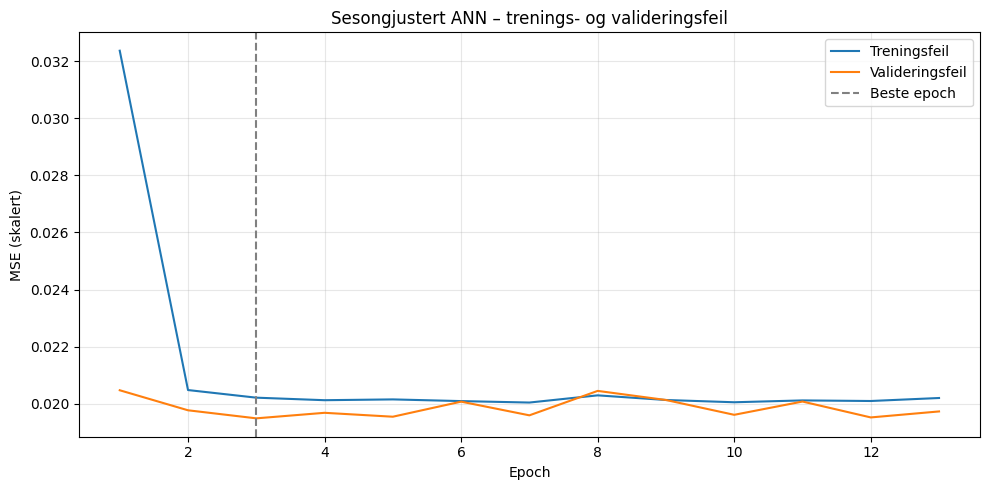

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(train_losses_ann_seasonal) + 1),
    train_losses_ann_seasonal,
    label="Treningsfeil"
)

plt.plot(
    range(1, len(val_losses_ann_seasonal) + 1),
    val_losses_ann_seasonal,
    label="Valideringsfeil"
)

plt.axvline(
    best_epoch_ann_seasonal,
    color="gray",
    linestyle="--",
    label="Beste epoch"
)

plt.xlabel("Epoch")
plt.ylabel("MSE (skalert)")
plt.title("Sesongjustert ANN – trenings- og valideringsfeil")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "ann_daily_seasonal_training.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
X_test_tensor_ann_seasonal = torch.tensor(
    X_test_scaled_ann_seasonal,
    dtype=torch.float32
)

ann_model_seasonal.eval()

with torch.no_grad():

    y_pred_residual_scaled = (
        ann_model_seasonal(X_test_tensor_ann_seasonal)
        .cpu()
        .numpy()
    )

# Residualer i opprinnelig skala
y_pred_residual_ann_seasonal = (
    scaler_y_ann_seasonal
    .inverse_transform(y_pred_residual_scaled)
    .flatten()
)

# Legg tilbake sesongkomponenten
y_pred_ann_seasonal = (
    y_pred_residual_ann_seasonal
    + season_test_ann_seasonal
)


In [ ]:
mse_ann_season = mean_squared_error(
    y_test_ann_seasonal,
    y_pred_ann_seasonal
)

rmse_ann_season = np.sqrt(mse_ann_season)

mae_ann_season = mean_absolute_error(
    y_test_ann_seasonal,
    y_pred_ann_seasonal
)

r2_ann_season = r2_score(
    y_test_ann_seasonal,
    y_pred_ann_seasonal
)

print("ANN – sesongjusterte daglige data")
print("-----------------------------------")
print(f"MSE:  {mse_ann_season:.4f}")
print(f"RMSE: {rmse_ann_season:.4f}")
print(f"MAE:  {mae_ann_season:.4f}")
print(f"R²:   {r2_ann_season:.4f}")

ANN – sesongjusterte daglige data
-----------------------------------
MSE:  10.8661
RMSE: 3.2964
MAE:  2.6711
R²:   0.1943


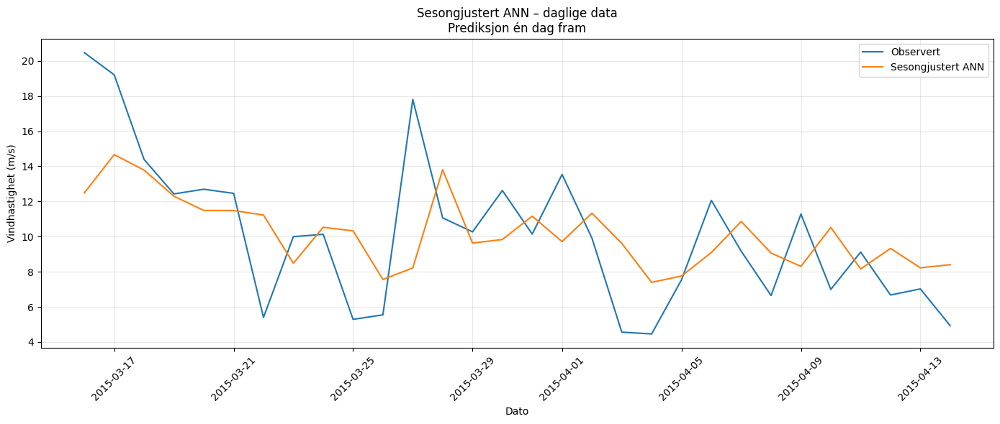

In [ ]:
n_plot_ann_seasonal = 30

plt.figure(figsize=(14, 6))

plt.plot(
    dates_test_ann_seasonal.iloc[:n_plot_ann_seasonal],
    y_test_ann_seasonal[:n_plot_ann_seasonal],
    label="Observert",
    linewidth=1.5
)

plt.plot(
    dates_test_ann_seasonal.iloc[:n_plot_ann_seasonal],
    y_pred_ann_seasonal[:n_plot_ann_seasonal],
    label="Sesongjustert ANN",
    linewidth=1.5
)

plt.xlabel("Dato")
plt.ylabel("Vindhastighet (m/s)")

plt.title(
    "Sesongjustert ANN – daglige data\n"
    "Prediksjon én dag fram"
)

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "ann_daily_seasonal_prediction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

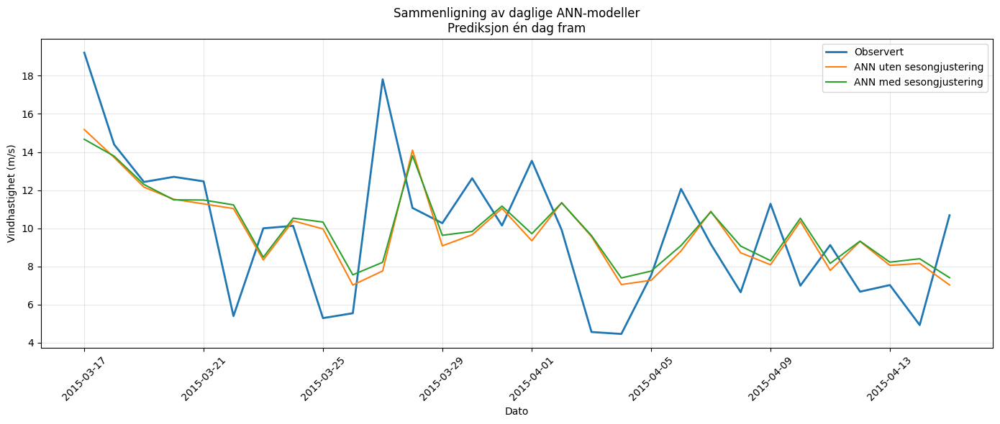

In [ ]:
df_normal_ann = pd.DataFrame({
    "datetime": dates_test_ann_daily,
    "ANN vanlig": y_pred_ann_daily
})

df_seasonal_ann = pd.DataFrame({
    "datetime": dates_test_ann_seasonal,
    "Observert": y_test_ann_seasonal,
    "ANN sesongjustert": y_pred_ann_seasonal
})

df_compare_ann = pd.merge(
    df_seasonal_ann,
    df_normal_ann,
    on="datetime",
    how="inner"
).sort_values("datetime").reset_index(drop=True)

if df_compare_ann.empty:
    raise ValueError(
        "Ingen felles testdatoer mellom modellene."
    )

# Første 30 observasjoner
df_plot_ann = df_compare_ann.iloc[:30]

plt.figure(figsize=(14, 6))

plt.plot(
    df_plot_ann["datetime"],
    df_plot_ann["Observert"],
    label="Observert",
    linewidth=2
)

plt.plot(
    df_plot_ann["datetime"],
    df_plot_ann["ANN vanlig"],
    label="ANN uten sesongjustering",
    linewidth=1.5
)

plt.plot(
    df_plot_ann["datetime"],
    df_plot_ann["ANN sesongjustert"],
    label="ANN med sesongjustering",
    linewidth=1.5
)

plt.xlabel("Dato")
plt.ylabel("Vindhastighet (m/s)")

plt.title(
    "Sammenligning av daglige ANN-modeller\n"
    "Prediksjon én dag fram"
)

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "ann_daily_seasonal_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### benchmark

In [ ]:
daily_mean["datetime"] =daily_mean["date"].dropna().reset_index(drop=True)


In [ ]:
daily_mean

,date,value,month,day,day_of_year,value_estimate,residual,datetime
0,1996-01-01,27.466171,1,1,1,10.776811,16.689359,1996-01-01
1,1996-01-02,22.795527,1,2,2,10.780486,12.015042,1996-01-02
2,1996-01-03,9.255732,1,3,3,10.783751,-1.528019,1996-01-03
3,1996-01-04,13.591242,1,4,4,10.786605,2.804637,1996-01-04
4,1996-01-05,12.153363,1,5,5,10.789048,1.364315,1996-01-05
...,...,...,...,...,...,...,...,...
8755,2019-12-27,6.869742,12,27,361,10.752339,-3.882597,2019-12-27
8756,2019-12-28,13.411871,12,28,362,10.758042,2.653829,2019-12-28
8757,2019-12-29,16.787167,12,29,363,10.763342,6.023824,2019-12-29
8758,2019-12-30,13.900942,12,30,364,10.768238,3.132704,2019-12-30


In [ ]:
df_3h

,datetime,value,year,time,name,lat,lon,row,col,locID
0,1996-01-01 00:00:00,24.978496,1996.0,227904.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
1,1996-01-01 03:00:00,24.197471,1996.0,227907.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
2,1996-01-01 06:00:00,24.593582,1996.0,227910.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
3,1996-01-01 09:00:00,28.994197,1996.0,227913.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
4,1996-01-01 12:00:00,31.685537,1996.0,227916.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
...,...,...,...,...,...,...,...,...,...,...
70123,2019-12-31 09:00:00,7.034111,2019.0,438273.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
70124,2019-12-31 12:00:00,4.900157,2019.0,438276.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
70125,2019-12-31 15:00:00,10.109447,2019.0,438279.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0
70126,2019-12-31 18:00:00,12.140149,2019.0,438282.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0


In [ ]:
df_daily

,datetime,value,year,time,name,lat,lon,row,col,locID,beaufort_category
0,1996-01-01,27.466171,1996.0,227904.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,Full storm
1,1996-01-02,22.795527,1996.0,227928.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,Liten storm
2,1996-01-03,9.255732,1996.0,227952.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,Frisk bris
3,1996-01-04,13.591242,1996.0,227976.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,Liten kuling
4,1996-01-05,12.153363,1996.0,228000.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,Liten kuling
...,...,...,...,...,...,...,...,...,...,...,...
8761,2019-12-27,6.869742,2019.0,438168.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,Laber bris
8762,2019-12-28,13.411871,2019.0,438192.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,Liten kuling
8763,2019-12-29,16.787167,2019.0,438216.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,Stiv kuling
8764,2019-12-30,13.900942,2019.0,438240.0,Nordavind A,71.120519,32.037722,202.0,1072.0,1.0,Stiv kuling


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)


# 1. Datasett og modellparametere

df_season = daily_mean.copy()

datasett_benchmark = {
    "3 timer": (df_3h, 56, 8),
    "6 timer": (df_6h, 28, 4),
    "12 timer": (df_12h, 14, 2),
    "Daglig": (df_daily, 7, 1),
    "Daglig sesongjustert": (df_season, 7, 1)
}

benchmark_results = []
benchmark_predictions = {}


# 2. Funksjon for sinus- og cosinusmodellen


def seasonal_features(dates):

    dates = pd.DatetimeIndex(pd.to_datetime(dates))

    day = dates.dayofyear.to_numpy(dtype=float)

    # Juster for skuddår, selv om 29. februar er fjernet fra datasettet
    leap = dates.is_leap_year
    after_feb = dates.month > 2

    day = day - (leap & after_feb).astype(int)

    angle = 2 * np.pi * (day - 1) / 365

    return np.column_stack([
        np.ones(len(dates)),
        np.cos(angle),
        np.sin(angle)
    ])



# 3. Lager benchmarkmodellene

for opplosning, (df, n_lags, forecast_steps) in datasett_benchmark.items():

    data = df.copy()

    data["datetime"] = pd.to_datetime(data["datetime"])

    data = (
        data.sort_values("datetime")
        .reset_index(drop=True)
    )

    # Bruk opprinnelig vindhastighet som standard
    data["model_value"] = data["value"]

    
    #  Sesongjustering (kun daglig)
    

    if opplosning == "Daglig sesongjustert":

        # Samme teststart som daglig RF
        split_date = pd.Timestamp("2015-03-15")

        train_mask = data["datetime"] < split_date

        # Tilpass sesongmodell på treningsdata
        X_season_train = seasonal_features(
            data.loc[train_mask, "datetime"]
        )

        y_season_train = data.loc[
            train_mask, "value"
        ].to_numpy()

        beta = np.linalg.lstsq(
            X_season_train,
            y_season_train,
            rcond=None
        )[0]

        # Beregn sesongestimat
        data["season_estimate"] = (
            seasonal_features(data["datetime"]) @ beta
        )

        # Beregn residualer
        data["model_value"] = (
            data["value"] - data["season_estimate"]
        )

    # ======================================
    # B. Lagvariabler
    # ======================================

    for i in range(n_lags):
        data[f"lag_{i}"] = data["model_value"].shift(i)

    lag_cols = [
        f"lag_{i}" for i in range(n_lags)
    ]

    # ======================================
    # C. Målvariabel: 24 timer fram
    # ======================================

    data["target"] = (
        data["value"].shift(-forecast_steps)
    )

    data["target_datetime"] = (
        data["datetime"].shift(-forecast_steps)
    )

    # ======================================
    # D. Sesongestimat på prediksjonstidspunkt
    # ======================================

    if opplosning == "Daglig sesongjustert":

        data["season_target"] = (
            data["season_estimate"].shift(-forecast_steps)
        )

    else:
        data["season_target"] = 0.0

    # Fjern manglende verdier
    data = data.dropna(
        subset=lag_cols + [
            "target",
            "target_datetime",
            "season_target"
        ]
    ).reset_index(drop=True)

    
    #  80/20-splitt
    split = int(len(data) * 0.8)

    test = data.iloc[split:].copy()

    
    #Benchmark 1: Persistens
    

    test["pred_persistence"] = (
        test["lag_0"] + test["season_target"]
    )

    
    # Benchmark 2: Gjennomsnitt fra uke
    

    test["pred_mean"] = (
        test[lag_cols].mean(axis=1)
        + test["season_target"]
    )

    
    # Evaluer modellene
   

    for modell, pred_col in [
        ("Persistens", "pred_persistence"),
        ("Historisk gjennomsnitt", "pred_mean")
    ]:

        y_true = test["target"]
        y_pred = test[pred_col]

        mse = mean_squared_error(y_true, y_pred)

        benchmark_results.append({
            "Modell": modell,
            "Tidsoppløsning": opplosning,
            "MSE": mse,
            "RMSE": np.sqrt(mse),
            "MAE": mean_absolute_error(y_true, y_pred),
            "R²": r2_score(y_true, y_pred)
        })

    benchmark_predictions[opplosning] = test



# Samlet resultattabell


benchmark_table = pd.DataFrame(benchmark_results)

display(benchmark_table.round(4))

,Modell,Tidsoppløsning,MSE,RMSE,MAE,R²
0,Persistens,3 timer,29.6962,5.4494,4.3042,-0.5328
1,Historisk gjennomsnitt,3 timer,21.3933,4.6253,3.7294,-0.1043
2,Persistens,6 timer,27.8867,5.2808,4.1770,-0.5053
3,Historisk gjennomsnitt,6 timer,20.4605,4.5233,3.6461,-0.1045
4,Persistens,12 timer,23.9251,4.8913,3.8772,-0.4265
5,Historisk gjennomsnitt,12 timer,18.4898,4.3000,3.4686,-0.1024
6,Persistens,Daglig,15.2789,3.9088,3.1167,-0.1329
7,Historisk gjennomsnitt,Daglig,14.4126,3.7964,3.0385,-0.0687
8,Persistens,Daglig sesongjustert,15.2786,3.9088,3.1167,-0.1329
9,Historisk gjennomsnitt,Daglig sesongjustert,14.4070,3.7957,3.0360,-0.0683


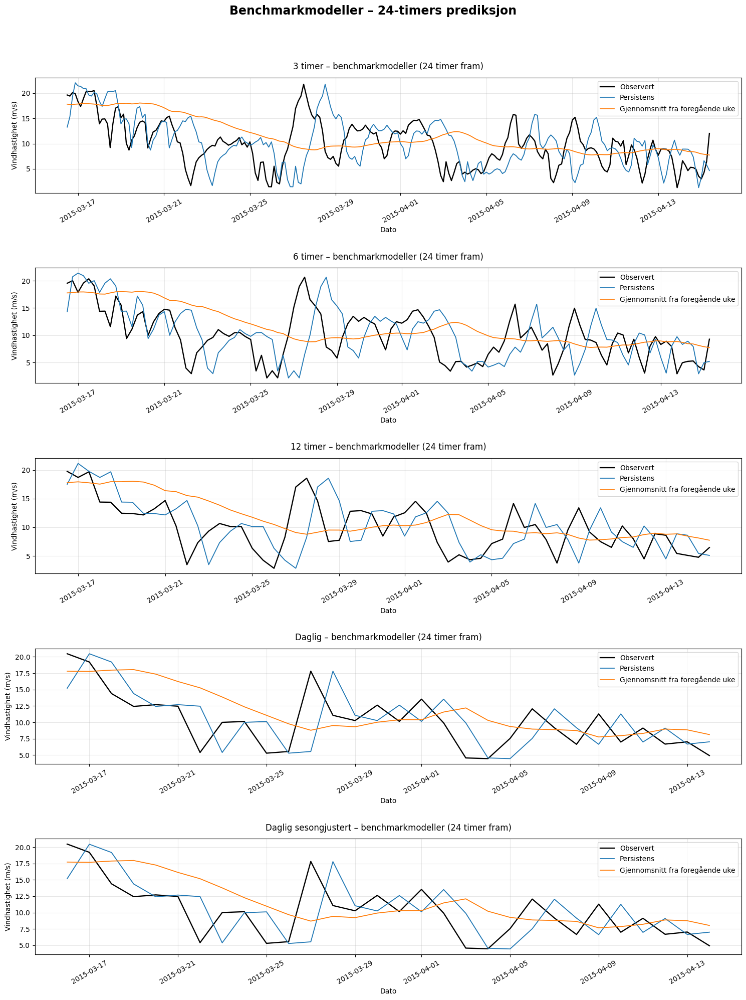

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Antall tidsoppløsninger
n_plots = len(benchmark_predictions)

fig, axes = plt.subplots(
    n_plots, 1,
    figsize=(15, 4 * n_plots),
    sharex=False
)

for ax, (opplosning, test) in zip(
    axes,
    benchmark_predictions.items()
):

    start = test["target_datetime"].iloc[0]
    slutt = start + pd.Timedelta(days=30)

    plot_data = test[
        (test["target_datetime"] >= start) &
        (test["target_datetime"] < slutt)
    ]

    # Observert vindhastighet
    ax.plot(
        plot_data["target_datetime"],
        plot_data["target"],
        color="black",
        linewidth=1.7,
        label="Observert"
    )

    # Persistensmodell
    ax.plot(
        plot_data["target_datetime"],
        plot_data["pred_persistence"],
        linewidth=1.3,
        label="Persistens"
    )

    # Gjennomsnitt fra foregående uke
    ax.plot(
        plot_data["target_datetime"],
        plot_data["pred_mean"],
        linewidth=1.3,
        label="Gjennomsnitt fra foregående uke"
    )

    ax.set_title(
        f"{opplosning} – benchmarkmodeller (24 timer fram)",
        pad=12
    )

    ax.set_ylabel("Vindhastighet (m/s)")
    ax.set_xlabel("Dato")
    ax.legend()
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", rotation=30)



fig.suptitle(
    "Benchmarkmodeller – 24-timers prediksjon",
    fontsize=17,
    fontweight="bold",
    y=0.995
)



plt.tight_layout(rect=[0, 0, 1, 0.965])

fig.subplots_adjust(
    hspace=0.65
)



plt.savefig(
    "benchmark_24h_all.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "benchmark_24h_all.pdf",
    bbox_inches="tight"
)

plt.show()

### resulatat av alt

In [ ]:


def hent_resultat(modell, opplosning, suffiks):
    return {
        "Modell": modell,
        "Tidsoppløsning": opplosning,
        "MSE": globals().get(f"mse_{suffiks}", np.nan),
        "RMSE": globals().get(f"rmse_{suffiks}", np.nan),
        "MAE": globals().get(f"mae_{suffiks}", np.nan),
        "R²": globals().get(f"r2_{suffiks}", np.nan)
    }

resultater = []

# ==========================================
# 1. Random Forest, AutoReg og ANN
# ==========================================

for modell, prefix in [
    ("Random Forest", "rf"),
    ("AutoReg", "ar"),
    ("ANN", "ann")
]:
    for navn, suffix in [
        ("3 timer", "3h"),
        ("6 timer", "6h"),
        ("12 timer", "12h"),
        ("Daglig", "daily"),
        ("Daglig sesongjustert", "season")
    ]:
        resultater.append(
            hent_resultat(
                modell,
                navn,
                f"{prefix}_{suffix}"
            )
        )

resultat_tabell = pd.DataFrame(resultater)

# ==========================================
# 2. Legg til benchmarkmodellene
# ==========================================

resultat_tabell = pd.concat(
    [
        resultat_tabell,
        benchmark_table
    ],
    ignore_index=True
)

# ==========================================
# 3. Sorter etter tidsoppløsning
# ==========================================

rekkefolge = [
    "3 timer",
    "6 timer",
    "12 timer",
    "Daglig",
    "Daglig sesongjustert"
]

resultat_tabell["Tidsoppløsning"] = pd.Categorical(
    resultat_tabell["Tidsoppløsning"],
    categories=rekkefolge,
    ordered=True
)

resultat_tabell = (
    resultat_tabell
    .sort_values(["Tidsoppløsning", "Modell"])
    .reset_index(drop=True)
)

# ==========================================
# 4. Vis samlet resultattabell
# ==========================================

display(resultat_tabell.round(4))

# ==========================================
# 5. Lagre som CSV
# ==========================================

resultat_tabell.to_csv(
    "samlet_modellsammenligning.csv",
    index=False
)

,Modell,Tidsoppløsning,MSE,RMSE,MAE,R²
0,ANN,3 timer,18.2357,4.2703,3.4686,0.0587
1,AutoReg,3 timer,18.3169,4.2798,3.4624,0.0568
2,Historisk gjennomsnitt,3 timer,21.3933,4.6253,3.7294,-0.1043
3,Persistens,3 timer,29.6962,5.4494,4.3042,-0.5328
4,Random Forest,3 timer,18.1172,4.2564,3.4365,0.0648
5,ANN,6 timer,17.3493,4.1653,3.3782,0.0606
6,AutoReg,6 timer,17.4050,4.1719,3.3786,0.0632
7,Historisk gjennomsnitt,6 timer,20.4605,4.5233,3.6461,-0.1045
8,Persistens,6 timer,27.8867,5.2808,4.1770,-0.5053
9,Random Forest,6 timer,17.3007,4.1594,3.3639,0.0661


In [ ]:
import numpy as np

sokeord = ["season"]

for navn, verdi in sorted(globals().copy().items()):
    if (
        not navn.startswith("_")
        and any(ord in navn.lower() for ord in sokeord)
        and isinstance(verdi, (int, float, np.number))
    ):
        print(f"{navn:45s} = {verdi:.4f}")

best_epoch_ann_seasonal                       = 3.0000
best_val_loss_ann_seasonal                    = 0.0195
c_ar_season                                   = -0.0012
epochs_ann_seasonal                           = 100.0000
fit_end_ann_seasonal                          = 6300.0000
h_ann_seasonal                                = 1.0000
h_ar_season                                   = 1.0000
is_seasonal                                   = 1.0000
mae_ann_season                                = 2.6711
mae_ar_season                                 = 2.6607
mae_rf_season                                 = 2.7239
mse_ann_season                                = 10.8661
mse_ar_season                                 = 10.8365
mse_rf_season                                 = 11.4261
n_ann_seasonal                                = 8753.0000
n_plot_ann_seasonal                           = 30.0000
n_plot_ar_season                              = 30.0000
n_plot_season                                 = 30.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Hjelpefunksjon
def lag_prediksjonsdata(datoer, observert, predikert, modell):

    return pd.DataFrame({
        "datetime": pd.to_datetime(np.asarray(datoer)),
        "observed": np.asarray(observert).flatten(),
        modell: np.asarray(predikert).flatten()
    })


# Registrer prediksjonene som finnes i notebooken.
# Bruk de faktiske variabelnavnene dine.

prediksjoner = {
    "3 timer": {},
    "6 timer": {},
    "12 timer": {},
    "Daglig": {},
    "Daglig sesongjustert": {}
}

# Eksempel: ANN 3 timer
prediksjoner["3 timer"]["ANN"] = lag_prediksjonsdata(
    dates_test_ann_3h,
    y_test_ann_3h,
    y_pred_ann_3h,
    "ANN"
)

# ANN 6 timer
prediksjoner["6 timer"]["ANN"] = lag_prediksjonsdata(
    dates_test_ann_6h,
    y_test_ann_6h,
    y_pred_ann_6h,
    "ANN"
)

# ANN 12 timer
prediksjoner["12 timer"]["ANN"] = lag_prediksjonsdata(
    dates_test_ann_12h,
    y_test_ann_12h,
    y_pred_ann_12h,
    "ANN"
)

# ANN daglig
prediksjoner["Daglig"]["ANN"] = lag_prediksjonsdata(
    dates_test_ann_daily,
    y_test_ann_daily,
    y_pred_ann_daily,
    "ANN"
)

# ANN sesongjustert
prediksjoner["Daglig sesongjustert"]["ANN"] = lag_prediksjonsdata(
    dates_test_ann_seasonal,
    y_test_ann_seasonal,
    y_pred_ann_seasonal,
    "ANN"
)

In [ ]:
def kombiner_modeller(modeller):

    samlet = None

    for modellnavn, df in modeller.items():

        df = df.copy()

        if samlet is None:
            samlet = df.copy()

        else:
            samlet = pd.merge(
                samlet,
                df[["datetime", modellnavn]],
                on="datetime",
                how="inner"
            )

    if samlet is None:
        return pd.DataFrame()

    return (
        samlet
        .sort_values("datetime")
        .reset_index(drop=True)
    )


samlede_prediksjoner = {}

for opplosning, modeller in prediksjoner.items():

    samle_df = kombiner_modeller(modeller)

    samlede_prediksjoner[opplosning] = samle_df

    print(
        opplosning,
        "- felles observasjoner:",
        len(samle_df)
    )

3 timer - felles observasjoner: 14004
6 timer - felles observasjoner: 6965
12 timer - felles observasjoner: 3483
Daglig - felles observasjoner: 1743
Daglig sesongjustert - felles observasjoner: 1751


sjekk   
dates_test
y_test
y_pred


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Finn relevante variabler i notebooken
#sokeord = [
 #   "pred", "forecast", "dates_test",
 #   "date_test", "y_test", "test_dates"
#]

sokeord = ["y_test"]

for navn, verdi in sorted(globals().copy().items()):
    if (
        not navn.startswith("_")
        and any(ord in navn.lower() for ord in sokeord)
        and isinstance(
            verdi,
            (np.ndarray, pd.Series, pd.DataFrame, list)
        )
    ):
        try:
            print(f"{navn:45s} {np.shape(verdi)}")
        except Exception:
            pass

y_test                                        (1751,)
y_test_ann_12h                                (3483,)
y_test_ann_3h                                 (14004,)
y_test_ann_6h                                 (6965,)
y_test_ann_daily                              (1743,)
y_test_ann_seasonal                           (1751,)
y_test_ar_12h                                 (3503,)
y_test_ar_3h                                  (14009,)
y_test_ar_6h                                  (7005,)
y_test_ar_daily                               (1752,)
y_test_ar_season                              (1752,)
y_test_rf_12h                                 (3501,)
y_test_rf_3h                                  (14004,)
y_test_rf_6h                                  (7002,)
y_test_rf_daily                               (1751,)
y_test_rf_residual                            (1751,)
y_test_rf_season                              (1751,)


In [ ]:
def finn_variabel(*navn):
    for n in navn:
        if n in globals():
            return globals()[n]
    return None


def lag_dataframe(datoer, observert, predikert, modell):
    if datoer is None or observert is None or predikert is None:
        return None

    datoer = pd.to_datetime(np.asarray(datoer).ravel())
    observert = np.asarray(observert).ravel()
    predikert = np.asarray(predikert).ravel()

    if not (
        len(datoer) == len(observert) == len(predikert)
    ):
        print(f"Ulik lengde på dataene for {modell}")
        return None

    return pd.DataFrame({
        "datetime": datoer,
        "observed": observert,
        modell: predikert
    })


def hent_prediksjoner(modell, opplosning):

    prefikser = {
        "RF": ["rf"],
        "AR": ["ar", "autoreg"],
        "ANN": ["ann"]
    }[modell]

    suffikser = {
        "3 timer": ["3h"],
        "6 timer": ["6h"],
        "12 timer": ["12h"],
        "Daglig": ["daily"],
        "Daglig sesongjustert": [
            "seasonal", "daily_seasonal",
            "seasonal_daily", "season"
        ]
    }[opplosning]

    # Søk etter flere mulige navnekombinasjoner
    for p in prefikser:
        for s in suffikser:

            datoer = finn_variabel(
                f"dates_test_{p}_{s}",
                f"test_dates_{p}_{s}",
                f"dates_{p}_{s}",
                f"dates_test_{s}_{p}"
            )

            observert = finn_variabel(
                f"y_test_{p}_{s}",
                f"y_test_{s}_{p}"
            )

            predikert = finn_variabel(
                f"y_pred_{p}_{s}",
                f"pred_{p}_{s}",
                f"y_pred_{s}_{p}",
                f"forecast_{p}_{s}"
            )

            if all(
                v is not None
                for v in [datoer, observert, predikert]
            ):
                return lag_dataframe(
                    datoer, observert, predikert, modell
                )

    return None


opplosninger = [
    "3 timer",
    "6 timer",
    "12 timer",
    "Daglig",
    "Daglig sesongjustert"
]

modeller = ["RF", "AR", "ANN"]

prediksjoner_alle = {}

for opplosning in opplosninger:
    prediksjoner_alle[opplosning] = {}

    for modell in modeller:
        df = hent_prediksjoner(modell, opplosning)

        if df is not None:
            prediksjoner_alle[opplosning][modell] = df
            print(f"Funnet: {modell} – {opplosning}")
        else:
            print(f"Mangler: {modell} – {opplosning}")

Funnet: RF – 3 timer
Funnet: AR – 3 timer
Funnet: ANN – 3 timer
Funnet: RF – 6 timer
Funnet: AR – 6 timer
Funnet: ANN – 6 timer
Funnet: RF – 12 timer
Funnet: AR – 12 timer
Funnet: ANN – 12 timer
Funnet: RF – Daglig
Funnet: AR – Daglig
Funnet: ANN – Daglig
Funnet: RF – Daglig sesongjustert
Funnet: AR – Daglig sesongjustert
Funnet: ANN – Daglig sesongjustert


In [ ]:
def kombiner_prediksjoner(modell_data):

    if not modell_data:
        return pd.DataFrame()

    samlet = None

    for modell, df in modell_data.items():

        temp = df[["datetime", "observed", modell]].copy()

        if samlet is None:
            samlet = temp
        else:
            samlet = pd.merge(
                samlet,
                temp[["datetime", modell]],
                on="datetime",
                how="inner"
            )

    return (
        samlet.sort_values("datetime")
        .reset_index(drop=True)
    )


samlede_prediksjoner = {}

for opplosning in opplosninger:

    df = kombiner_prediksjoner(
        prediksjoner_alle[opplosning]
    )

    samlede_prediksjoner[opplosning] = df

    print(
        f"{opplosning}: "
        f"{len(df)} felles observasjoner, "
        f"modeller: {list(prediksjoner_alle[opplosning])}"
    )

3 timer: 13996 felles observasjoner, modeller: ['RF', 'AR', 'ANN']
6 timer: 6965 felles observasjoner, modeller: ['RF', 'AR', 'ANN']
12 timer: 3483 felles observasjoner, modeller: ['RF', 'AR', 'ANN']
Daglig: 1743 felles observasjoner, modeller: ['RF', 'AR', 'ANN']
Daglig sesongjustert: 1750 felles observasjoner, modeller: ['RF', 'AR', 'ANN']


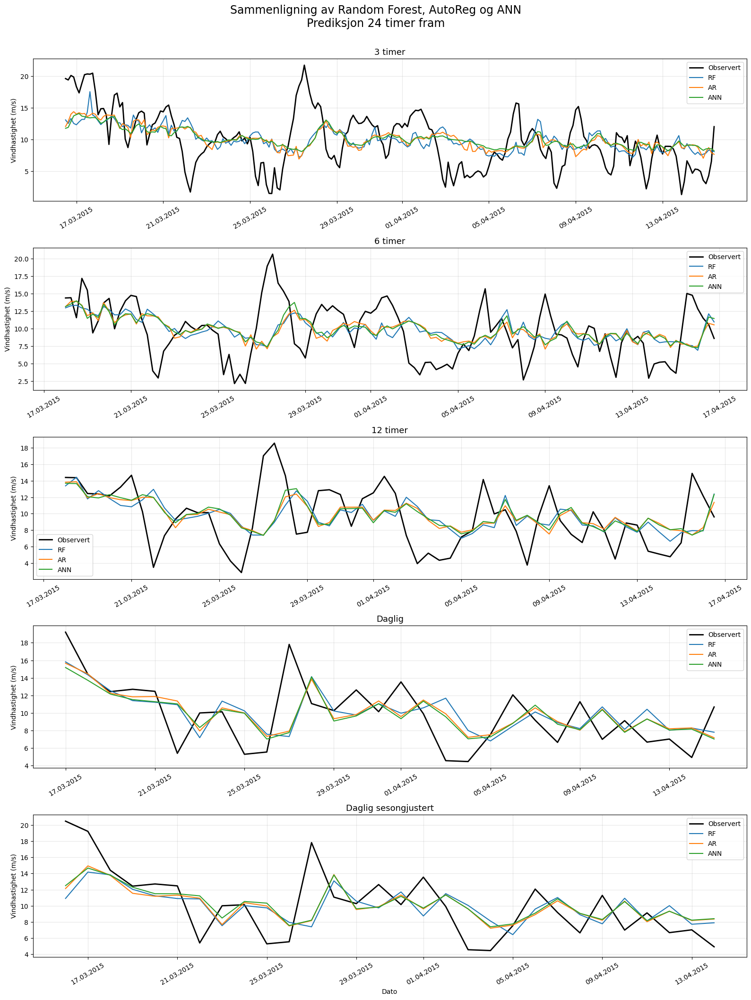

In [ ]:
import matplotlib.dates as mdates

farger = {
    "RF": "tab:blue",
    "AR": "tab:orange",
    "ANN": "tab:green"
}

fig, axes = plt.subplots(
    5, 1,
    figsize=(16, 21)
)

for ax, opplosning in zip(axes, opplosninger):

    df = samlede_prediksjoner[opplosning]

    if df.empty:
        ax.set_title(f"{opplosning} – ingen prediksjoner")
        continue

    start = df["datetime"].iloc[0]
    slutt = start + pd.Timedelta(days=30)

    df_plot = df.loc[
        (df["datetime"] >= start)
        & (df["datetime"] < slutt)
    ]

    ax.plot(
        df_plot["datetime"],
        df_plot["observed"],
        color="black",
        linewidth=2,
        label="Observert"
    )

    for modell in modeller:

        if modell in df_plot.columns:
            ax.plot(
                df_plot["datetime"],
                df_plot[modell],
                color=farger[modell],
                linewidth=1.5,
                label=modell
            )

    ax.set_title(opplosning, fontsize=13)
    ax.set_ylabel("Vindhastighet (m/s)")
    ax.legend()
    ax.grid(alpha=0.3)

    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%d.%m.%Y")
    )

    ax.tick_params(axis="x", rotation=30)

axes[-1].set_xlabel("Dato")

fig.suptitle(
    "Sammenligning av Random Forest, AutoReg og ANN\n"
    "Prediksjon 24 timer fram",
    fontsize=17,
    y=1.005
)

plt.tight_layout()

plt.savefig(
    "RF_AR_ANN_alle_tidsopplosninger.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "RF_AR_ANN_alle_tidsopplosninger.pdf",
    bbox_inches="tight"
)

plt.show()

Funnet: RF – 3 timer
Funnet: AR – 3 timer
Funnet: ANN – 3 timer
Funnet: Persistens – 3 timer
Funnet: Ukesgjennomsnitt – 3 timer
Funnet: RF – 6 timer
Funnet: AR – 6 timer
Funnet: ANN – 6 timer
Funnet: Persistens – 6 timer
Funnet: Ukesgjennomsnitt – 6 timer
Funnet: RF – 12 timer
Funnet: AR – 12 timer
Funnet: ANN – 12 timer
Funnet: Persistens – 12 timer
Funnet: Ukesgjennomsnitt – 12 timer
Funnet: RF – Daglig
Funnet: AR – Daglig
Funnet: ANN – Daglig
Funnet: Persistens – Daglig
Funnet: Ukesgjennomsnitt – Daglig
Funnet: RF – Daglig sesongjustert
Funnet: AR – Daglig sesongjustert
Funnet: ANN – Daglig sesongjustert
Funnet: Persistens – Daglig sesongjustert
Funnet: Ukesgjennomsnitt – Daglig sesongjustert
3 timer: 13996 felles observasjoner, modeller: ['RF', 'AR', 'ANN', 'Persistens', 'Ukesgjennomsnitt']
6 timer: 6965 felles observasjoner, modeller: ['RF', 'AR', 'ANN', 'Persistens', 'Ukesgjennomsnitt']
12 timer: 3483 felles observasjoner, modeller: ['RF', 'AR', 'ANN', 'Persistens', 'Ukesgjennoms

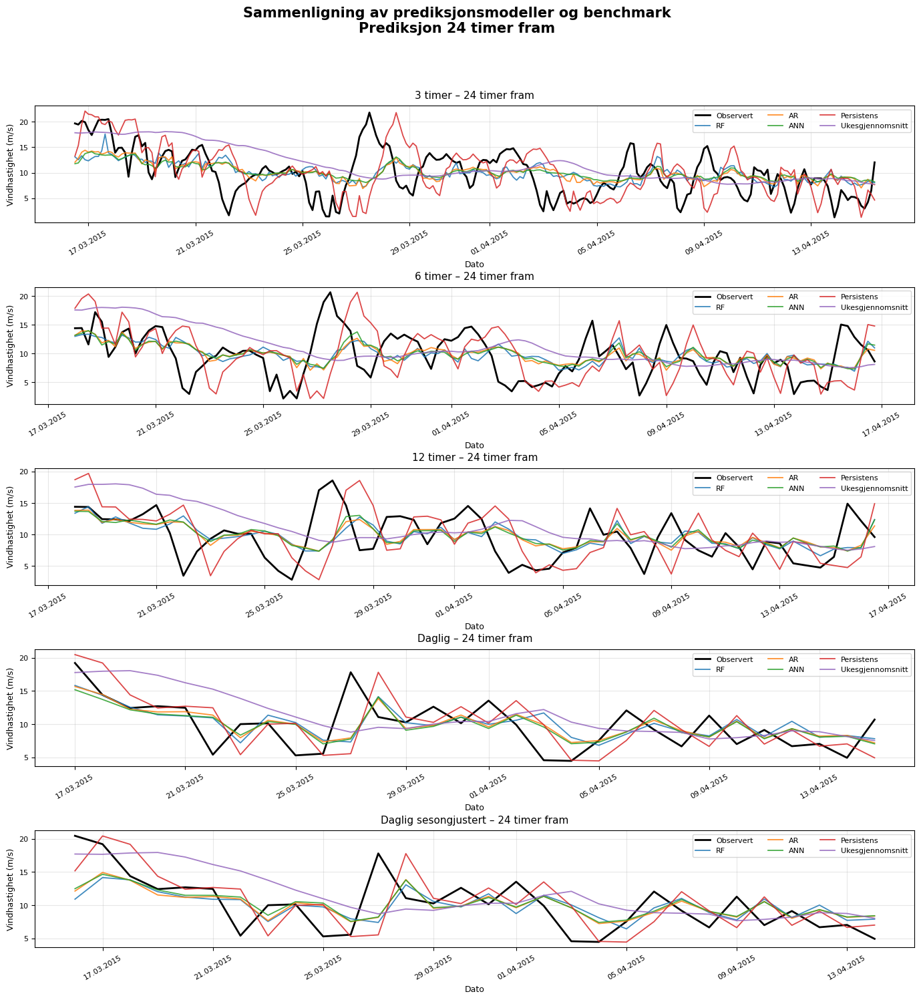

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ==========================================
# 1. Hjelpefunksjoner
# ==========================================

def finn_variabel(*navn):
    for n in navn:
        if n in globals():
            return globals()[n]
    return None


def lag_dataframe(datoer, observert, predikert, modell):

    if datoer is None or observert is None or predikert is None:
        return None

    datoer = pd.to_datetime(np.asarray(datoer).ravel())
    observert = np.asarray(observert).ravel()
    predikert = np.asarray(predikert).ravel()

    if not (
        len(datoer) == len(observert) == len(predikert)
    ):
        print(f"Ulik lengde på dataene for {modell}")
        return None

    return pd.DataFrame({
        "datetime": datoer,
        "observed": observert,
        modell: predikert
    })


# ==========================================
# 2. Hent RF, AutoReg og ANN
# ==========================================

def hent_prediksjoner(modell, opplosning):

    prefikser = {
        "RF": ["rf"],
        "AR": ["ar", "autoreg"],
        "ANN": ["ann"]
    }[modell]

    suffikser = {
        "3 timer": ["3h"],
        "6 timer": ["6h"],
        "12 timer": ["12h"],
        "Daglig": ["daily"],
        "Daglig sesongjustert": [
            "seasonal", "daily_seasonal",
            "seasonal_daily", "season"
        ]
    }[opplosning]

    for p in prefikser:
        for s in suffikser:

            datoer = finn_variabel(
                f"dates_test_{p}_{s}",
                f"test_dates_{p}_{s}",
                f"dates_{p}_{s}",
                f"dates_test_{s}_{p}"
            )

            observert = finn_variabel(
                f"y_test_{p}_{s}",
                f"y_test_{s}_{p}"
            )

            predikert = finn_variabel(
                f"y_pred_{p}_{s}",
                f"pred_{p}_{s}",
                f"y_pred_{s}_{p}",
                f"forecast_{p}_{s}"
            )

            if all(
                v is not None
                for v in [datoer, observert, predikert]
            ):
                return lag_dataframe(
                    datoer, observert, predikert, modell
                )

    return None


# ==========================================
# 3. Hent benchmarkmodellene
# ==========================================

def hent_benchmark(opplosning, modell):

    if opplosning not in benchmark_predictions:
        return None

    test = benchmark_predictions[opplosning].copy()

    kolonner = {
        "Persistens": "pred_persistence",
        "Ukesgjennomsnitt": "pred_mean"
    }

    pred_col = kolonner[modell]

    return lag_dataframe(
        test["target_datetime"],
        test["target"],
        test[pred_col],
        modell
    )


# ==========================================
# 4. Hent alle modellprediksjoner
# ==========================================

opplosninger = [
    "3 timer",
    "6 timer",
    "12 timer",
    "Daglig",
    "Daglig sesongjustert"
]

modeller = [
    "RF",
    "AR",
    "ANN",
    "Persistens",
    "Ukesgjennomsnitt"
]

prediksjoner_alle = {}

for opplosning in opplosninger:

    prediksjoner_alle[opplosning] = {}

    for modell in modeller:

        if modell in ["Persistens", "Ukesgjennomsnitt"]:
            df = hent_benchmark(opplosning, modell)
        else:
            df = hent_prediksjoner(modell, opplosning)

        if df is not None:
            prediksjoner_alle[opplosning][modell] = df
            print(f"Funnet: {modell} – {opplosning}")
        else:
            print(f"Mangler: {modell} – {opplosning}")


# ==========================================
# 5. Kombiner prediksjoner etter dato
# ==========================================

def kombiner_prediksjoner(modell_data):

    if not modell_data:
        return pd.DataFrame()

    samlet = None

    for modell, df in modell_data.items():

        temp = df[
            ["datetime", "observed", modell]
        ].copy()

        if samlet is None:
            samlet = temp
        else:
            samlet = pd.merge(
                samlet,
                temp[["datetime", modell]],
                on="datetime",
                how="inner"
            )

    return (
        samlet.sort_values("datetime")
        .reset_index(drop=True)
    )


samlede_prediksjoner = {}

for opplosning in opplosninger:

    df = kombiner_prediksjoner(
        prediksjoner_alle[opplosning]
    )

    samlede_prediksjoner[opplosning] = df

    print(
        f"{opplosning}: "
        f"{len(df)} felles observasjoner, "
        f"modeller: {list(prediksjoner_alle[opplosning])}"
    )


# ==========================================
# 6. Farger for modellene
# ==========================================

farger = {
    "RF": "tab:blue",
    "AR": "tab:orange",
    "ANN": "tab:green",
    "Persistens": "tab:red",
    "Ukesgjennomsnitt": "tab:purple"
}


# ==========================================
# 7. Lag samlet figur
# ==========================================

fig, axes = plt.subplots(
    5, 1,
    figsize=(14, 15)
)

for ax, opplosning in zip(axes, opplosninger):

    df = samlede_prediksjoner[opplosning]

    if df.empty:
        ax.set_title(f"{opplosning} – ingen felles prediksjoner")
        continue

    start = df["datetime"].iloc[0]
    slutt = start + pd.Timedelta(days=30)

    df_plot = df.loc[
        (df["datetime"] >= start)
        & (df["datetime"] < slutt)
    ]

    # Observert vindhastighet
    ax.plot(
        df_plot["datetime"],
        df_plot["observed"],
        color="black",
        linewidth=2,
        label="Observert"
    )

    # Alle fem modellene
    for modell in modeller:

        if modell in df_plot.columns:

            ax.plot(
                df_plot["datetime"],
                df_plot[modell],
                color=farger[modell],
                linewidth=1.3,
                alpha=0.85,
                label=modell
            )

    ax.set_title(
        f"{opplosning} – 24 timer fram",
        fontsize=11,
        pad=8
    )

    ax.set_ylabel(
        "Vindhastighet (m/s)",
        fontsize=9
    )

    ax.legend(
        fontsize=8,
        ncol=3,
        loc="upper right"
    )

    ax.grid(alpha=0.3)

    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%d.%m.%Y")
    )

    ax.tick_params(
        axis="x",
        rotation=30,
        labelsize=8
    )

    ax.tick_params(
        axis="y",
        labelsize=8
    )

    ax.set_xlabel("Dato", fontsize=9)


# ==========================================
# 8. Formatering
# ==========================================

fig.suptitle(
    "Sammenligning av prediksjonsmodeller og benchmark\n"
    "Prediksjon 24 timer fram",
    fontsize=15,
    fontweight="bold",
    y=0.995
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

fig.subplots_adjust(
    hspace=0.55
)


# ==========================================
# 9. Lagre figur
# ==========================================

plt.savefig(
    "Alle_modeller_med_benchmark.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Alle_modeller_med_benchmark.pdf",
    bbox_inches="tight"
)

plt.show()

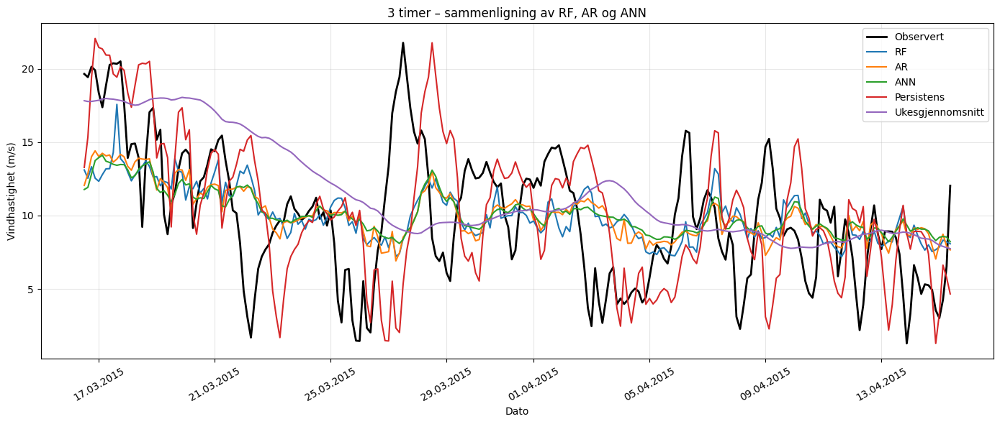

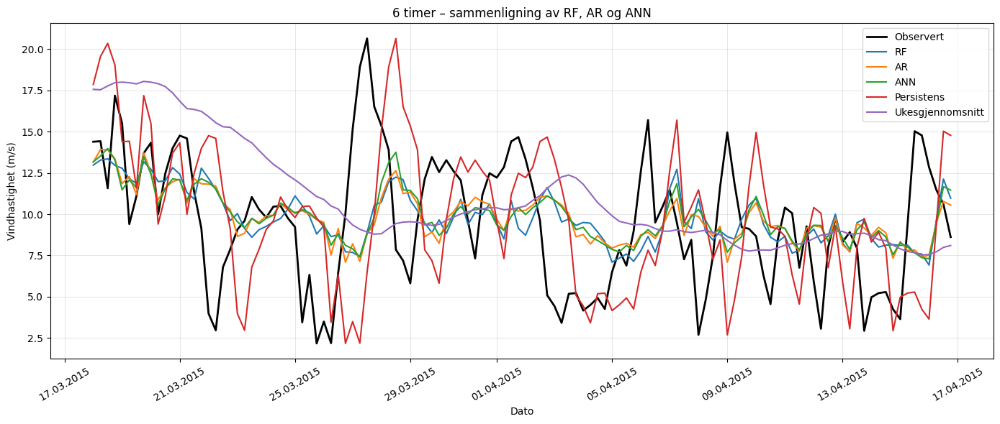

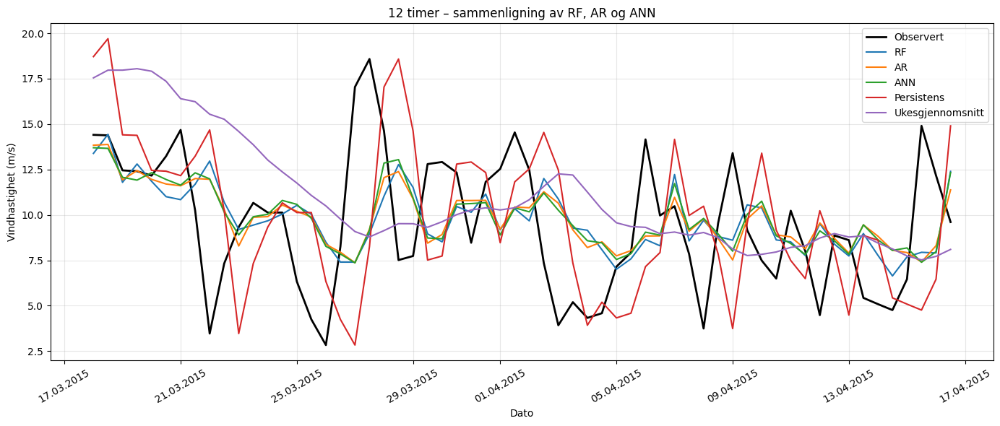

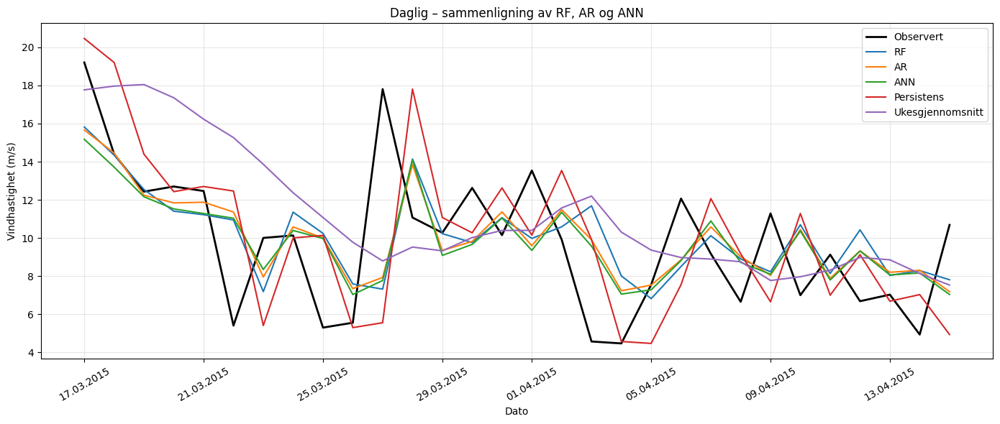

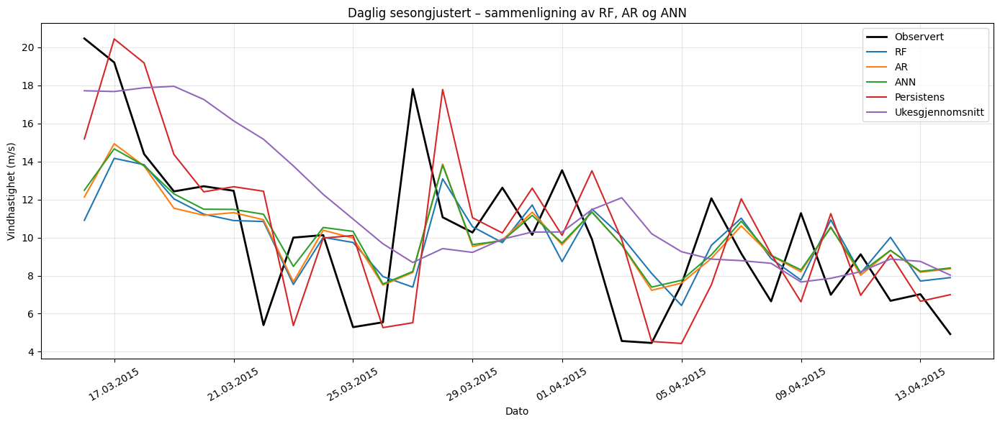

In [ ]:
for opplosning in opplosninger:

    df = samlede_prediksjoner[opplosning]

    if df.empty:
        continue

    start = df["datetime"].iloc[0]
    slutt = start + pd.Timedelta(days=30)

    df_plot = df.loc[
        (df["datetime"] >= start)
        & (df["datetime"] < slutt)
    ]

    fig, ax = plt.subplots(figsize=(14, 6))

    ax.plot(
        df_plot["datetime"],
        df_plot["observed"],
        color="black",
        linewidth=2,
        label="Observert"
    )

    for modell in modeller:
        if modell in df_plot.columns:
            ax.plot(
                df_plot["datetime"],
                df_plot[modell],
                color=farger[modell],
                linewidth=1.5,
                label=modell
            )

    ax.set_title(
        f"{opplosning} – sammenligning av RF, AR og ANN"
    )
    ax.set_xlabel("Dato")
    ax.set_ylabel("Vindhastighet (m/s)")
    ax.legend()
    ax.grid(alpha=0.3)

    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%d.%m.%Y")
    )

    plt.xticks(rotation=30)
    plt.tight_layout()

    filnavn = (
        opplosning.lower()
        .replace(" ", "_")
        .replace("ø", "o")
        .replace("å", "a")
    )

    plt.savefig(
        f"RF_AR_ANN_{filnavn}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.savefig(
        f"RF_AR_ANN_{filnavn}.pdf",
        bbox_inches="tight"
    )

    plt.show()

In [ ]:
for opplosning in opplosninger:

    funnet = list(prediksjoner_alle[opplosning].keys())
    mangler = [m for m in modeller if m not in funnet]

    print(f"\n{opplosning}")
    print("Funnet:", ", ".join(funnet) if funnet else "Ingen")

    if mangler:
        print("MANGLER:", ", ".join(mangler))
    else:
        print("Alle tre modeller er med!")


3 timer
Funnet: RF, AR, ANN, Persistens, Ukesgjennomsnitt
Alle tre modeller er med!

6 timer
Funnet: RF, AR, ANN, Persistens, Ukesgjennomsnitt
Alle tre modeller er med!

12 timer
Funnet: RF, AR, ANN, Persistens, Ukesgjennomsnitt
Alle tre modeller er med!

Daglig
Funnet: RF, AR, ANN, Persistens, Ukesgjennomsnitt
Alle tre modeller er med!

Daglig sesongjustert
Funnet: RF, AR, ANN, Persistens, Ukesgjennomsnitt
Alle tre modeller er med!


C:\Users\roy_l\AppData\Local\Temp\ipykernel_25296\1696669260.py:14: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  df_r2 = resultat_tabell.pivot_table(


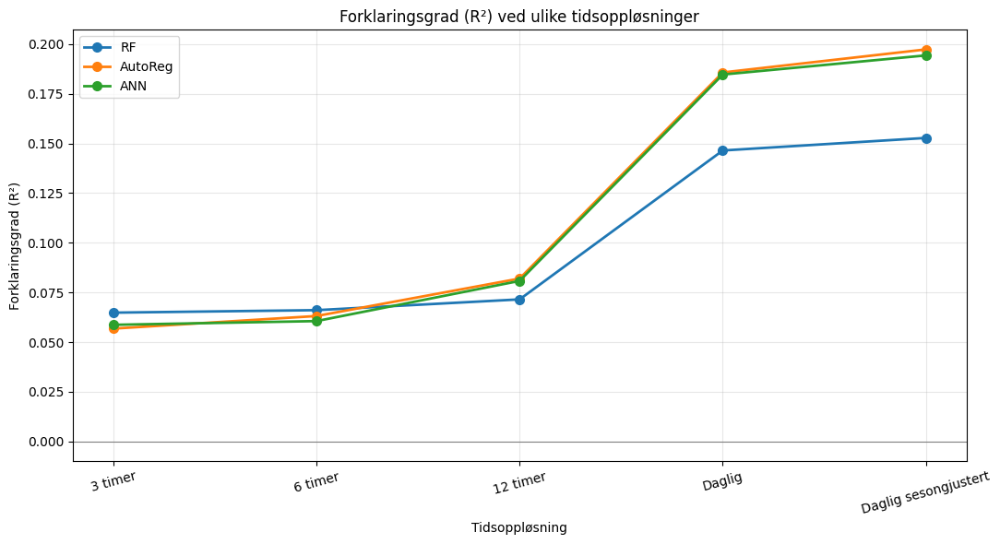

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Sørg for riktig rekkefølge
rekkefolge = [
    "3 timer",
    "6 timer",
    "12 timer",
    "Daglig",
    "Daglig sesongjustert"
]

# Bruk resultat_tabell fra tidligere
df_r2 = resultat_tabell.pivot_table(
    index="Tidsoppløsning",
    columns="Modell",
    values="R²",
    aggfunc="first"
)

df_r2 = df_r2.reindex(rekkefolge)

# Støtt både RF og Random Forest som modellnavn
df_r2 = df_r2.rename(
    columns={"Random Forest": "RF"}
)

farger = {
    "RF": "tab:blue",
    "AutoReg": "tab:orange",
    "ANN": "tab:green"
}

plt.figure(figsize=(11, 6))

for modell in ["RF", "AutoReg", "ANN"]:

    if modell in df_r2.columns:
        plt.plot(
            df_r2.index,
            df_r2[modell],
            marker="o",
            linewidth=2,
            markersize=7,
            label=modell,
            color=farger[modell]
        )

plt.xlabel("Tidsoppløsning")
plt.ylabel("Forklaringsgrad (R²)")

plt.title(
    "Forklaringsgrad (R²) ved ulike tidsoppløsninger"
)

plt.axhline(0, color="gray", linewidth=0.8)
plt.grid(alpha=0.3)
plt.legend()
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    "R2_alle_modeller.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "R2_alle_modeller.pdf",
    bbox_inches="tight"
)

plt.show()

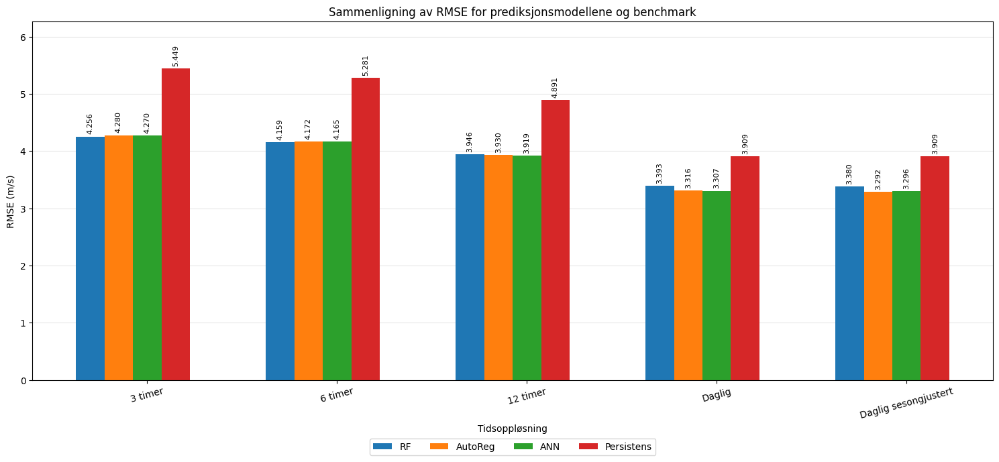

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. Klargjør RMSE-tabell
# ==========================================

rekkefolge = [
    "3 timer",
    "6 timer",
    "12 timer",
    "Daglig",
    "Daglig sesongjustert"
]

df_rmse = resultat_tabell.pivot_table(
    index="Tidsoppløsning",
    columns="Modell",
    values="RMSE",
    aggfunc="first",
    observed=True
)

df_rmse = df_rmse.reindex(rekkefolge)

df_rmse = df_rmse.rename(
    columns={
        "Random Forest": "RF",
        "Gjennomsnitt fra foregående uke": "Ukesgjennomsnitt"
    }
)

# ==========================================
# 2. Modeller og farger
# ==========================================

modeller = [
    "RF",
    "AutoReg",
    "ANN",
    "Persistens",
    "Ukesgjennomsnitt"
]

farger = {
    "RF": "tab:blue",
    "AutoReg": "tab:orange",
    "ANN": "tab:green",
    "Persistens": "tab:red",
    "Ukesgjennomsnitt": "tab:purple"
}

# ==========================================
# 3. Lag stolpediagram
# ==========================================

x = np.arange(len(rekkefolge))

bredde = 0.15

fig, ax = plt.subplots(figsize=(15, 7))

for i, modell in enumerate(modeller):

    if modell not in df_rmse.columns:
        continue

    verdier = df_rmse[modell].to_numpy(dtype=float)

    # Sentrer fem stolper rundt hver tidsoppløsning
    posisjon = x + (i - (len(modeller)-1)/2) * bredde

    stolper = ax.bar(
        posisjon,
        verdier,
        width=bredde,
        label=modell,
        color=farger[modell]
    )

    # Tall over stolpene
    for stolpe, verdi in zip(stolper, verdier):

        if np.isfinite(verdi):
            ax.text(
                stolpe.get_x() + stolpe.get_width() / 2,
                verdi + 0.04,
                f"{verdi:.3f}",
                ha="center",
                va="bottom",
                fontsize=8,
                rotation=90
            )

# ==========================================
# 4. Formatering
# ==========================================

ax.set_xticks(x)
ax.set_xticklabels(rekkefolge, rotation=15)

ax.set_xlabel("Tidsoppløsning")
ax.set_ylabel("RMSE (m/s)")

ax.set_title(
    "Sammenligning av RMSE for prediksjonsmodellene og benchmark"
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=5
)

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

# Litt ekstra plass til tallene
ax.set_ylim(
    0,
    np.nanmax(df_rmse.to_numpy(dtype=float)) * 1.15
)

plt.tight_layout()

# ==========================================
# 5. Lagre figuren
# ==========================================

plt.savefig(
    "RMSE_alle_modeller_benchmark.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "RMSE_alle_modeller_benchmark.pdf",
    bbox_inches="tight"
)

plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress, t as student_t

# Kopier datasettet
df_trend = df_daily.copy()

# Velg kolonnen med gjennomsnittlig vindhastighet
vindkolonne = "value"  # Endre til "daily_mean" om nødvendig

df_trend["datetime"] = pd.to_datetime(df_trend["datetime"])

df_trend = df_trend.sort_values("datetime").dropna(
    subset=["datetime", vindkolonne]
).copy()

# Tid målt i år siden første observasjon
df_trend["t_years"] = (
    (df_trend["datetime"] - df_trend["datetime"].min())
    .dt.total_seconds() / (365.2425 * 24 * 3600)
)

# Lineær regresjon
resultat = linregress(
    df_trend["t_years"],
    df_trend[vindkolonne]
)

a = resultat.slope
b = resultat.intercept
r2_trend = resultat.rvalue**2

# Predikerte verdier
df_trend["trend"] = a * df_trend["t_years"] + b

# 95 % konfidensintervall
frihetsgrader = len(df_trend) - 2
kritisk_t = student_t.ppf(0.975, frihetsgrader)

ci_lower = a - kritisk_t * resultat.stderr
ci_upper = a + kritisk_t * resultat.stderr

print("Lineær trend i gjennomsnittlig vindhastighet")
print("-------------------------------------------")
print(f"Stigningstall (a): {a:.6f} m/s per år")
print(f"Konstantledd (b):  {b:.4f}")
print(f"R²:                {r2_trend:.4f}")
print(f"95 % KI for a:     [{ci_lower:.6f}, {ci_upper:.6f}]")

print("\nHar stigningstallet positiv verdi?")
print("JA" if a > 0 else "NEI")

Lineær trend i gjennomsnittlig vindhastighet
-------------------------------------------
Stigningstall (a): -0.017198 m/s per år
Konstantledd (b):  9.6048
R²:                0.0009
95 % KI for a:     [-0.028928, -0.005467]

Har stigningstallet positiv verdi?
NEI


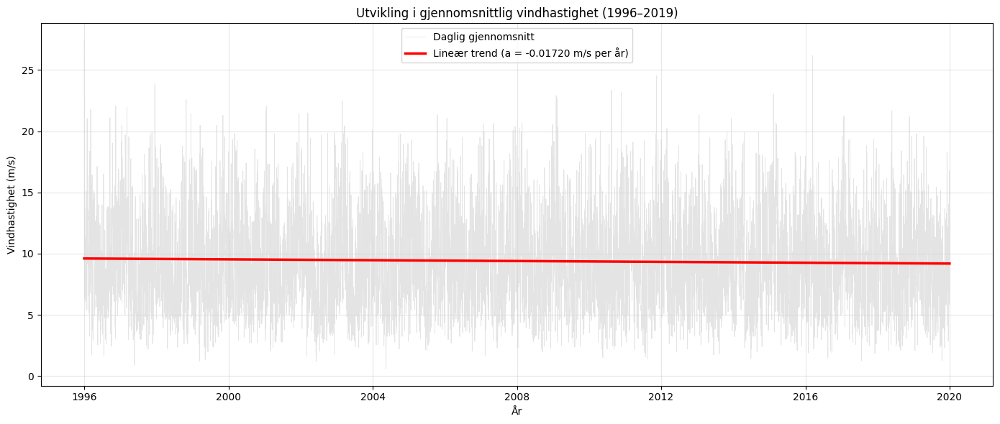

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    df_trend["datetime"],
    df_trend[vindkolonne],
    color="lightgray",
    linewidth=0.6,
    alpha=0.6,
    label="Daglig gjennomsnitt"
)

plt.plot(
    df_trend["datetime"],
    df_trend["trend"],
    color="red",
    linewidth=2.5,
    label=f"Lineær trend (a = {a:.5f} m/s per år)"
)

plt.xlabel("År")
plt.ylabel("Vindhastighet (m/s)")
plt.title("Utvikling i gjennomsnittlig vindhastighet (1996–2019)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("linear_trend_windspeed.png", dpi=300)
plt.show()

Trend i årlig gjennomsnittlig vindhastighet
------------------------------------------
Stigningstall: -0.016519 m/s per år
R²:           0.1861
p-verdi:      0.035299
Positiv trend: False


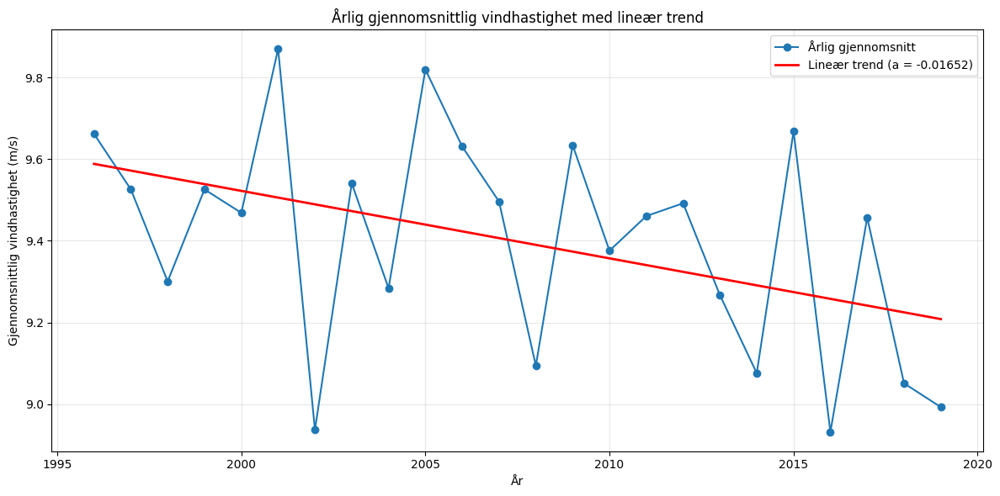

In [ ]:
# Beregn årlig gjennomsnitt
df_yearly = (
    df_trend.assign(year=df_trend["datetime"].dt.year)
    .groupby("year", as_index=False)[vindkolonne]
    .mean()
)

# Lineær regresjon på årsgjennomsnitt
resultat_yearly = linregress(
    df_yearly["year"],
    df_yearly[vindkolonne]
)

a_yearly = resultat_yearly.slope
b_yearly = resultat_yearly.intercept

df_yearly["trend"] = (
    a_yearly * df_yearly["year"] + b_yearly
)

print("Trend i årlig gjennomsnittlig vindhastighet")
print("------------------------------------------")
print(f"Stigningstall: {a_yearly:.6f} m/s per år")
print(f"R²:           {resultat_yearly.rvalue**2:.4f}")
print(f"p-verdi:      {resultat_yearly.pvalue:.6f}")
print(f"Positiv trend: {a_yearly > 0}")

plt.figure(figsize=(12, 6))

plt.plot(
    df_yearly["year"],
    df_yearly[vindkolonne],
    marker="o",
    linewidth=1.5,
    label="Årlig gjennomsnitt"
)

plt.plot(
    df_yearly["year"],
    df_yearly["trend"],
    color="red",
    linewidth=2,
    label=f"Lineær trend (a = {a_yearly:.5f})"
)

plt.xlabel("År")
plt.ylabel("Gjennomsnittlig vindhastighet (m/s)")
plt.title("Årlig gjennomsnittlig vindhastighet med lineær trend")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
print("Treningsperiode:")
print(df_rf_3h.loc[X_train_rf_3h.index, "datetime"].min())
print(df_rf_3h.loc[X_train_rf_3h.index, "datetime"].max())

print("\nTestperiode:")
print(df_rf_3h.loc[X_test_rf_3h.index, "datetime"].min())
print(df_rf_3h.loc[X_test_rf_3h.index, "datetime"].max())


Treningsperiode:
1996-01-07 21:00:00
2015-03-15 09:00:00

Testperiode:
2015-03-15 12:00:00
2019-12-30 21:00:00


In [ ]:
print("Treningsperiode:")
print(df_rf_daily.loc[X_train_rf_daily.index, "datetime"].min())
print(df_rf_daily.loc[X_train_rf_daily.index, "datetime"].max())

print("\nTestperiode:")
print(df_rf_daily.loc[X_test_rf_daily.index, "datetime"].min())
print(df_rf_daily.loc[X_test_rf_daily.index, "datetime"].max())


Treningsperiode:
1996-01-07 00:00:00
2015-03-14 00:00:00

Testperiode:
2015-03-15 00:00:00
2019-12-30 00:00:00


In [ ]:


df_compare = df_daily.copy()

vindkolonne = "value"  # Endre til "daily_mean" ved behov

df_compare["datetime"] = pd.to_datetime(df_compare["datetime"])

if "locID" in df_compare.columns:
    df_compare = df_compare[df_compare["locID"] == 1]

df_compare = df_compare.dropna(
    subset=["datetime", vindkolonne]
).sort_values("datetime")

# Bruk modellens faktiske splittdato dersom den er kjent
split_date = pd.Timestamp("2015-03-15")

train = df_compare.loc[
    (df_compare["datetime"] >= "1996-01-07") &
    (df_compare["datetime"] < split_date),
    vindkolonne
]

test = df_compare.loc[
    (df_compare["datetime"] >= split_date) &
    (df_compare["datetime"] <= "2019-12-30"),
    vindkolonne
]

resultater = pd.DataFrame({
    "Treningsdata": [
        train.mean(),
        train.std(),
        train.median(),
        train.quantile(0.95)
    ],
    "Testdata": [
        test.mean(),
        test.std(),
        test.median(),
        test.quantile(0.95)
    ]
}, index=[
    "Gjennomsnitt",
    "Standardavvik",
    "Median",
    "95-persentil"
])

display(resultater.round(4))

print("Forskjell i gjennomsnitt:",
      round(test.mean() - train.mean(), 4), "m/s")

ks = ks_2samp(train, test)

print("KS-statistikk:", round(ks.statistic, 4))
print("KS p-verdi:", round(ks.pvalue, 6))

,Treningsdata,Testdata
Gjennomsnitt,9.4703,9.0900
Standardavvik,3.9206,3.6761
Median,9.0597,8.8333
95-persentil,16.6777,15.5956


Forskjell i gjennomsnitt: -0.3803 m/s
KS-statistikk: 0.0468
KS p-verdi: 0.004196


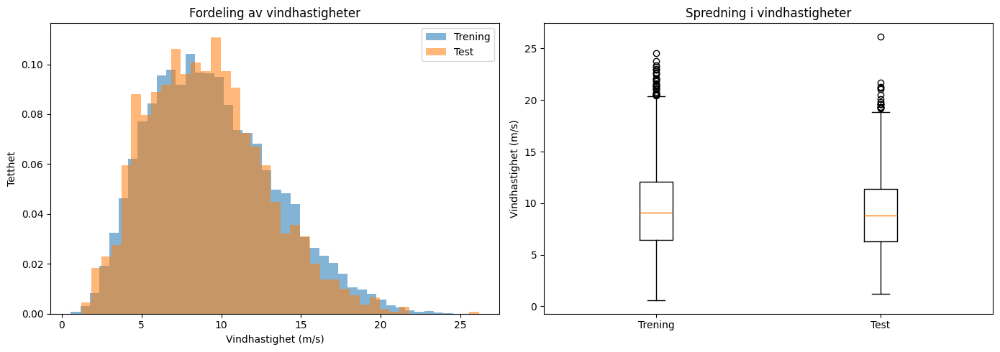

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(
    train, bins=40, density=True,
    alpha=0.55, label="Trening"
)

axes[0].hist(
    test, bins=40, density=True,
    alpha=0.55, label="Test"
)

axes[0].set_xlabel("Vindhastighet (m/s)")
axes[0].set_ylabel("Tetthet")
axes[0].set_title("Fordeling av vindhastigheter")
axes[0].legend()

# Boksplott
axes[1].boxplot(
    [train, test],
    tick_labels=["Trening", "Test"]
)

axes[1].set_ylabel("Vindhastighet (m/s)")
axes[1].set_title("Spredning i vindhastigheter")

plt.tight_layout()
plt.show()

### sammenligning av trening og testdata

In [ ]:


# ==========================================
# 1. Datasett og parametere
# ==========================================

datasett = {
    "3 timer": (df_3h, 56, 8),
    "6 timer": (df_6h, 28, 4),
    "12 timer": (df_12h, 14, 2),
    "Daglig": (df_daily, 7, 1)
}

train_test_data = {}
statistikk = []

# ==========================================
# 2. Lag samme datasplitt som modellene
# ==========================================

for opplosning, (df, n_lags, forecast_steps) in datasett.items():

    data = df[["datetime", "value"]].copy()

    data["datetime"] = pd.to_datetime(data["datetime"])

    data = (
        data.sort_values("datetime")
        .reset_index(drop=True)
    )

    # Lag historiske observasjoner
    for i in range(n_lags):
        data[f"lag_{i}"] = data["value"].shift(i)

    lag_cols = [f"lag_{i}" for i in range(n_lags)]

    # Målvariabel 24 timer fram
    data["target"] = data["value"].shift(-forecast_steps)

    data["target_datetime"] = (
        data["datetime"].shift(-forecast_steps)
    )

    data = data.dropna(
        subset=lag_cols + ["target", "target_datetime"]
    ).reset_index(drop=True)

    # Kronologisk 80/20-splitt
    split = int(len(data) * 0.8)

    train = data.iloc[:split].copy()
    test = data.iloc[split:].copy()

    train_test_data[opplosning] = {
        "train": train,
        "test": test
    }

    # Statistikk for målvariabelen
    for navn, subset in [
        ("Trening", train),
        ("Test", test)
    ]:

        statistikk.append({
            "Tidsoppløsning": opplosning,
            "Datasett": navn,
            "Antall": len(subset),
            "Gjennomsnitt": subset["target"].mean(),
            "Standardavvik": subset["target"].std(),
            "Median": subset["target"].median(),
            "Minimum": subset["target"].min(),
            "Maksimum": subset["target"].max()
        })

statistikk_tabell = pd.DataFrame(statistikk)

display(statistikk_tabell.round(4))

,Tidsoppløsning,Datasett,Antall,Gjennomsnitt,Standardavvik,Median,Minimum,Maksimum
0,3 timer,Trening,56013,9.4728,4.6427,9.0324,0.2418,35.5630
1,3 timer,Test,14004,9.0841,4.4017,8.7760,0.1341,29.9533
2,6 timer,Trening,28007,9.4727,4.5429,9.0385,0.2757,34.5938
3,6 timer,Test,7002,9.0841,4.3044,8.7624,0.3386,29.7069
4,12 timer,Trening,14004,9.4725,4.3291,9.0188,0.5298,29.7499
5,12 timer,Test,3501,9.0841,4.0960,8.7269,0.4575,28.3386
6,Daglig,Trening,7002,9.4716,3.9210,9.0615,0.5651,24.5290
7,Daglig,Test,1751,9.0875,3.6734,8.8333,1.2435,26.1614


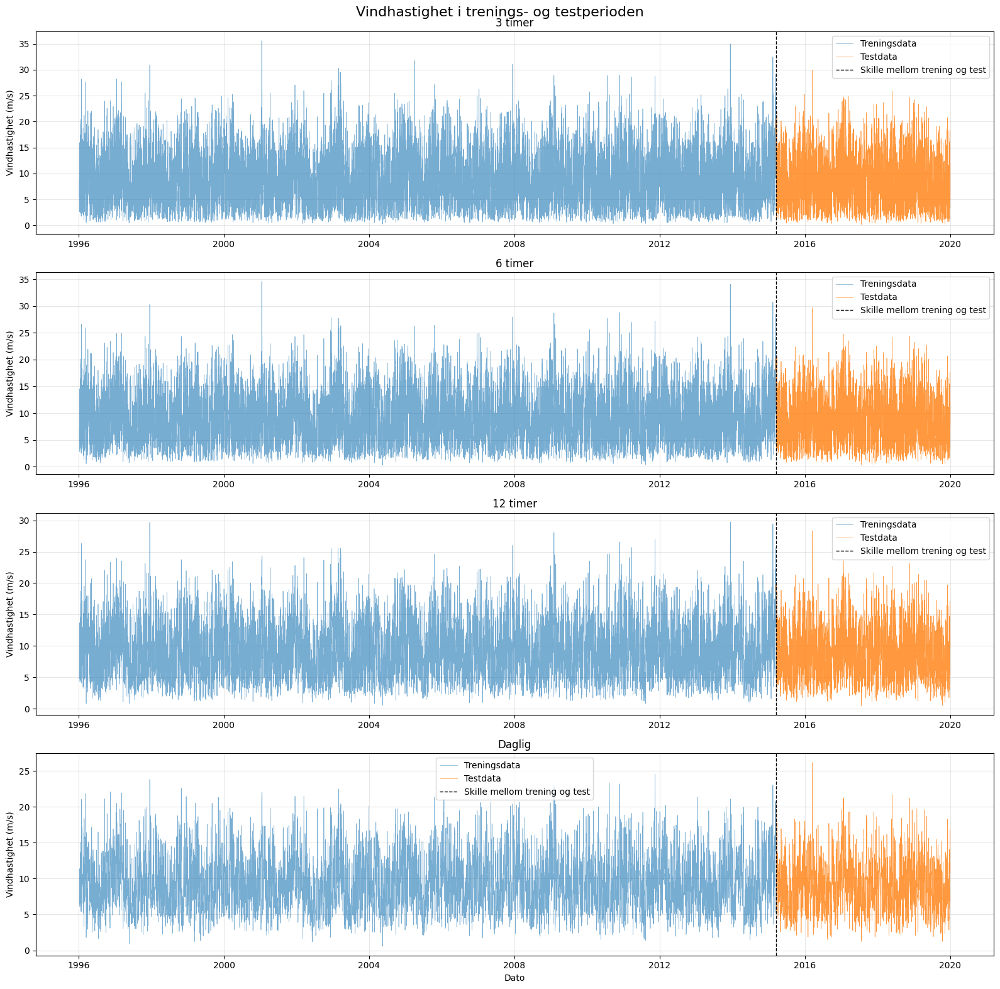

In [ ]:
fig, axes = plt.subplots(
    4, 1,
    figsize=(16, 16)
)

for ax, (opplosning, datasett) in zip(
    axes,
    train_test_data.items()
):

    train = datasett["train"]
    test = datasett["test"]

    ax.plot(
        train["target_datetime"],
        train["target"],
        color="tab:blue",
        linewidth=0.5,
        alpha=0.6,
        label="Treningsdata"
    )

    ax.plot(
        test["target_datetime"],
        test["target"],
        color="tab:orange",
        linewidth=0.5,
        alpha=0.8,
        label="Testdata"
    )

    ax.axvline(
        test["target_datetime"].iloc[0],
        color="black",
        linestyle="--",
        linewidth=1,
        label="Skille mellom trening og test"
    )

    ax.set_title(opplosning)
    ax.set_ylabel("Vindhastighet (m/s)")
    ax.legend()
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Dato")

plt.suptitle(
    "Vindhastighet i trenings- og testperioden",
    fontsize=16
)

plt.tight_layout()
plt.show()

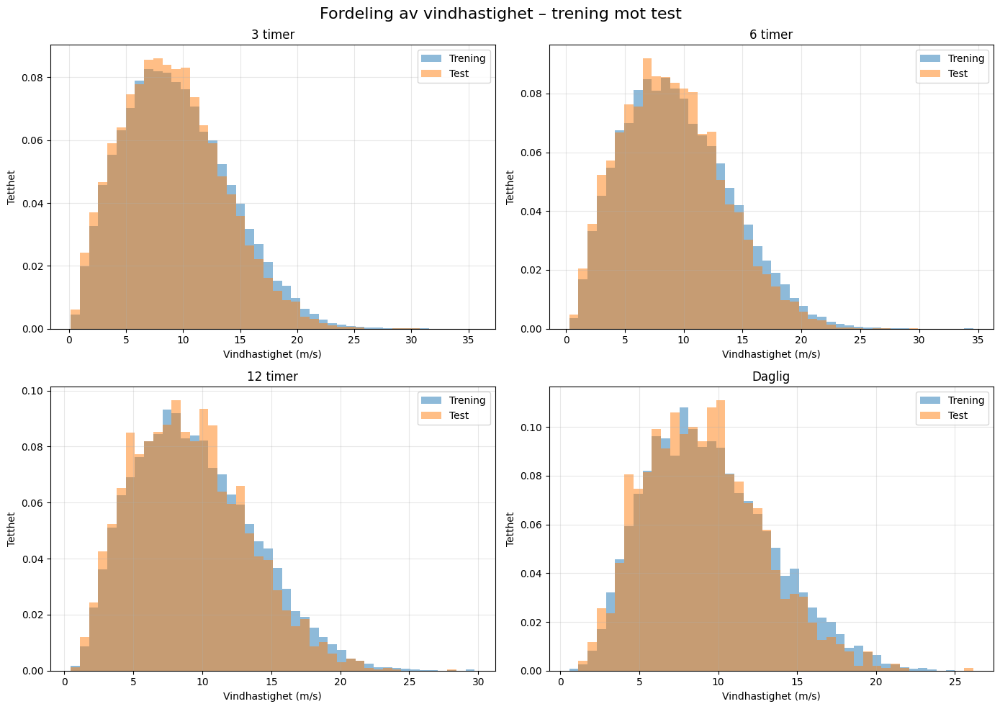

In [ ]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

axes = axes.flatten()

for ax, (opplosning, datasett) in zip(
    axes,
    train_test_data.items()
):

    train = datasett["train"]["target"]
    test = datasett["test"]["target"]

    bins = np.linspace(
        min(train.min(), test.min()),
        max(train.max(), test.max()),
        45
    )

    ax.hist(
        train,
        bins=bins,
        density=True,
        alpha=0.5,
        label="Trening",
        color="tab:blue"
    )

    ax.hist(
        test,
        bins=bins,
        density=True,
        alpha=0.5,
        label="Test",
        color="tab:orange"
    )

    ax.set_title(opplosning)
    ax.set_xlabel("Vindhastighet (m/s)")
    ax.set_ylabel("Tetthet")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle(
    "Fordeling av vindhastighet – trening mot test",
    fontsize=16
)

plt.tight_layout()
plt.show()

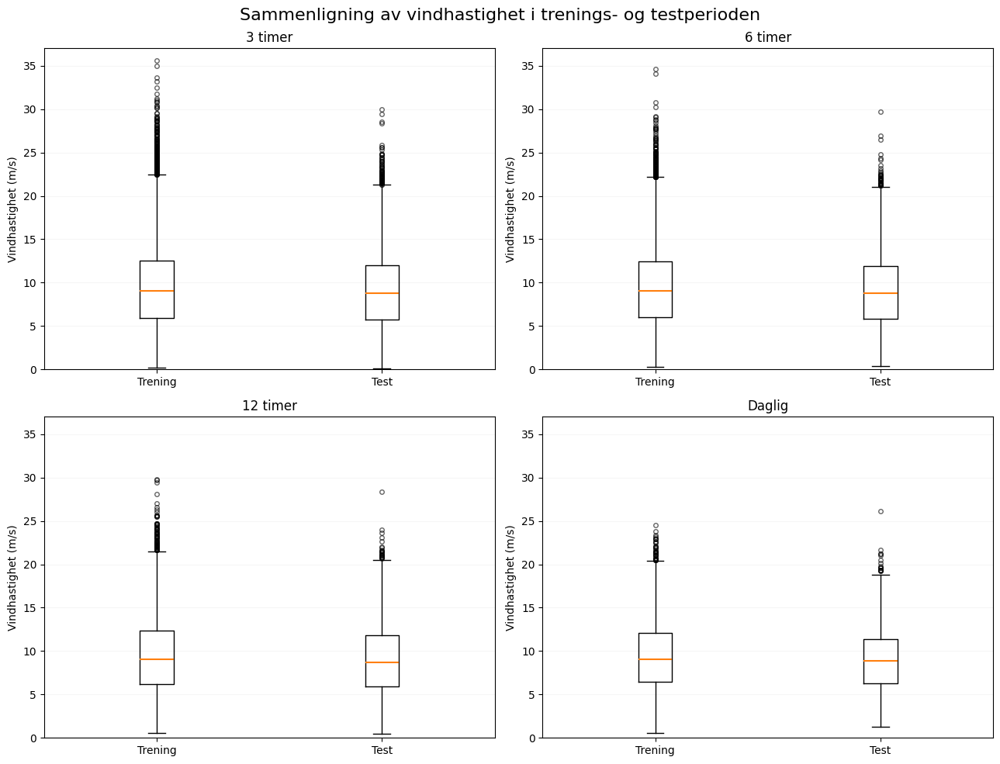

In [ ]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 10)
)

axes = axes.flatten()

for ax, (opplosning, datasett) in zip(
    axes,
    train_test_data.items()
):

    train = datasett["train"]["target"]
    test = datasett["test"]["target"]

    ax.boxplot(
        [train, test],
        tick_labels=["Trening", "Test"],
        showfliers=True,
        flierprops=dict(
            marker="o",
            markerfacecolor="none",
            markeredgecolor="black",
            markersize=4,
            linestyle="none",
            alpha=0.6
        ),
        medianprops=dict(
            color="tab:orange",
            linewidth=1.5
        )
    )

    ax.set_title(opplosning)
    ax.set_ylabel("Vindhastighet (m/s)")

    # Lik skala for alle diagrammene
    ax.set_ylim(0, 37)
    ax.set_yticks(np.arange(0, 38, 5))

    ax.grid(axis="y", alpha=0.1)

plt.suptitle(
    "Sammenligning av vindhastighet i trenings- og testperioden",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "boxplot_train_test_extremverdier.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "boxplot_train_test_extremverdier.pdf",
    bbox_inches="tight"
)

plt.show()

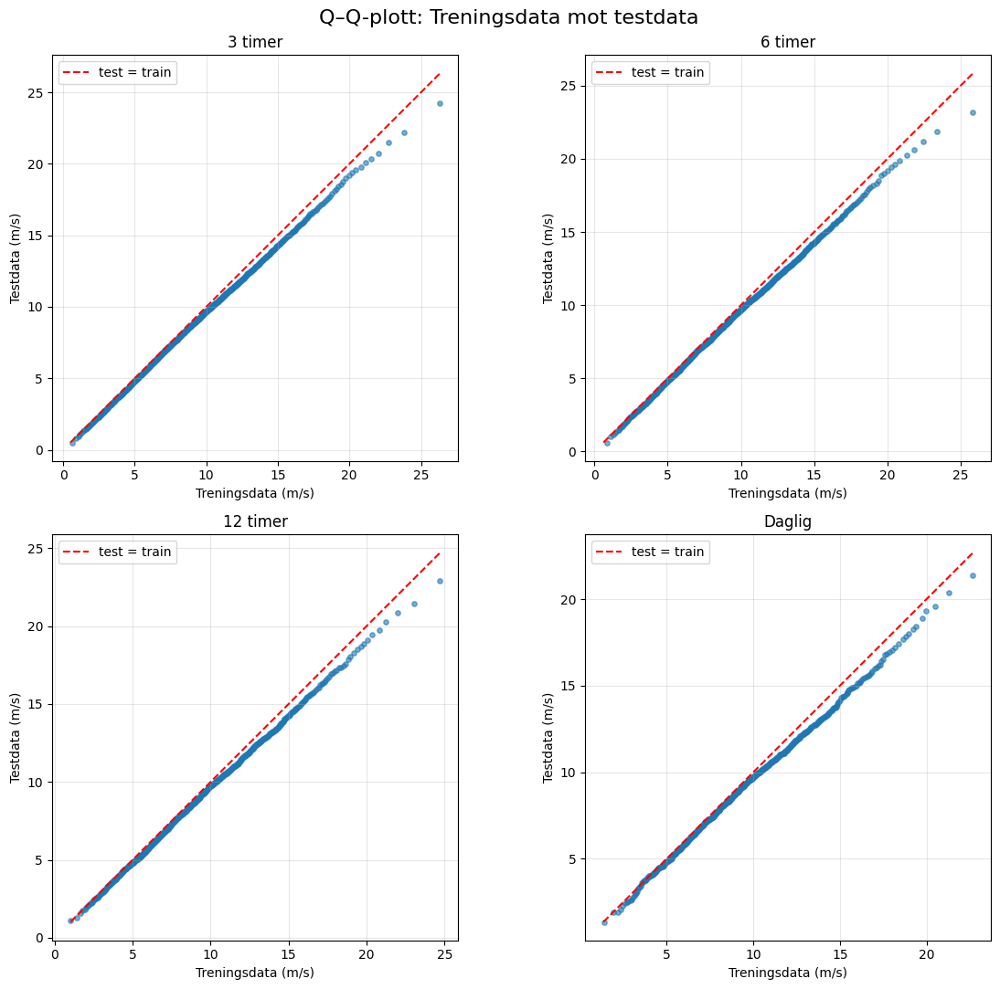

In [ ]:


fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 11)
)

axes = axes.flatten()

for ax, (opplosning, datasett) in zip(
    axes,
    train_test_data.items()
):

    train = datasett["train"]["target"].dropna().to_numpy()
    test = datasett["test"]["target"].dropna().to_numpy()

    # Sammenlign de samme kvantilene
    quantiles = np.linspace(0.001, 0.999, 500)

    x = np.quantile(train, quantiles)
    y = np.quantile(test, quantiles)

    # Punkter
    ax.scatter(
        x,
        y,
        alpha=0.6,
        s=15,
        color="tab:blue"
    )

    # Referanselinje y = x
    minimum = min(x.min(), y.min())
    maksimum = max(x.max(), y.max())

    ax.plot(
        [minimum, maksimum],
        [minimum, maksimum],
        color="red",
        linestyle="--",
        linewidth=1.5,
        label="test = train"
    )

    ax.set_title(opplosning)
    ax.set_xlabel("Treningsdata (m/s)")
    ax.set_ylabel("Testdata (m/s)")

    ax.set_aspect("equal", adjustable="box")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle(
    "Q–Q-plott: Treningsdata mot testdata",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "QQ_train_test.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "QQ_train_test.pdf",
    bbox_inches="tight"
)

plt.show()

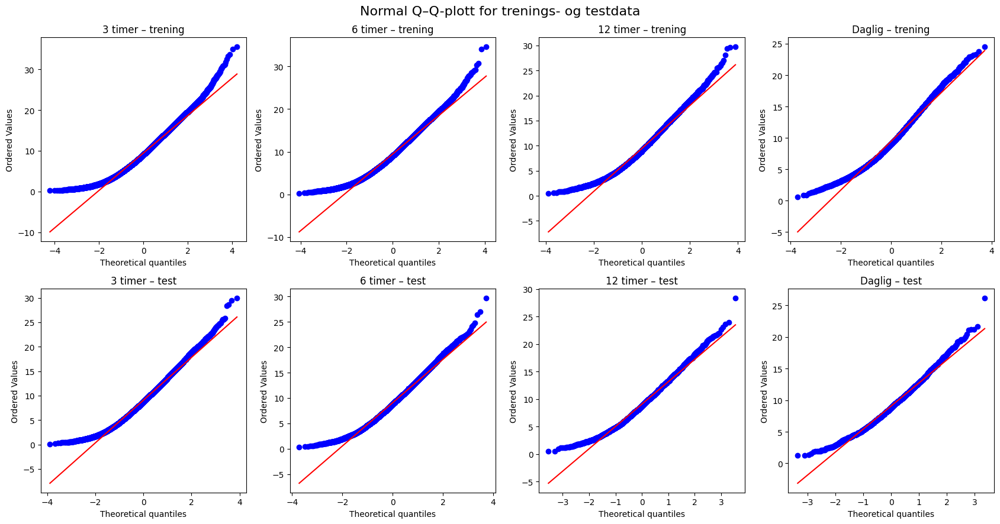

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

fig, axes = plt.subplots(
    2, 4,
    figsize=(17, 9)
)

for i, (opplosning, datasett) in enumerate(
    train_test_data.items()
):

    if i >= 4:
        break

    train = datasett["train"]["target"].dropna()
    test = datasett["test"]["target"].dropna()

    # Treningsdata
    stats.probplot(
        train,
        dist="norm",
        plot=axes[0, i]
    )

    axes[0, i].set_title(
        f"{opplosning} – trening"
    )

    # Testdata
    stats.probplot(
        test,
        dist="norm",
        plot=axes[1, i]
    )

    axes[1, i].set_title(
        f"{opplosning} – test"
    )

plt.suptitle(
    "Normal Q–Q-plott for trenings- og testdata",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import jarque_bera, skew, kurtosis
import pandas as pd

normality_results = []

for opplosning, datasett in train_test_data.items():

    for periode in ["train", "test"]:

        values = (
            datasett[periode]["target"]
            .dropna()
            .to_numpy()
        )

        jb_stat, p_value = jarque_bera(values)

        normality_results.append({
            "Tidsoppløsning": opplosning,
            "Periode": "Trening" if periode == "train" else "Test",
            "Antall": len(values),
            "Skjevhet": skew(values),
            "Kurtose": kurtosis(values),
            "JB-statistikk": jb_stat,
            "p-verdi": p_value,
            "Forkast H0 (5 %)": p_value < 0.05
        })

normality_df = pd.DataFrame(normality_results)

display(normality_df.round(4))

,Tidsoppløsning,Periode,Antall,Skjevhet,Kurtose,JB-statistikk,p-verdi,Forkast H0 (5 %)
0,3 timer,Trening,56013,0.4975,-0.0083,2310.4757,0.0,True
1,3 timer,Test,14004,0.4401,-0.1008,458.0142,0.0,True
2,6 timer,Trening,28007,0.5030,-0.0322,1182.2566,0.0,True
3,6 timer,Test,7002,0.4430,-0.1223,233.4008,0.0,True
4,12 timer,Trening,14004,0.5184,-0.0439,628.3676,0.0,True
5,12 timer,Test,3501,0.4706,-0.0884,130.3747,0.0,True
6,Daglig,Trening,7002,0.5094,-0.1373,308.3510,0.0,True
7,Daglig,Test,1751,0.5001,0.1141,73.9375,0.0,True


### fordelingen til prediksjonsfeilene for Random Forest, AutoReg og ANN

In [ ]:
for name in [
    "predictions_all",
    "results_df",
    "benchmark_predictions",
    "benchmark_table",
    "trained_models"
]:
    print(f"{name}: {name in globals()}")

predictions_all: True
results_df: True
benchmark_predictions: True
benchmark_table: True
trained_models: True


In [ ]:


models = [
    "Random Forest",
    "AutoReg",
    "ANN",
    "Persistens",
    "Historisk gjennomsnitt"
]

residuals_all = {}

for resolution, df in predictions_all.items():

    residual_df = pd.DataFrame({
        "datetime": pd.to_datetime(df["datetime"])
    })

    for model in models:

        if model in df.columns:

            residual_df[model] = (
                df["Observert"] - df[model]
            )

    residuals_all[resolution] = residual_df

display(residuals_all)

{'3 timer':                  datetime  Random Forest   AutoReg       ANN
 0     2015-03-16 00:00:00       3.809971  8.053382  7.270946
 1     2015-03-16 03:00:00       3.579235  8.730911  7.509877
 2     2015-03-16 06:00:00       3.870402  8.567101  7.326500
 3     2015-03-16 09:00:00       3.340881  7.793256  7.148739
 4     2015-03-16 12:00:00       1.936877  6.034975  5.471674
 ...                   ...            ...       ...       ...
 13940 2019-12-31 09:00:00      -3.946318 -4.064336 -3.412553
 13941 2019-12-31 12:00:00      -5.069470 -6.442056 -4.982429
 13942 2019-12-31 15:00:00      -0.576916 -1.924905 -0.192618
 13943 2019-12-31 18:00:00       1.134648  0.528269  2.251529
 13944 2019-12-31 21:00:00       2.830118 -0.024638  1.996257
 
 [13945 rows x 4 columns],
 '6 timer':                 datetime  Random Forest   AutoReg       ANN
 0    2015-03-16 00:00:00       5.372965  7.804352  7.086277
 1    2015-03-16 06:00:00       4.814988  8.207320  7.761407
 2    2015-03-16 12:00

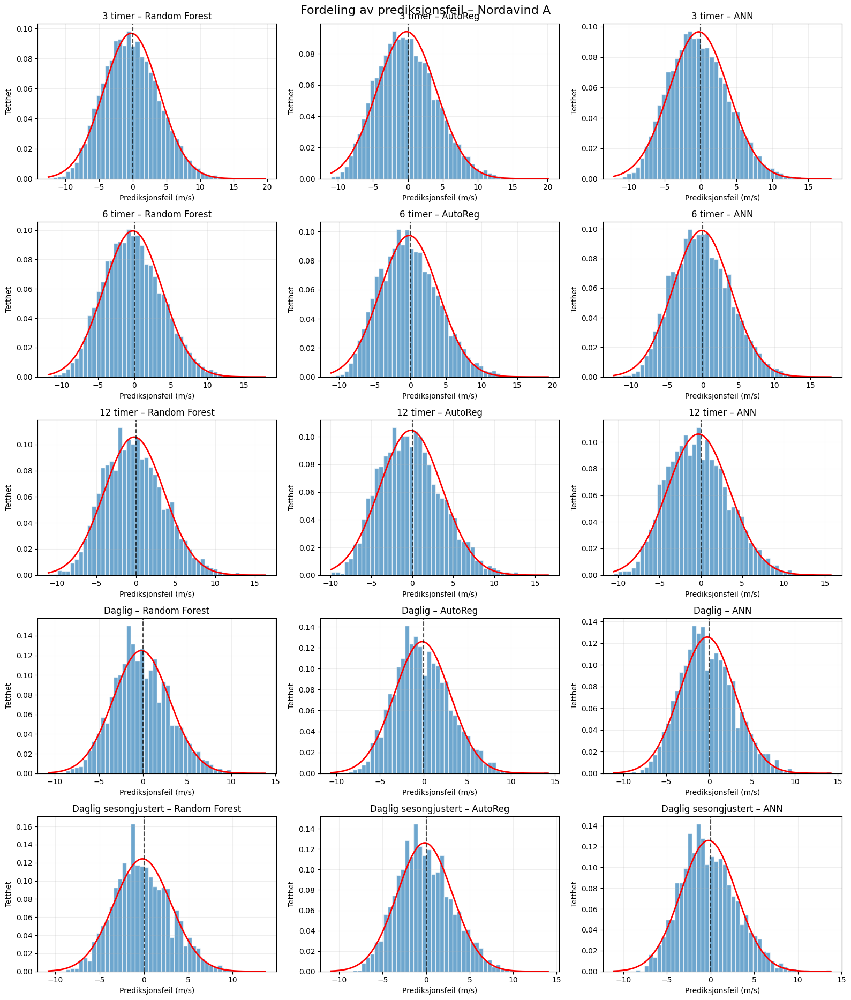

In [ ]:
fig, axes = plt.subplots(
    len(predictions_all),
    3,
    figsize=(16, 19)
)

for i, (resolution, df) in enumerate(
    residuals_all.items()
):

    for j, model in enumerate(
        ["Random Forest", "AutoReg", "ANN"]
    ):

        ax = axes[i, j]

        errors = df[model].dropna().to_numpy()

        ax.hist(
            errors,
            bins=50,
            density=True,
            alpha=0.65,
            edgecolor="white"
        )

        mu = np.mean(errors)
        sigma = np.std(errors, ddof=1)

        x = np.linspace(
            errors.min(),
            errors.max(),
            300
        )

        ax.plot(
            x,
            stats.norm.pdf(x, mu, sigma),
            color="red",
            linewidth=2,
            label="Normalfordeling"
        )

        ax.axvline(
            0,
            color="black",
            linestyle="--",
            alpha=0.7
        )

        ax.set_title(f"{resolution} – {model}")
        ax.set_xlabel("Prediksjonsfeil (m/s)")
        ax.set_ylabel("Tetthet")
        ax.grid(alpha=0.2)

plt.suptitle(
    "Fordeling av prediksjonsfeil – Nordavind A",
    fontsize=16
)

plt.tight_layout()
plt.show()

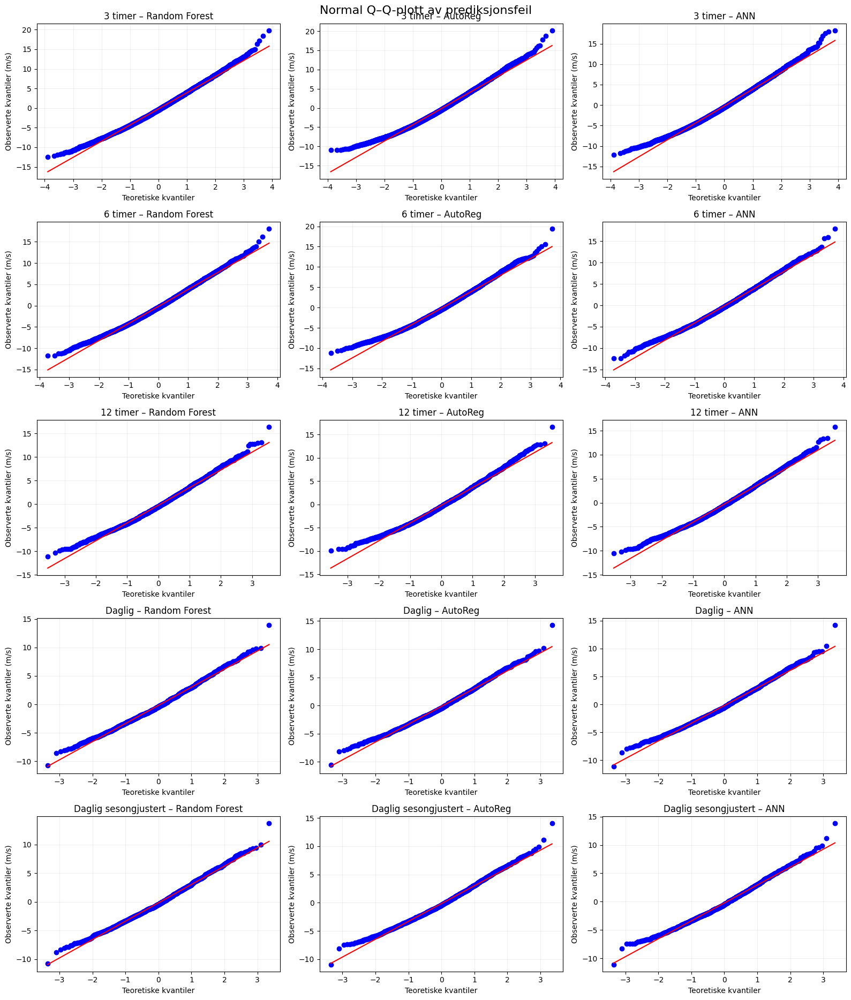

In [ ]:
fig, axes = plt.subplots(
    len(residuals_all),
    3,
    figsize=(16, 19)
)

for i, (resolution, df) in enumerate(
    residuals_all.items()
):

    for j, model in enumerate(
        ["Random Forest", "AutoReg", "ANN"]
    ):

        ax = axes[i, j]

        errors = df[model].dropna().to_numpy()

        stats.probplot(
            errors,
            dist="norm",
            plot=ax
        )

        ax.set_title(f"{resolution} – {model}")
        ax.set_xlabel("Teoretiske kvantiler")
        ax.set_ylabel("Observerte kvantiler (m/s)")
        ax.grid(alpha=0.2)

plt.suptitle(
    "Normal Q–Q-plott av prediksjonsfeil",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
normality_results = []

for resolution, df in residuals_all.items():

    for model in models:

        if model not in df.columns:
            continue

        errors = df[model].dropna().to_numpy()

        jb = stats.jarque_bera(errors)

        normality_results.append({
            "Tidsoppløsning": resolution,
            "Modell": model,
            "Gjennomsnittlig feil": np.mean(errors),
            "Standardavvik": np.std(errors, ddof=1),
            "Skjevhet": stats.skew(errors),
            "Kurtose": stats.kurtosis(errors),
            "JB-statistikk": jb.statistic,
            "p-verdi": jb.pvalue,
            "Forkast H0 (5 %)": jb.pvalue < 0.05
        })

normality_df = pd.DataFrame(normality_results)

display(normality_df.round(4))

,Tidsoppløsning,Modell,Gjennomsnittlig feil,Standardavvik,Skjevhet,Kurtose,JB-statistikk,p-verdi,Forkast H0 (5 %)
0,3 timer,Random Forest,-0.2221,4.1233,0.2723,-0.0539,173.9793,0.0,True
1,3 timer,AutoReg,-0.1778,4.2370,0.3618,-0.0534,305.8952,0.0,True
2,3 timer,ANN,-0.2388,4.1300,0.3184,-0.0711,238.5970,0.0,True
3,6 timer,Random Forest,-0.2101,4.0105,0.2765,-0.0925,91.3443,0.0,True
4,6 timer,AutoReg,-0.1795,4.0984,0.3593,-0.0788,151.8260,0.0,True
5,6 timer,ANN,-0.1349,4.0332,0.2962,-0.0875,104.2062,0.0,True
6,12 timer,Random Forest,-0.2280,3.7720,0.3316,-0.0358,64.0973,0.0,True
7,12 timer,AutoReg,-0.1780,3.8152,0.3848,-0.0375,86.2637,0.0,True
8,12 timer,ANN,-0.2969,3.7668,0.3425,-0.0751,69.0026,0.0,True
9,Daglig,Random Forest,-0.1855,3.1925,0.2937,0.0611,25.3483,0.0,True


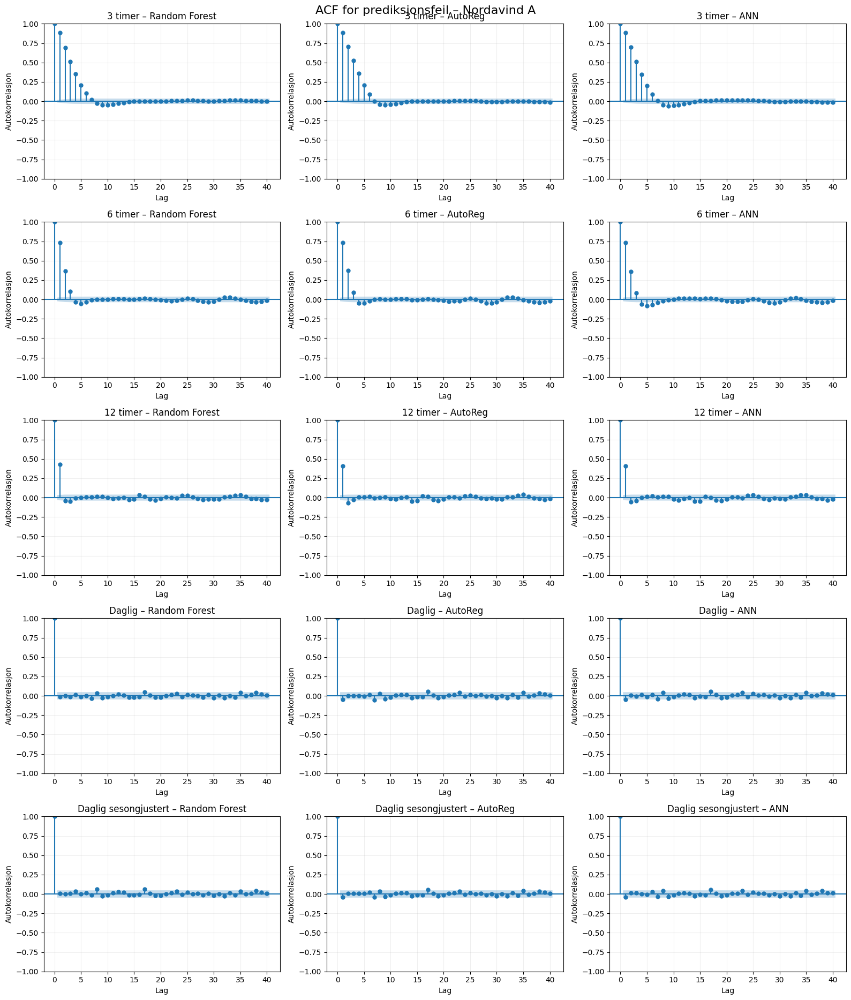

In [ ]:


fig, axes = plt.subplots(
    len(residuals_all),
    3,
    figsize=(16, 19)
)

for i, (resolution, df) in enumerate(
    residuals_all.items()
):

    for j, model in enumerate(
        ["Random Forest", "AutoReg", "ANN"]
    ):

        ax = axes[i, j]

        errors = df[model].dropna().to_numpy()

        plot_acf(
            errors,
            lags=40,
            ax=ax,
            alpha=0.05
        )

        ax.set_title(f"{resolution} – {model}")
        ax.set_xlabel("Lag")
        ax.set_ylabel("Autokorrelasjon")
        ax.grid(alpha=0.2)

plt.suptitle(
    "ACF for prediksjonsfeil – Nordavind A",
    fontsize=16
)

plt.tight_layout()
plt.show()

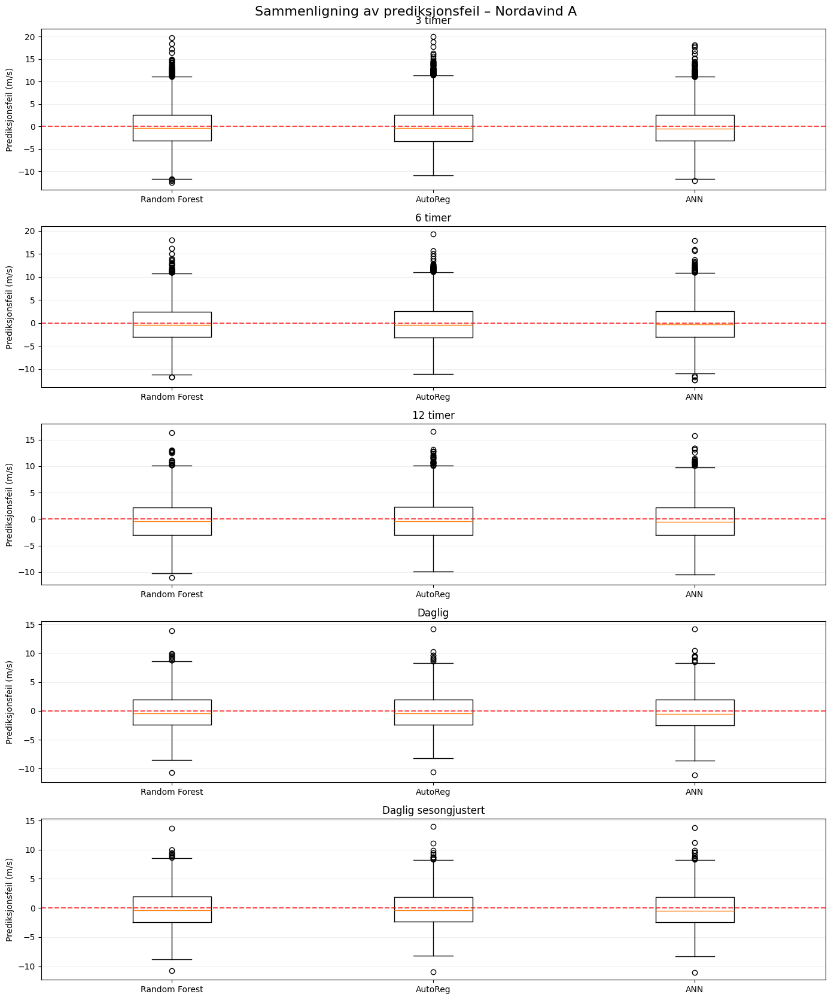

In [ ]:
fig, axes = plt.subplots(
    len(residuals_all),
    1,
    figsize=(14, 17)
)

for ax, (resolution, df) in zip(
    axes,
    residuals_all.items()
):

    available_models = [
        model for model in models
        if model in df.columns
    ]

    data = [
        df[model].dropna().to_numpy()
        for model in available_models
    ]

    ax.boxplot(
        data,
        tick_labels=available_models,
        showfliers=True
    )

    ax.axhline(
        0,
        color="red",
        linestyle="--",
        alpha=0.7
    )

    ax.set_title(resolution)
    ax.set_ylabel("Prediksjonsfeil (m/s)")
    ax.grid(axis="y", alpha=0.2)

plt.suptitle(
    "Sammenligning av prediksjonsfeil – Nordavind A",
    fontsize=16
)

plt.tight_layout()
plt.show()

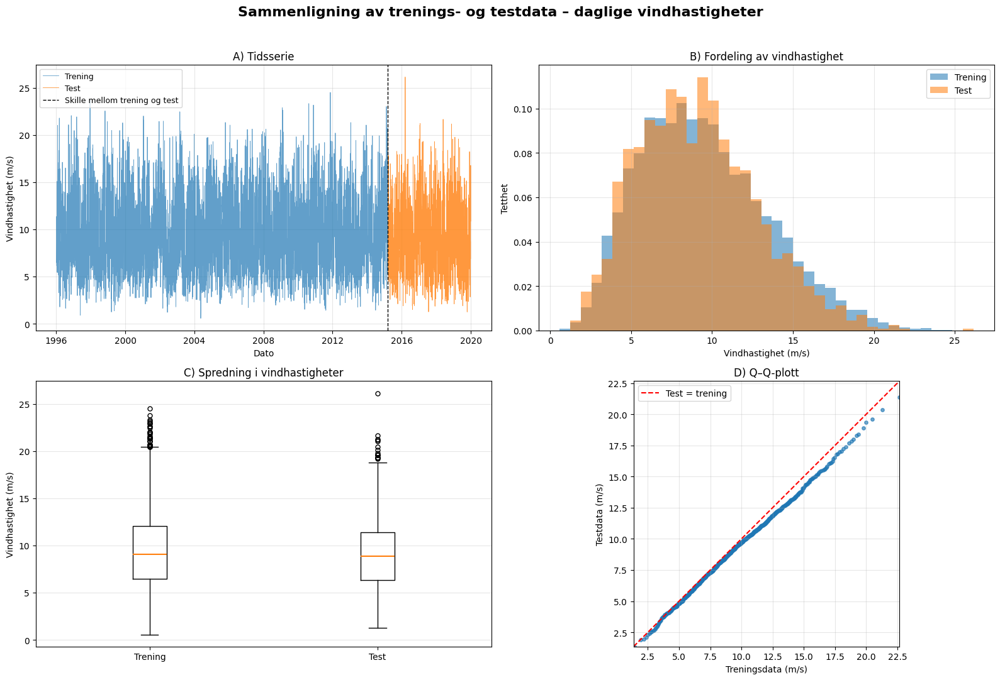

In [ ]:


# 1. Henting daglige data

train = train_test_data["Daglig"]["train"].copy()
test = train_test_data["Daglig"]["test"].copy()

y_train = train["target"].dropna().to_numpy()
y_test = test["target"].dropna().to_numpy()

# ==========================================
# 2. Opprett samlet figur
# ==========================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 11)
)

# ==========================================
# A. Tidsserie
# ==========================================

ax = axes[0, 0]

ax.plot(
    train["target_datetime"],
    train["target"],
    color="tab:blue",
    linewidth=0.6,
    alpha=0.7,
    label="Trening"
)

ax.plot(
    test["target_datetime"],
    test["target"],
    color="tab:orange",
    linewidth=0.6,
    alpha=0.8,
    label="Test"
)

ax.axvline(
    test["target_datetime"].iloc[0],
    color="black",
    linestyle="--",
    linewidth=1,
    label="Skille mellom trening og test"
)

ax.set_title("A) Tidsserie")
ax.set_xlabel("Dato")
ax.set_ylabel("Vindhastighet (m/s)")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

# ==========================================
# B. Histogram
# ==========================================

ax = axes[0, 1]

bins = np.linspace(
    min(y_train.min(), y_test.min()),
    max(y_train.max(), y_test.max()),
    40
)

ax.hist(
    y_train,
    bins=bins,
    density=True,
    alpha=0.55,
    color="tab:blue",
    label="Trening"
)

ax.hist(
    y_test,
    bins=bins,
    density=True,
    alpha=0.55,
    color="tab:orange",
    label="Test"
)

ax.set_title("B) Fordeling av vindhastighet")
ax.set_xlabel("Vindhastighet (m/s)")
ax.set_ylabel("Tetthet")
ax.legend()
ax.grid(alpha=0.3)

# ==========================================
# C. Boksplott med ekstremverdier
# ==========================================

ax = axes[1, 0]

ax.boxplot(
    [y_train, y_test],
    tick_labels=["Trening", "Test"],
    showfliers=True,
    boxprops=dict(color="black"),
    medianprops=dict(color="tab:orange", linewidth=1.5),
    whiskerprops=dict(color="black"),
    capprops=dict(color="black"),
    flierprops=dict(
        marker="o",
        markerfacecolor="none",
        markeredgecolor="black",
        markersize=5,
        linestyle="none"
    )
)

ax.set_title("C) Spredning i vindhastigheter")
ax.set_ylabel("Vindhastighet (m/s)")
ax.grid(axis="y", alpha=0.3)

# ==========================================
# D. Q-Q-plott
# ==========================================

ax = axes[1, 1]

quantiles = np.linspace(0.001, 0.999, 500)

x = np.quantile(y_train, quantiles)
y = np.quantile(y_test, quantiles)

ax.scatter(
    x,
    y,
    color="tab:blue",
    s=15,
    alpha=0.65
)

minimum = min(x.min(), y.min())
maksimum = max(x.max(), y.max())

ax.plot(
    [minimum, maksimum],
    [minimum, maksimum],
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Test = trening"
)

ax.set_xlim(minimum, maksimum)
ax.set_ylim(minimum, maksimum)

ax.set_title("D) Q–Q-plott")
ax.set_xlabel("Treningsdata (m/s)")
ax.set_ylabel("Testdata (m/s)")
ax.set_aspect("equal", adjustable="box")
ax.legend()
ax.grid(alpha=0.3)

# ==========================================
# 3. Formatering og lagring
# ==========================================

fig.suptitle(
    "Sammenligning av trenings- og testdata – daglige vindhastigheter",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(
    "train_test_daily_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "train_test_daily_comparison.pdf",
    bbox_inches="tight"
)

plt.show()